# Subclustering Endothelial cells

In [1]:
library(Signac)
library(Seurat)
library(rtracklayer)
library(dplyr)
library(Matrix)
library(ggplot2)
library(cowplot)
require(biomaRt)
library(DoubletFinder)
library(RColorBrewer)
library(stringr)
set.seed(1234)

Warning message:
“package ‘Signac’ was built under R version 4.3.3”
Warning message:
“package ‘Seurat’ was built under R version 4.3.3”
Loading required package: SeuratObject

Warning message:
“package ‘SeuratObject’ was built under R version 4.3.3”
Loading required package: sp

Warning message:
“package ‘sp’ was built under R version 4.3.3”

Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


Warning message:
“package ‘rtracklayer’ was built under R version 4.3.3”
Loading required package: GenomicRanges

Warning message:
“package ‘GenomicRanges’ was built under R version 4.3.3”
Loading required package: stats4

Loading required package: BiocGenerics

Warning message:
“package ‘BiocGenerics’ was built under R version 4.3.2”

Attaching package: ‘BiocGenerics’


The following object is masked from ‘package:SeuratObject’:

    intersect


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The fol

In [2]:
my_c <- c('#fe864a', '#c9d179', '#95d0fc', '#fbdd7e', '#388004', '#c760ff', '#76cd26', '#ffbacd', '#d6b4fc',
        '#cfaf7b','#8b88f8', '#acc2d9', '#894585', '#82cbb2', '#d99b82', '#fdee73', '#5170d7', '#ffd8b1', 
        '#b7e1a1', '#82a67d', '#b7fffa', '#b790d4', '#f5674a', '#C79FEF', '#DAA520', '#A0522D')

# Data loading

 This genes are the ones used to perform the aligment on CellRanger using the costumized genome reference *10X_ref_genome_plus_eGFP_CreERT*. It contains teh CreERT2 gene and e GFP gene.

In [ ]:
annotation <- import('genes2.gtf')

In [ ]:
annotation$gene_biotype[1:1780455] = annotation$gene_type[1:1780455]
seqlevelsStyle(annotation) <- "UCSC" #Support for other than Ensembl seqlevel style

In [5]:
annotation$tx_id = annotation$transcript_id

In [ ]:
#load fragments data
P11_sample1_frags <- 'P11_sample1_atac_fragments.tsv.gz'

P11_sample2_frags <- 'P11_sample2_atac_fragments.tsv.gz'

P11_sample3_frags <- 'P11_sample3_atac_fragments.tsv.gz'

P60_sample1_frags <- 'P60_sample1_atac_fragments.tsv.gz'

P60_sample2_frags <- 'P60_sample2_atac_fragments.tsv.gz'

P60_TTR_sample3_frags <- 'P60_TTR_sample3_atac_fragments.tsv.gz'

In [ ]:
sample_names <- c('P11_sample1', 'P11_sample2', 'P11_sample3', 'P60_sample1', 'P60_sample2', 'P60_TTR_sample3')

In [ ]:
frags_path <- c(P11_sample1_frags, P11_sample2_frags, P11_sample3_frags, P60_sample1_frags, P60_sample2_frags, 
           P60_TTR_sample3_frags)

In [ ]:
raw <- readRDS('Merged_multiome.rds')

In [ ]:
filtered <- readRDS('Integrated_multiome_clusters_joint_linked_cell_type.rds')

In [18]:
raw

An object of class Seurat 
195169 features across 53835 samples within 2 assays 
Active assay: ATAC (162882 features, 0 variable features)
 2 layers present: counts, data
 1 other assay present: RNA

In [19]:
filtered

An object of class Seurat 
215510 features across 39079 samples within 2 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: peaks
 10 dimensional reductions calculated: pca, umap, lsi, atac.umap, harmonyPeaks, harmony_Peaks, umapRNA, harmonyRNA, harmony_RNA, multiome.umap

# Subset data into only Endothelial cells

In [20]:
endo_filt <- subset(filtered, subset = predicted.id == 'Endothelial cells')

In [21]:
endo_filt

An object of class Seurat 
215510 features across 1764 samples within 2 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: peaks
 10 dimensional reductions calculated: pca, umap, lsi, atac.umap, harmonyPeaks, harmony_Peaks, umapRNA, harmonyRNA, harmony_RNA, multiome.umap

In [22]:
endo <- subset(raw, cells = rownames(endo_filt@meta.data))

In [23]:
endo

An object of class Seurat 
195169 features across 1764 samples within 2 assays 
Active assay: ATAC (162882 features, 0 variable features)
 2 layers present: counts, data
 1 other assay present: RNA

In [24]:
frags <- Fragments(endo)

In [25]:
Fragments(endo) <- NULL

In [26]:
for (i in 1:length(frags)){
    frags[[i]] <- UpdatePath(frags[[i]], new.path = frags_path[[i]])
}

Computing hash

Computing hash

Computing hash

Computing hash

Computing hash

Computing hash



In [27]:
Fragments(endo) <- frags

In [ ]:
saveRDS(endo, 'Endo_multiome.rds')

In [ ]:
endo <- readRDS('Endo_multiome.rds')

In [30]:
endo@assays

$RNA
Assay data with 32287 features for 1764 cells
First 10 features:
 Xkr4, Gm1992, Gm19938, Gm37381, Rp1, Sox17, Gm37587, Gm37323, Mrpl15,
Lypla1 

$ATAC
ChromatinAssay data with 162882 features for 1764 cells
Variable features: 0 
Genome: 
Annotation present: TRUE 
Motifs present: FALSE 
Fragment files: 6 


In [31]:
unique(endo$Sample)

[1] "P11_01_n00388"        "P11_02_n00388"        "P11_03_n00388"       
[4] "P60_05_n00388"        "P60_06_d05797"        "P60_TTR_07_06_n00388"

In [32]:
unique(endo$Age)

[1] "P11" "P60"

Warning message:
“Removed 50 rows containing non-finite outside the scale range (`stat_bin()`).”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range (`geom_bar()`).”
Warning message:
“Removed 50 rows containing non-finite outside the scale range (`stat_bin()`).”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range (`geom_bar()`).”


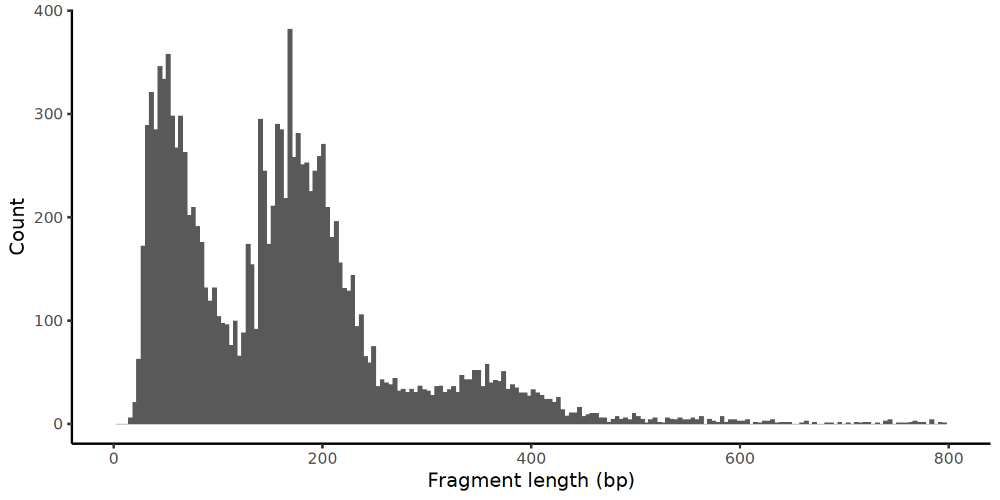

In [ ]:
options(repr.plot.width = 8, repr.plot.height = 4, repr.plot.res = 200)
endo$nucleosome_group <- ifelse(endo$nucleosome_signal > 2.0, 'NS > 2.0', 'NS < 2.0')

frag_hist <- FragmentHistogram(object = endo, group.by = 'nucleosome_group', region = 'chr1-1-10000000')

frag_hist

ggsave(file="Endo_frag_hist.svg", plot=frag_hist, width=8, height=4)

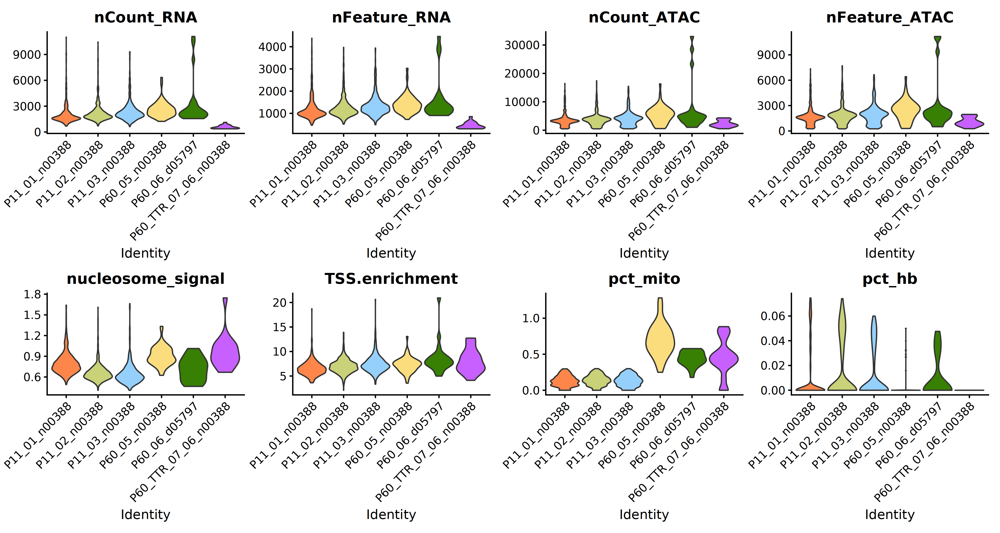

In [ ]:
options(repr.plot.width = 15, repr.plot.height = 8, repr.plot.res = 300)

vln <- VlnPlot(endo, features=c('nCount_RNA', 'nFeature_RNA', 'nCount_ATAC', 'nFeature_ATAC', 'nucleosome_signal', 'TSS.enrichment', 'pct_mito', 'pct_hb'), 
        ncol=4, pt.size=0, col = my_c) 

vln

ggsave(file="Endo_all_vln_prefilter.svg", plot=vln, width=15, height=8)


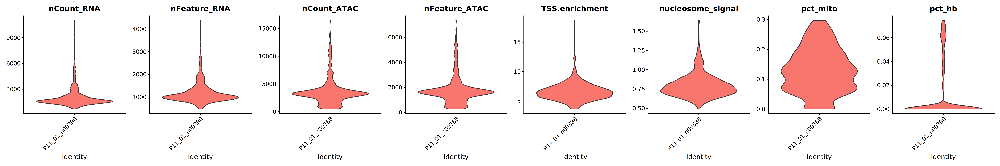

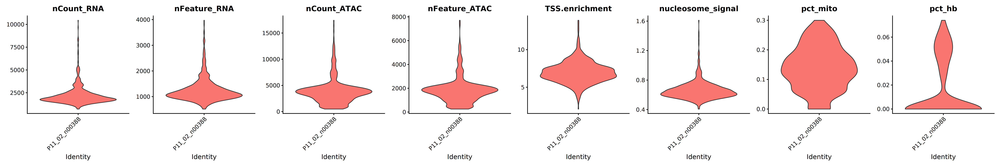

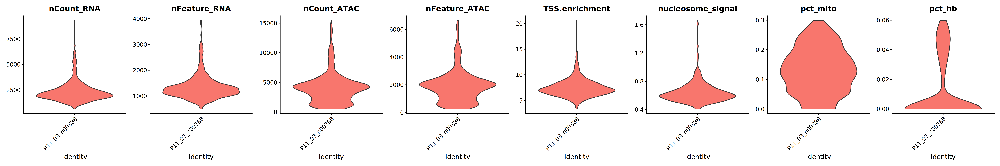

Warning message in SingleExIPlot(type = type, data = data[, x, drop = FALSE], idents = idents, :
“All cells have the same value of pct_hb.”


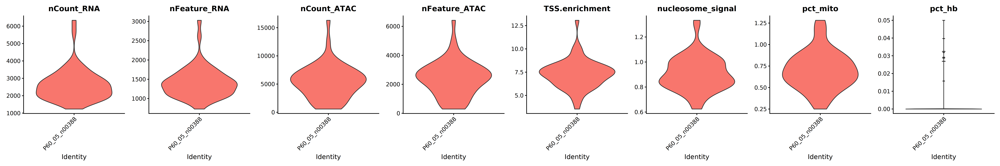

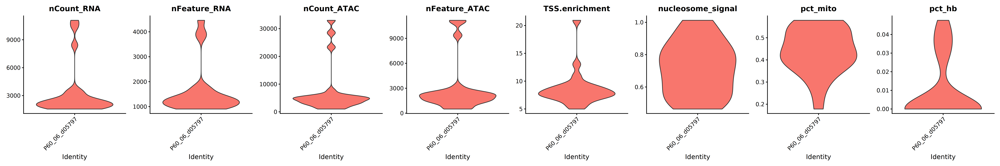

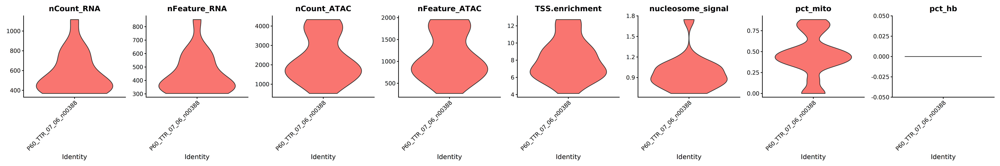

In [ ]:
options(repr.plot.width=30, repr.plot.height=5)
vlns_pre <- c()
for (sample in sample_names){
    s <- subset(endo, subset = Sample == sample)
    vln <- VlnPlot(object = s, features = c("nCount_RNA", "nFeature_RNA", "nCount_ATAC", "nFeature_ATAC", "TSS.enrichment", "nucleosome_signal", "pct_mito", "pct_hb"), 
                  ncol = 8, pt.size = 0)
    
    plot_name = paste("", sample, "_vln_prefilter.svg")

    print(vln)
    
    ggsave(file=plot_name, plot=vln, width=30, height=5)
    
    
}

# Filtering

In [36]:
table(endo$orig.ident)


       P11_01_n00388        P11_02_n00388        P11_03_n00388 
                 543                  654                  475 
       P60_05_n00388        P60_06_d05797 P60_TTR_07_06_n00388 
                  52                   23                   17 

In [37]:
DefaultAssay(endo) <- "RNA"

Since we already have the peaks assay we can delete the ATAC assay, which allows to save compuattional resources 

In [38]:
samples.list <- SplitObject(endo, split.by = 'Sample')

In [39]:
samples.list

$P11_01_n00388
An object of class Seurat 
195169 features across 543 samples within 2 assays 
Active assay: RNA (32287 features, 0 variable features)
 2 layers present: counts, data
 1 other assay present: ATAC

$P11_02_n00388
An object of class Seurat 
195169 features across 654 samples within 2 assays 
Active assay: RNA (32287 features, 0 variable features)
 2 layers present: counts, data
 1 other assay present: ATAC

$P11_03_n00388
An object of class Seurat 
195169 features across 475 samples within 2 assays 
Active assay: RNA (32287 features, 0 variable features)
 2 layers present: counts, data
 1 other assay present: ATAC

$P60_05_n00388
An object of class Seurat 
195169 features across 52 samples within 2 assays 
Active assay: RNA (32287 features, 0 variable features)
 2 layers present: counts, data
 1 other assay present: ATAC

$P60_06_d05797
An object of class Seurat 
195169 features across 23 samples within 2 assays 
Active assay: RNA (32287 features, 0 variable features)
 2 l

In [40]:
vars_to_regress <- c('Sample')

In [41]:
endo <- endo %>% 
                            NormalizeData(normalization.method = "LogNormalize", scale.factor = 10000) %>%
                            FindVariableFeatures(selection.method = "vst", nfeatures=4000, ) %>%
                            ScaleData() %>%
                            RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  Ror1, Gpc6, Mir100hg, Glis3, Sox5, Grip1, Shank2, Cacnb2, Plcl1, Mir99ahg 
	   Hs6st3, Magi2, Plce1, Otx2os1, Gm29266, Trpm3, Ptprd, Sobp, Stk39, Gucy1a2 
	   Pid1, Slc24a3, Fras1, Frmpd4, Dach1, Zfp385b, Npas3, Esrrg, Gmnc, Dgki 
Negative:  Flt1, Plcb1, Enpp2, Fosb, Ints6, Rhoj, Fbxl18, Arhgef7, F10, Dnah17 
	   Col4a1, Marc1, Bin3, Cox8b, Inhbb, Ivns1abp, Selplg, Igfbp3, Nup210l, Rrad 
	   Prkcg, Tbx21, Stc1, Plvap, Stum, Egr1, Scarb1, Manba, Fam78b, Cntd1 
PC_ 2 
Positive:  Piezo2, Plpp3, Plvap, Col4a1, Ivns1abp, Dgki, Car10, Agbl4, Plpp1, Htr2c 
	   Shank2, Tmem108, Gmnc, Prkd1, Frmpd4, Trpm3, Gm29266, Zfp385b, Otx2os1, Frem1 
	   Rmst, Asic2, Hs6st3, Magi2, Enpp2, Dcbld1, Fras1, Erbb4, Ehbp1, Dlgap1 
Negative:  Slc8a1, Pcsk5, Vegfc, Nebl, Mecom, Fn1, Eln, Fbln2, Ptprj, Jag1 
	   Fbln5, Gja5, Vim, Zeb2, Efna5, Mast4, Sema3g, Stmn2, Cxcl12, Cldn5 
	   Edn1, Tox2, Bmx, Atp13a3, Tec, Col18a1, Vwf, Foxp1, Specc1, Ptchd1 
PC_ 3 
Posit

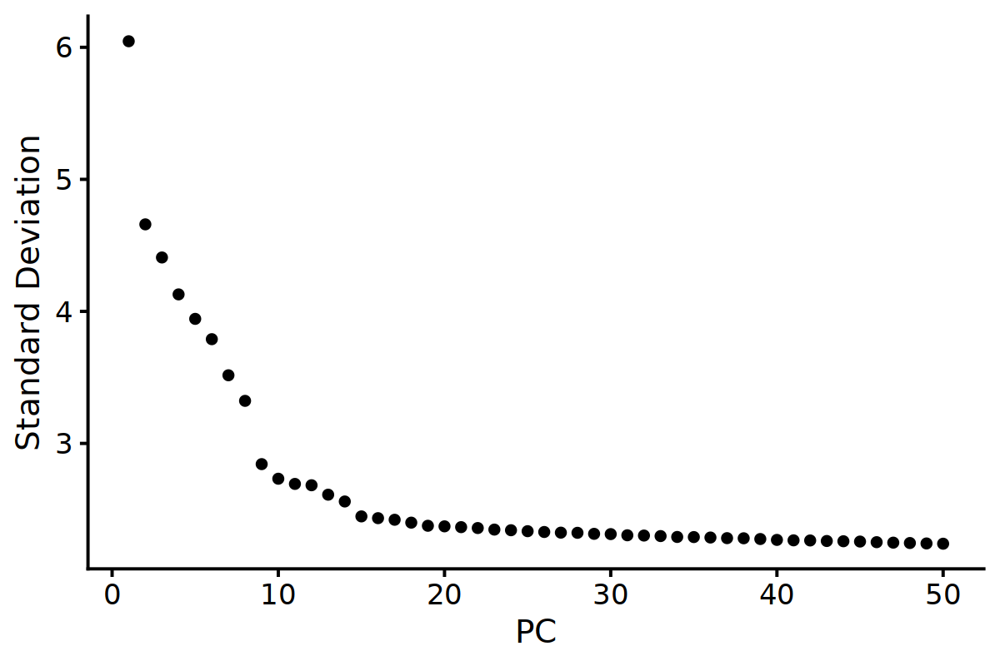

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
pca <- ElbowPlot(endo, ndims = 50)

pca

ggsave(file="Endo_bff_pca.svg", plot=pca, width=6, height=4)

In [43]:
endo <- RunUMAP(endo, dims = 1:14, reduction = 'pca', n.neighbors = 15)

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
12:27:36 UMAP embedding parameters a = 0.9922 b = 1.112

12:27:36 Read 1764 rows and found 14 numeric columns

12:27:36 Using Annoy for neighbor search, n_neighbors = 15

12:27:36 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

12:27:36 Writing NN index file to temp file /tmp/RtmptN7LGf/file21c0727a4846c

12:27:36 Searching Annoy index using 1 thread, search_k = 1500

12:27:36 Annoy recall = 100%

12:27:39 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors 

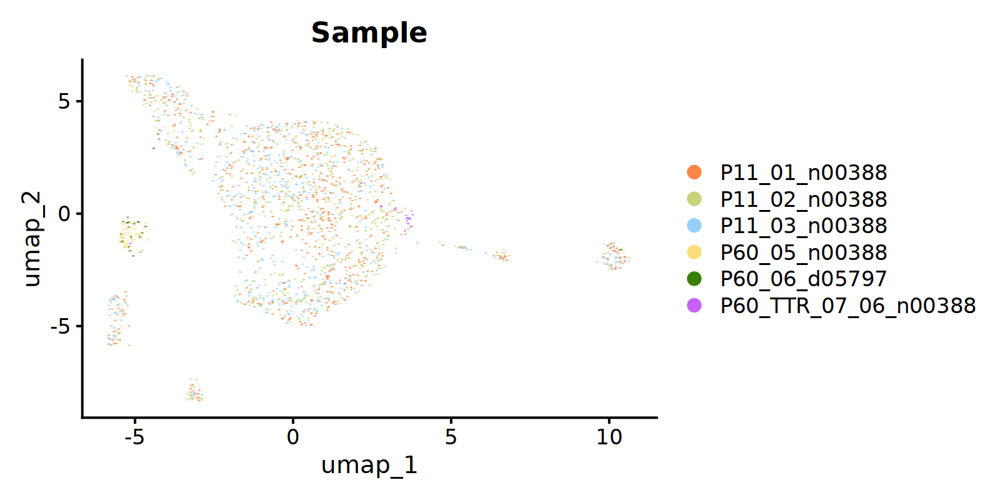

In [ ]:
options(repr.plot.width = 8, repr.plot.height = 4, repr.plot.res = 200)
dpl <- DimPlot(endo, reduction = 'umap', group.by = 'Sample', pt.size = 1.5, raster = TRUE, cols = my_c)

dpl

ggsave(file="Endo_bff_RNA_UMAP.svg", plot=dpl, width=8, height=4)

**NOTE**:The functions *get_density* and *DensityScatter* are from the packages Signac V 1.10, since we are using the version 1.4 we copied only the necessary function to plot the wanted plots.

In [45]:
get_density <- function(x, y, ...) {
  if (!requireNamespace("MASS", quietly = TRUE)) {
    stop("Please install MASS: install.packages('MASS')")
  }
  if (!is.numeric(x = x) | !is.numeric(x = y)) {
      stop("Must supply numeric values")
  }
  dens <- MASS::kde2d(x = x, y = y, ...)
  ix <- findInterval(x = x, vec = dens$x)
  iy <- findInterval(x = y, vec = dens$y)
  ii <- cbind(ix, iy)
  return(dens$z[ii])
}

In [46]:
DensityScatter <- function(
    object,
    x,
    y,
    log_x = FALSE,
    log_y = FALSE,
    quantiles = NULL
) {
    md <- object[[]]
    if (!(x %in% colnames(x = md))) {
        stop(x, " not found")
    }
    if (!(y %in% colnames(x = md))) {
        stop(y, " not found")
    }
    log10p <- function(x) {
        return(log10(x = x + 1))
    }
    null_fn <- function(x) {
        return(x)
    }
    logfnx <- ifelse(test = log_x, yes = log10p, no = null_fn)
    logfny <- ifelse(test = log_y, yes = log10p, no = null_fn)
    # logfny <- null_fn
    md$Density <- get_density(
        x = logfnx(md[[x]]),
        y = logfny(md[[y]]),
        n = 1000,
        h = c(1,1)
    )
    md <- md[order(md$Density), ]
    # quantiles
    use_quantile <- FALSE
    if (!is.null(x = quantiles)) {
        use_quantile <- TRUE
        # set default if TRUE passed
        if (is.logical(x = quantiles)) {
            if (quantiles) {
                quantiles <- c(5, 10, 90, 95)
            } else {
                use_quantile <- FALSE
            }
        }
        # make sure integers between 0 and 100
        if (!(all(quantiles >= 0) & all(quantiles <= 100))) {
            warning("Quantile values must be between 0 and 100",
                    immediate. = TRUE)
            use_quantile <- FALSE
        }
        if (any(sapply(X = quantiles, FUN = function(x) x %% 1 != 0))) {
            warning("Quantile values must be integers",
                    immediate. = TRUE)
            use_quantile <- FALSE
        }
    }
    if (use_quantile) {
        # convert to string
        quantiles <- paste0(quantiles, '%')

        # quantiles for x and y
        x_quant <- quantile(x = md[[x]], probs = seq(0, 1, 0.01))
        y_quant <- quantile(x = md[[y]], probs = seq(0, 1, 0.01))
        xlines <- x_quant[quantiles]
        ylines <- y_quant[quantiles]

        # round
        xlines <- round(x = xlines, digits = 2)
        ylines <- round(x = ylines, digits = 2)
    }        
    p <- ggplot(
           data = md,
           mapping = aes(x = .data[[x]], y = .data[[y]], color = .data[["Density"]])
         ) +
           geom_point(size = 1) +
           scale_color_viridis_c(option = "B") +
           theme_bw()
    if (log_x) {
        p <- p + scale_x_log10()
    }
    if (log_y) {
        p <- p + scale_y_log10()
    }
    if (use_quantile) {
        p <- p +
          geom_vline(xintercept = unname(obj = xlines), color = "red") +
          geom_hline(yintercept = unname(obj = ylines), color = "red") +
          labs(title = "Quantiles",
               subtitle = paste0(x, ": ", paste0(names(x = xlines), ":",
                                                 xlines, collapse = " "), "\n",
                                 y, ": ", paste0(names(x = ylines), ":",
                                                 ylines, collapse = " ")))
    }
    return(p)
}

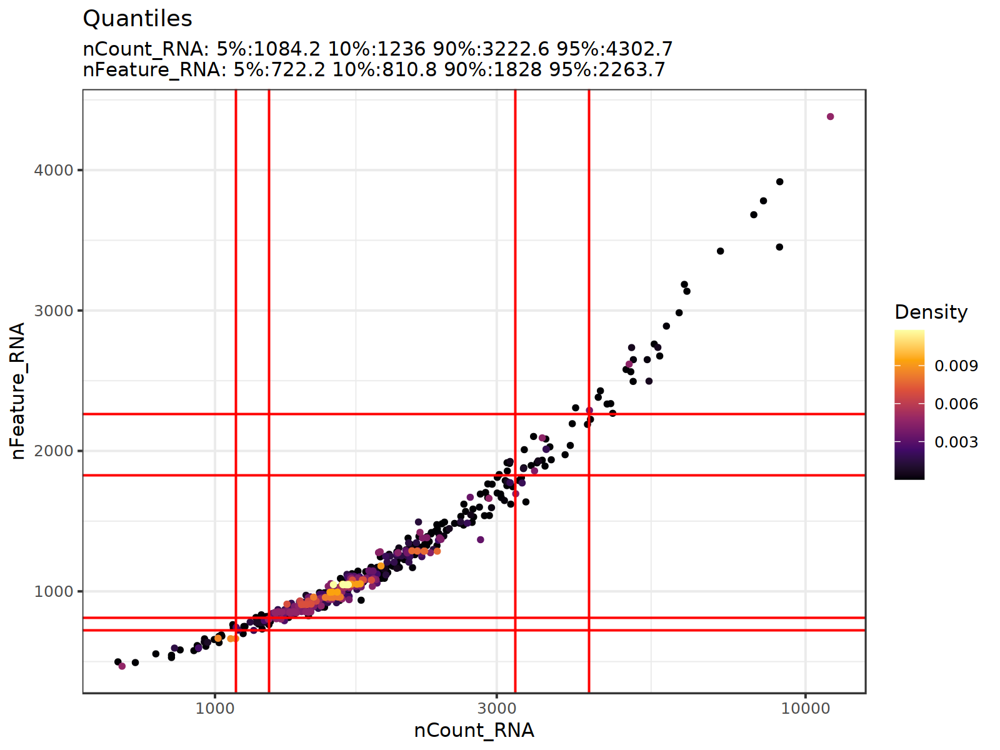

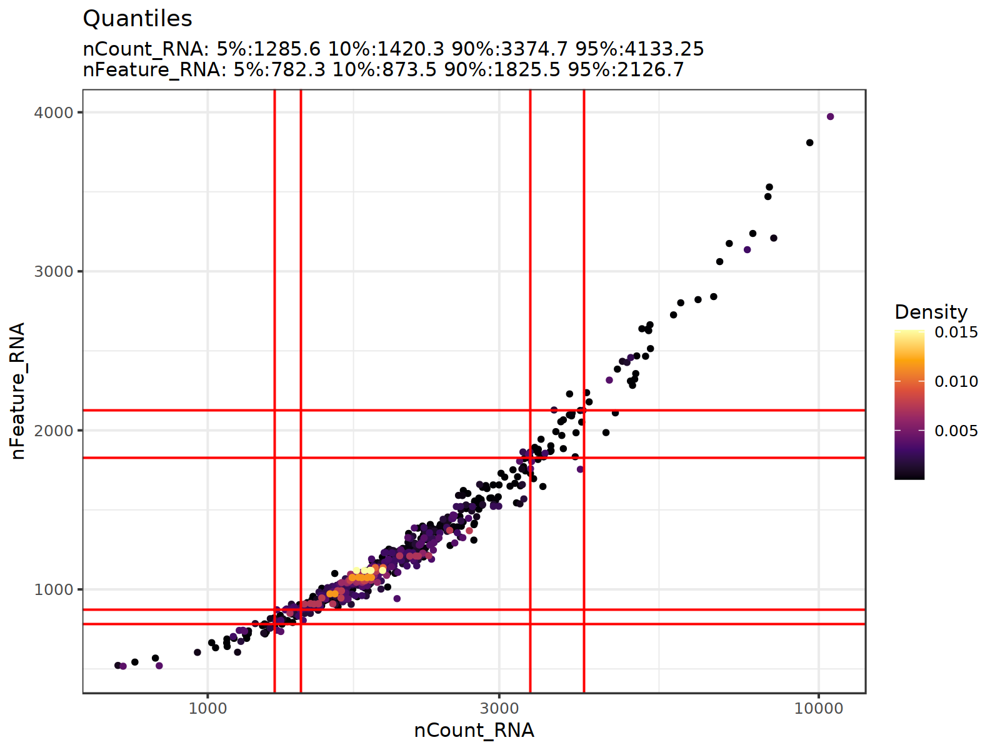

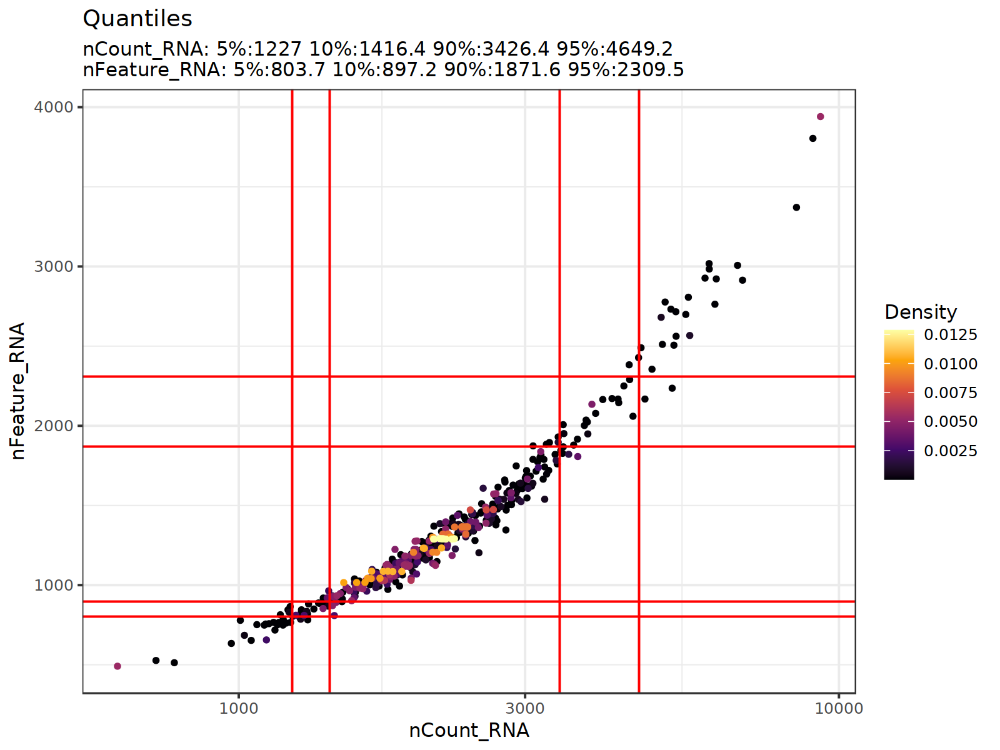

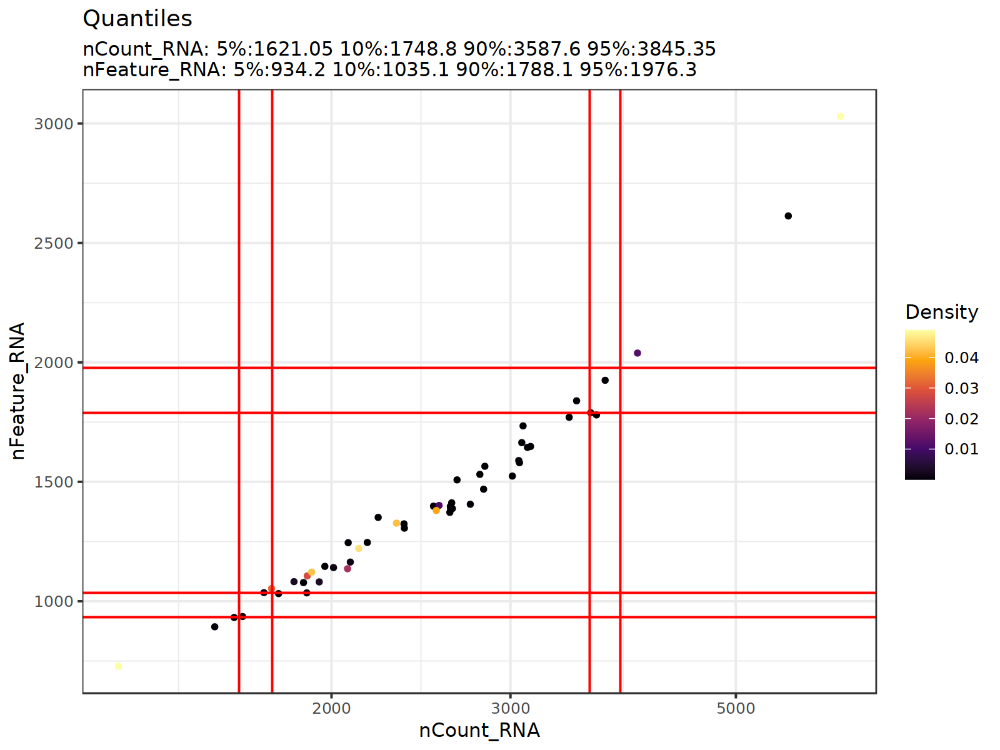

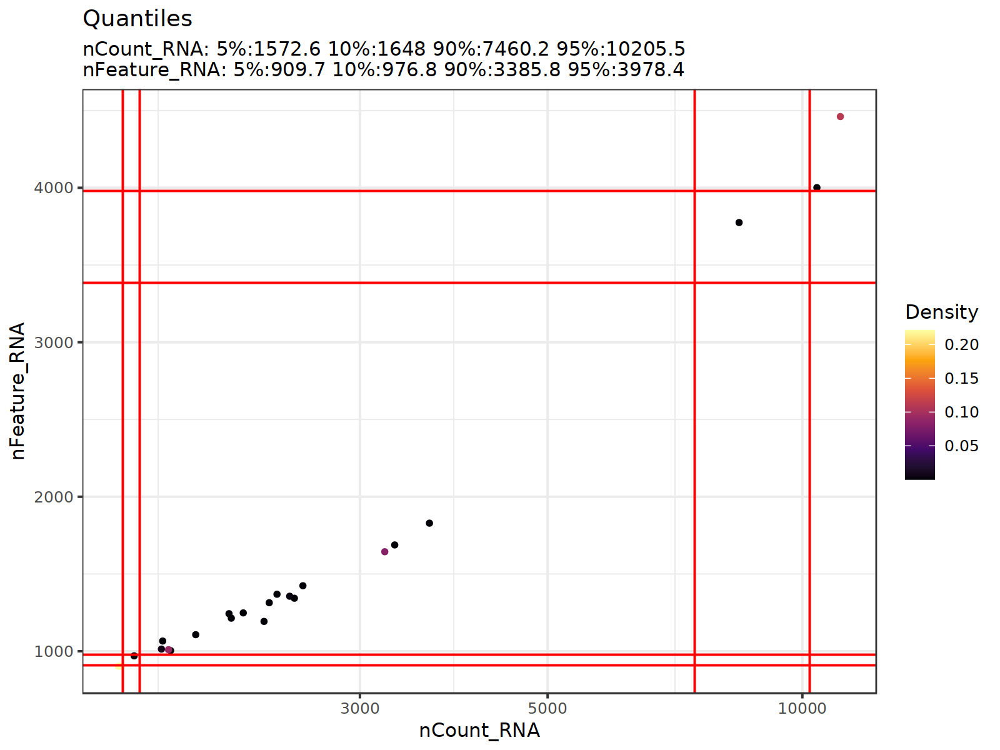

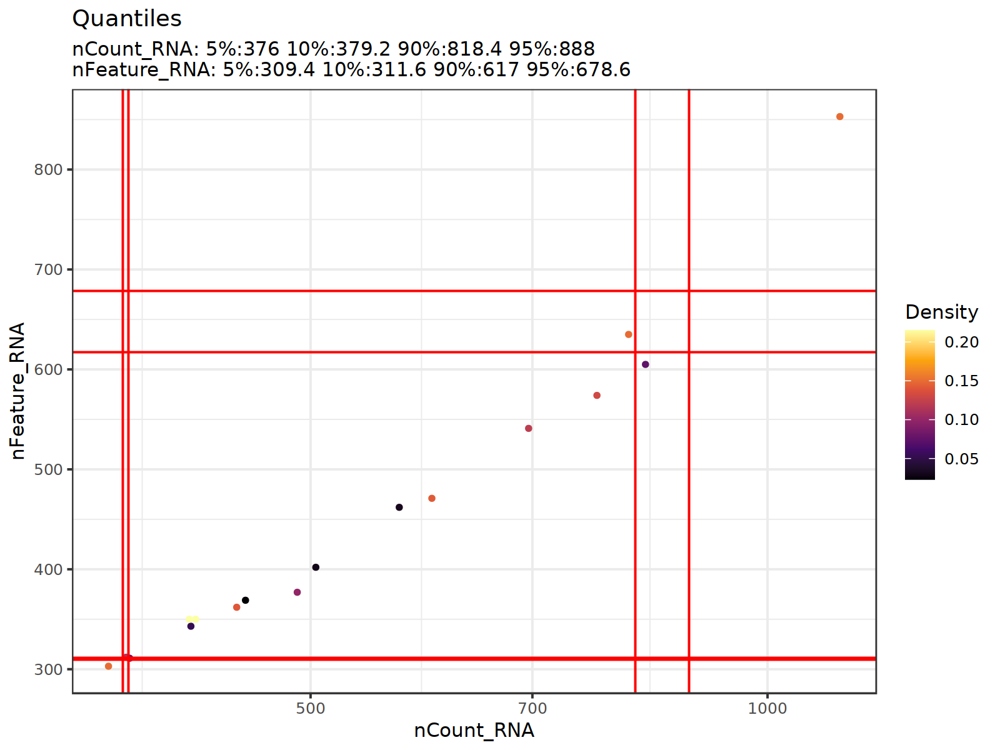

In [ ]:
options(repr.plot.width=30, repr.plot.height=5)
vlns_pre <- c()
for (sample in sample_names){
    s <- subset(endo, subset = Sample == sample)
    scatterplt <- DensityScatter(object = s, x = 'nCount_RNA', y = 'nFeature_RNA', log_x = TRUE, quantiles = TRUE)
    
    plot_name = paste("", sample, "Densenty_scatter_prefilter_nodbl_RNA.svg")
    #vlns_pre <- c(vlns_pre, vln)
    options(repr.plot.width = 8, repr.plot.height = 6)
    print(scatterplt)
    
    ggsave(file=plot_name, plot=scatterplt, width=8, height=6)
    
    
}

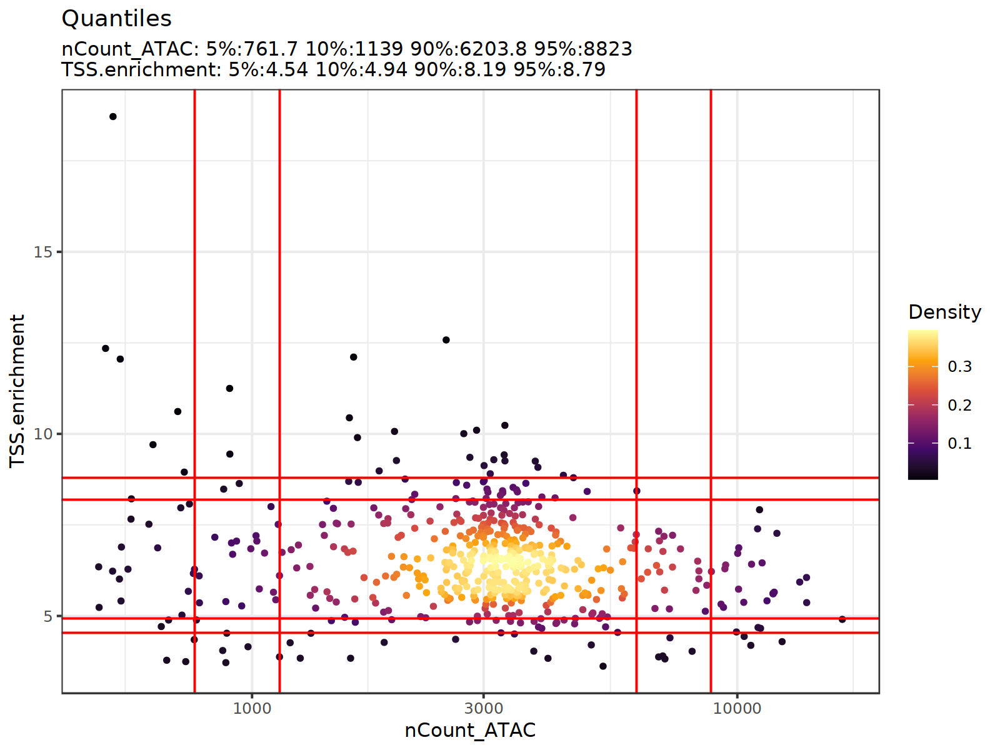

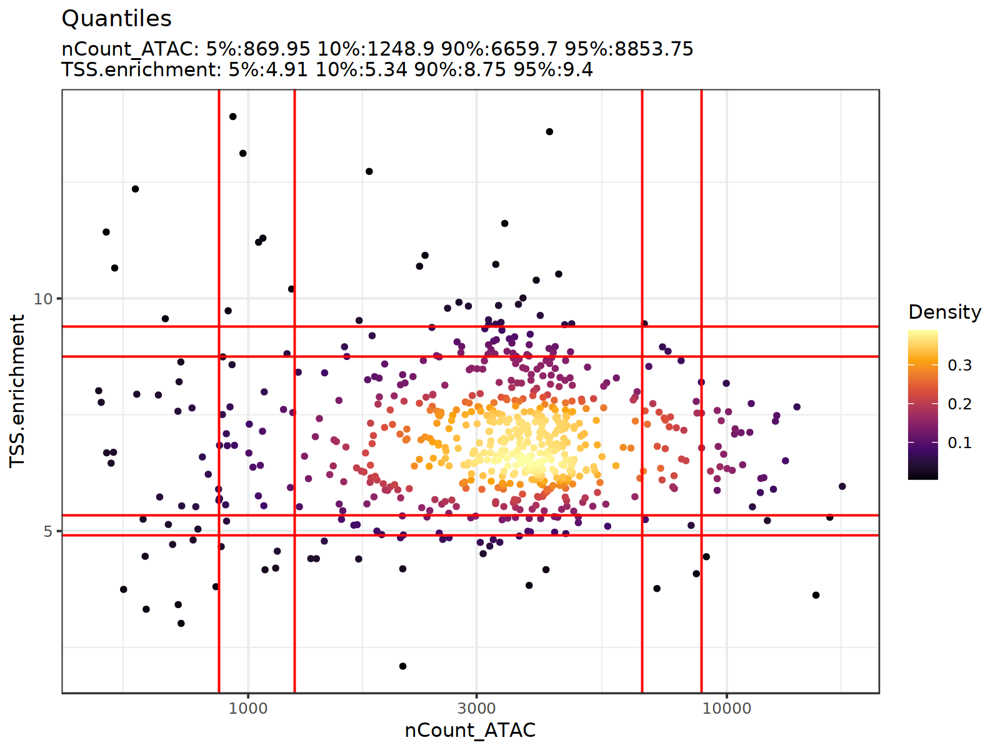

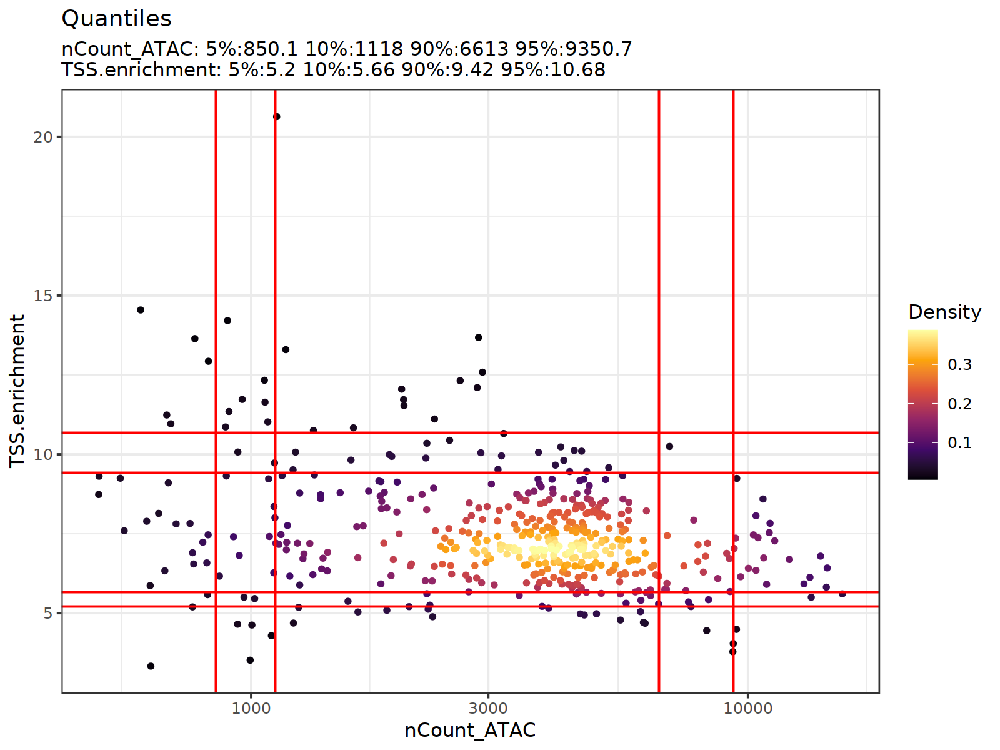

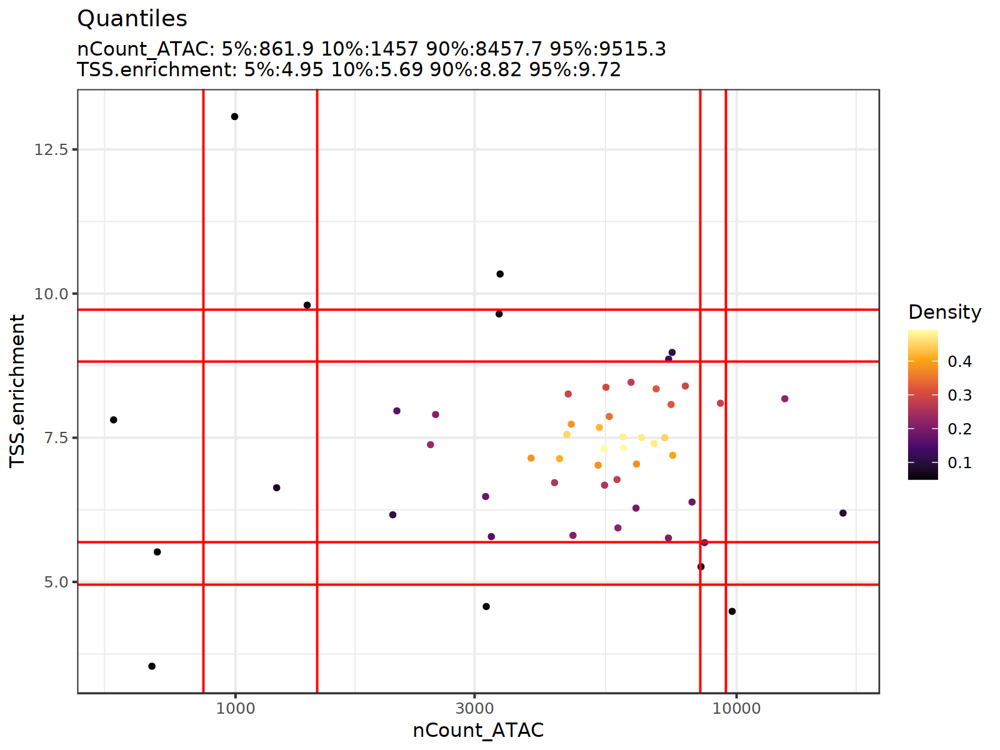

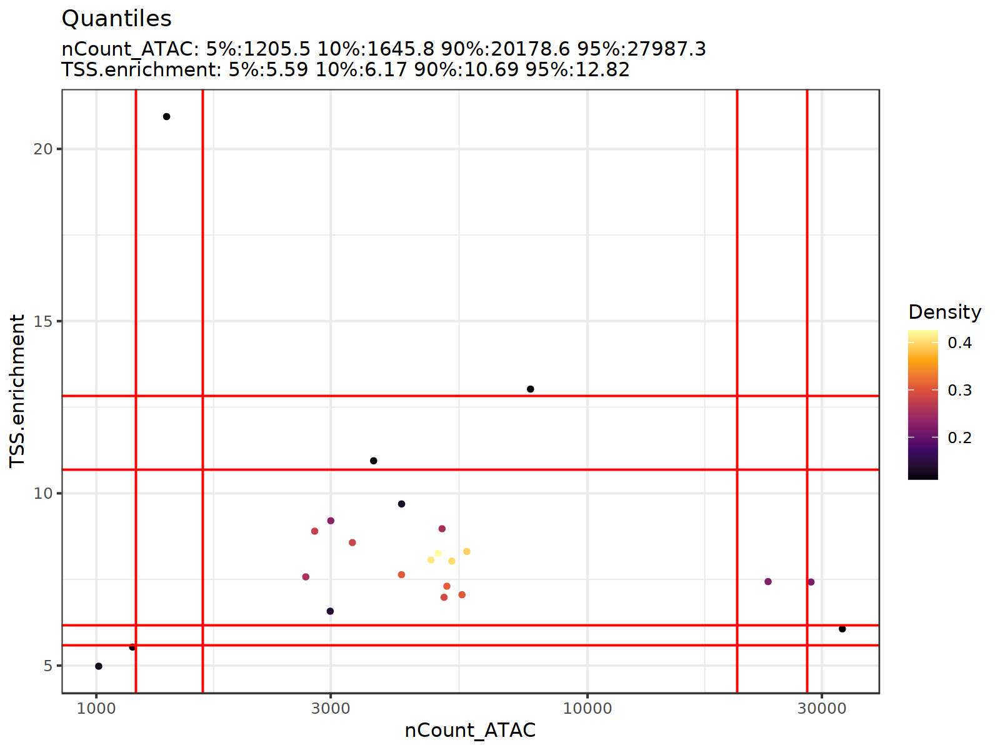

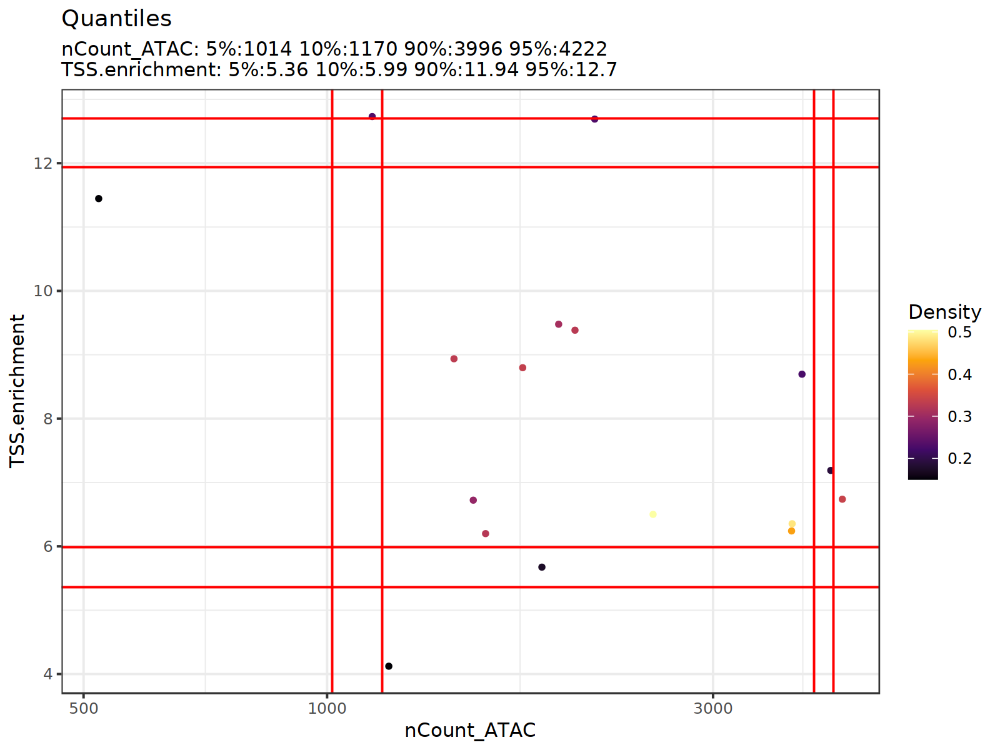

In [ ]:
options(repr.plot.width=30, repr.plot.height=5)
vlns_pre <- c()
for (sample in sample_names){
    s <- subset(endo, subset = Sample == sample)
    scatterplt <- DensityScatter(object = s, x = 'nCount_ATAC', y = 'TSS.enrichment', log_x = TRUE, quantiles = TRUE)
    
    plot_name = paste("", sample, "Densenty_scatter_prefilter_nodbl.svg")
    #vlns_pre <- c(vlns_pre, vln)
    options(repr.plot.width = 8, repr.plot.height = 6)
    print(scatterplt)
    
    ggsave(file=plot_name, plot=scatterplt, width=8, height=6)
    
    
}

In [50]:
nCount_RNA_max <- c(6000, 5500, 6000, 4500, 4500, 2000)

nCount_RNA_min <- c(250, 250, 250, 250, 250, 250)

nFeature_RNA_max <- c(2800, 3500, 3000, 2250, 2500, 1200)

nFeature_RNA_min <- c(250, 250, 250, 250, 250, 250)

nCount_ATAC_max <- c(12500, 14000, 15000, 17000, 10000, 6000)

nCount_ATAC_min <- c(400, 400, 400, 450, 600, 200)

nFeature_ATAC_max <- c(6000, 6000, 8000, 7000, 4500, 3000)

nFeature_ATAC_min <- c(250, 250, 250, 250, 250, 250)

nucleosome_signal_max <- c(2.0, 2.0, 2.0, 2.0, 2.0, 2.0)

TSS.enrichment_min <- c(2.0, 2.0, 2.0, 2.0, 2.0, 2.0) 

pct_mito_max <- c(0.3, 0.3, 0.3, 1.3, 0.7, 1.2) 

pct_hb_max <- c(0.075, 0.075, 0.06, 0.05, 0.06, 0.05)

In [51]:
options(repr.plot.width=30, repr.plot.height=5)
cells_to_keep <- c()

[1] "P11_01_n00388"
An object of class Seurat 
195169 features across 543 samples within 2 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: ATAC
 2 dimensional reductions calculated: pca, umap
[1] 6000
[1] 12500
[1] 250
[1] 400
[1] 2800
[1] 6000
[1] 250
[1] 250
[1] 2
[1] 2
[1] 0.3
[1] 0.075
[1] 530
[1] 530
[1] "P11_02_n00388"
An object of class Seurat 
195169 features across 654 samples within 2 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: ATAC
 2 dimensional reductions calculated: pca, umap
[1] 5500
[1] 14000
[1] 250
[1] 400
[1] 3500
[1] 6000
[1] 250
[1] 250
[1] 2
[1] 2
[1] 0.3
[1] 0.075
[1] 638
[1] 1168


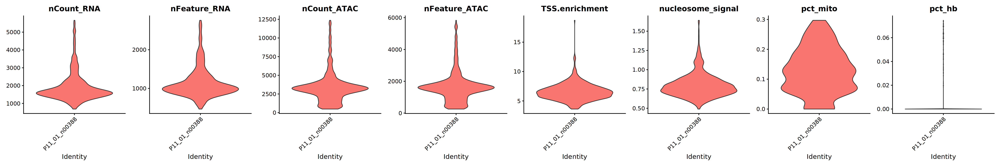

[1] "P11_03_n00388"
An object of class Seurat 
195169 features across 475 samples within 2 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: ATAC
 2 dimensional reductions calculated: pca, umap
[1] 6000
[1] 15000
[1] 250
[1] 400
[1] 3000
[1] 8000
[1] 250
[1] 250
[1] 2
[1] 2
[1] 0.3
[1] 0.06
[1] 465
[1] 1633


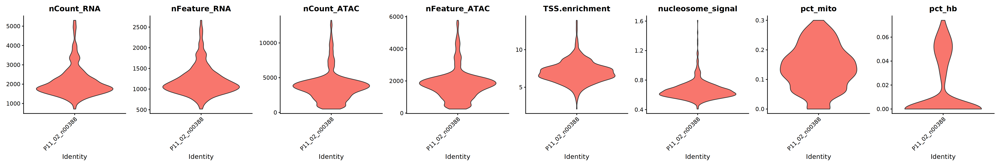

[1] "P60_05_n00388"
An object of class Seurat 
195169 features across 52 samples within 2 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: ATAC
 2 dimensional reductions calculated: pca, umap
[1] 4500
[1] 17000
[1] 250
[1] 450
[1] 2250
[1] 7000
[1] 250
[1] 250
[1] 2
[1] 2
[1] 1.3
[1] 0.05
[1] 50
[1] 1683


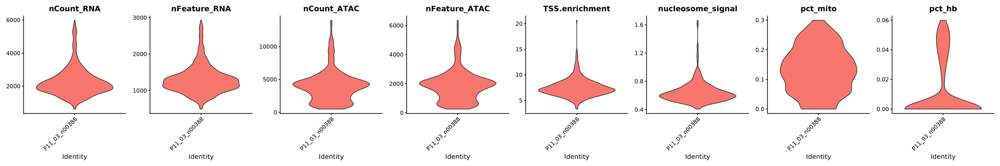

[1] "P60_06_d05797"
An object of class Seurat 
195169 features across 23 samples within 2 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: ATAC
 2 dimensional reductions calculated: pca, umap
[1] 4500
[1] 10000
[1] 250
[1] 600
[1] 2500
[1] 4500
[1] 250
[1] 250
[1] 2
[1] 2
[1] 0.7
[1] 0.06
[1] 20
[1] 1703
[1] "P60_TTR_07_06_n00388"
An object of class Seurat 
195169 features across 17 samples within 2 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: ATAC
 2 dimensional reductions calculated: pca, umap
[1] 2000
[1] 6000
[1] 250
[1] 200
[1] 1200
[1] 3000
[1] 250
[1] 250
[1] 2
[1] 2
[1] 1.2
[1] 0.05
[1] 17
[1] 1720


Warning message in SingleExIPlot(type = type, data = data[, x, drop = FALSE], idents = idents, :
“All cells have the same value of pct_hb.”


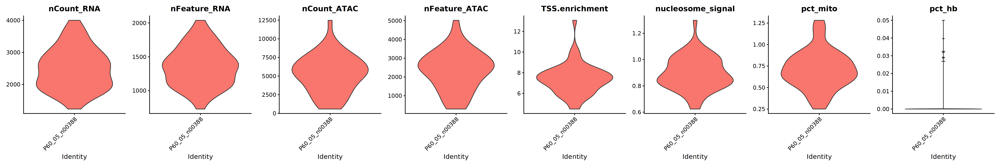

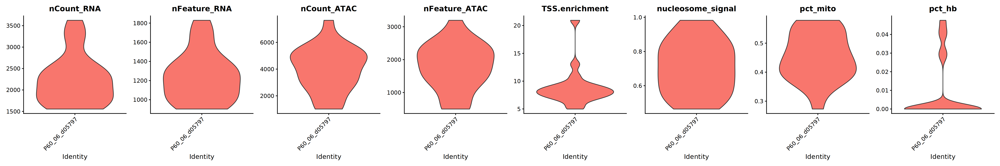

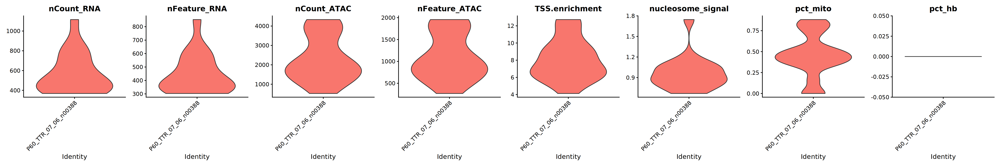

In [ ]:
for (i in 1:length(sample_names)){
    sample <- sample_names[i]
    print(sample)

    s <- subset(endo, subset = Sample == sample)

    print(s)
    
    print(nCount_RNA_max[i])
    print(nCount_ATAC_max[i])
    print(nCount_RNA_min[i])
    print(nCount_ATAC_min[i])
    print(nFeature_RNA_max[i])
    print(nFeature_ATAC_max[i])
    print(nFeature_RNA_min[i])
    print(nFeature_ATAC_min[i])
    print(nucleosome_signal_max[i])
    print(TSS.enrichment_min[i])
    print(pct_mito_max[i])
    print(pct_hb_max[i])
      
      
    s <-  subset(s, subset=nCount_RNA < nCount_RNA_max[i] &
                      nCount_ATAC < as.numeric(nCount_ATAC_max[i]) &
                      nCount_RNA > as.numeric(nCount_RNA_min[i]) &
                      nCount_ATAC > as.numeric(nCount_ATAC_min[i]) &
                      nFeature_RNA < as.numeric(nFeature_RNA_max[i]) &
                      nFeature_ATAC < as.numeric(nFeature_ATAC_max[i]) &
                      nFeature_RNA > as.numeric(nFeature_RNA_min[i]) &
                      nFeature_ATAC > as.numeric(nFeature_ATAC_min[i]) &
                      nucleosome_signal < as.numeric(nucleosome_signal_max[i]) &
                      TSS.enrichment > as.numeric(TSS.enrichment_min[i]) &
                      pct_mito < as.numeric(pct_mito_max[i]) &
                      pct_hb < as.numeric(pct_hb_max[i]))
    
    cells_to_keep <- c(cells_to_keep, colnames(s))
    
    print(length(colnames(s)))
    print(length(cells_to_keep))
    
    vln <- VlnPlot(object = s, features = c("nCount_RNA", "nFeature_RNA", "nCount_ATAC", "nFeature_ATAC", "TSS.enrichment", "nucleosome_signal", "pct_mito", "pct_hb"), 
                  ncol = 8, pt.size = 0)
    
    print(vln)

    plot_name = paste("", sample, "_vln_afterfilter.svg")

    
    ggsave(file=plot_name, plot=vln, width=30, height=5)
    
}

In [53]:
length(cells_to_keep)

[1] 1720

In [54]:
endo

An object of class Seurat 
195169 features across 1764 samples within 2 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: ATAC
 2 dimensional reductions calculated: pca, umap

In [55]:
endo_filt <- subset(endo, cells = cells_to_keep)

In [56]:
length(colnames(endo_filt))

[1] 1720

In [57]:
length(unique(colnames(endo_filt)))

[1] 1720

In [58]:
table(endo_filt$orig.ident)


       P11_01_n00388        P11_02_n00388        P11_03_n00388 
                 530                  638                  465 
       P60_05_n00388        P60_06_d05797 P60_TTR_07_06_n00388 
                  50                   20                   17 

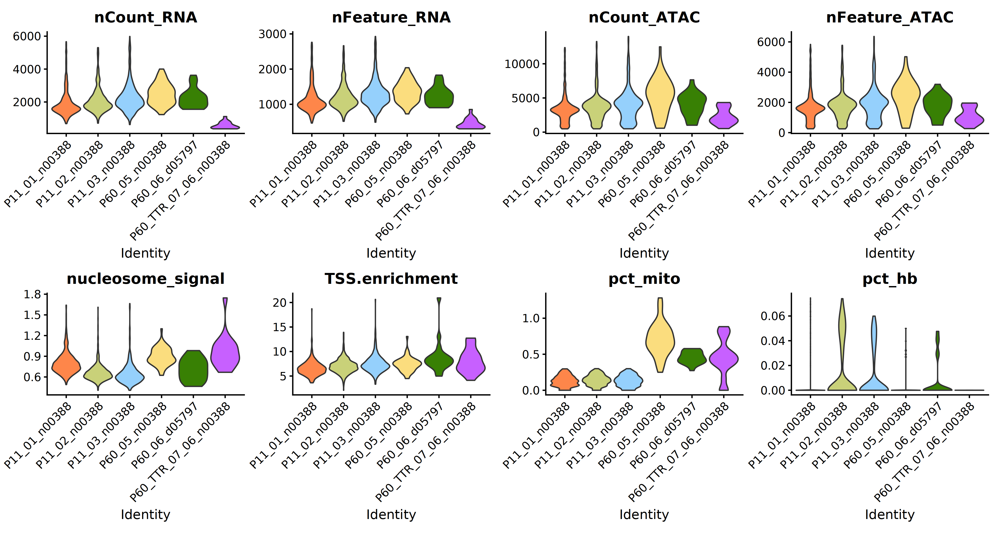

In [ ]:
options(repr.plot.width = 15, repr.plot.height = 8, repr.plot.res = 300)

vln <- VlnPlot(endo_filt, features=c('nCount_RNA', 'nFeature_RNA', 'nCount_ATAC', 'nFeature_ATAC', 'nucleosome_signal', 'TSS.enrichment', 'pct_mito', 'pct_hb'), 
        ncol=4, pt.size=0, col = my_c) 

vln

ggsave(file="Endo_all_vln_after_filter.svg", plot=vln, width=15, height=8)


In [ ]:
saveRDS(endo_filt, 'Endo_filt_multiome.rds')

# Call peaks

In [ ]:
endo_filt <- readRDS('Endo_filt_multiome.rds')

In [11]:
endo_filt

An object of class Seurat 
195169 features across 1720 samples within 2 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: ATAC
 2 dimensional reductions calculated: pca, umap

In [12]:
DefaultAssay(endo_filt) <- 'ATAC'

In [13]:
# call peaks using MACS2
peaks <- CallPeaks(object=endo_filt, 
                outdir='callpeaks', cleanup=FALSE)

In [14]:
# remove peaks on nonstandard chromosomes and in genomic blacklist regions
peaks <- keepStandardChromosomes(peaks, pruning.mode = "coarse")
peaks <- subsetByOverlaps(peaks, ranges = blacklist_mm10, invert = TRUE)

In [15]:
macs2_counts <- FeatureMatrix(fragments = Fragments(endo_filt), features = peaks, cells = colnames(endo_filt))

Extracting reads overlapping genomic regions

Extracting reads overlapping genomic regions

Extracting reads overlapping genomic regions

Extracting reads overlapping genomic regions

Extracting reads overlapping genomic regions

Extracting reads overlapping genomic regions



In [16]:
endo_filt[['peaks']] <- CreateChromatinAssay(counts = macs2_counts, sep = c('-', '-'), fragments = Fragments(endo_filt), annotation = annotation)

In [17]:
endo_filt@assays

$RNA
Assay data with 32287 features for 1720 cells
Top 10 variable features:
 Gpc6, Trpm3, Rgs5, Htr2c, Kirrel3, Slc8a1, Selp, Lsamp, Dach1, Pcdh9 

$ATAC
ChromatinAssay data with 162882 features for 1720 cells
Variable features: 0 
Genome: 
Annotation present: TRUE 
Motifs present: FALSE 
Fragment files: 6 

$peaks
ChromatinAssay data with 183223 features for 1720 cells
Variable features: 0 
Genome: 
Annotation present: TRUE 
Motifs present: FALSE 
Fragment files: 6 


In [18]:
DefaultAssay(endo_filt) <- 'peaks'

In [19]:
endo_filt[['ATAC']] <- NULL

# FRiP

In [20]:
endo_filt <- FRiP(endo_filt, assay = 'peaks', total.fragments = "nCount_ATAC", col.name = 'FRiP', verbose = TRUE)

Calculating fraction of reads in peaks per cell



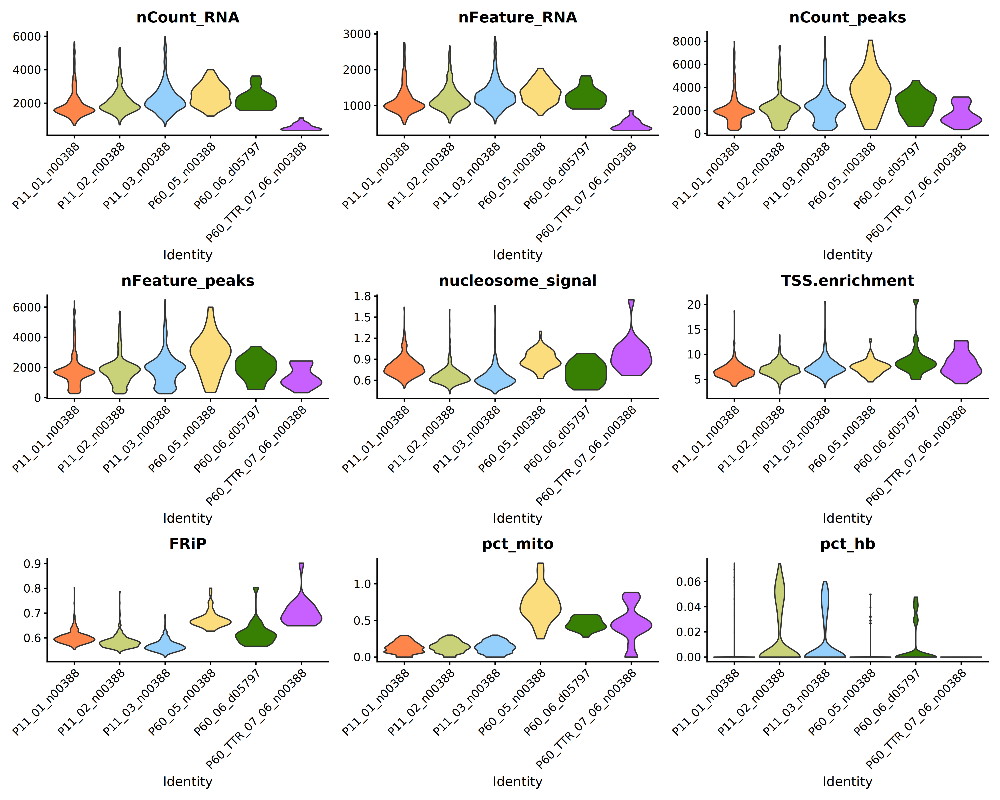

In [ ]:
options(repr.plot.width = 15, repr.plot.height = 12, repr.plot.res = 300)

vln <- VlnPlot(endo_filt, features=c('nCount_RNA', 'nFeature_RNA', 'nCount_peaks', 'nFeature_peaks', 'nucleosome_signal', 'TSS.enrichment', 'FRiP', 'pct_mito', 'pct_hb'), 
        ncol=3, pt.size=0, col = my_c) 

vln

ggsave(file="Endothelial_endo_filt_vln_pre_filter_frip.svg", plot=vln, width=15, height=12)


In [ ]:
saveRDS(endo_filt, 'Endothelial_endo_filt_multiome_peaks.rds')

# Downstream analysis

In [ ]:
endo_filt <- readRDS('Endothelial_endo_filt_multiome_peaks.rds')

In [9]:
endo_filt

An object of class Seurat 
215510 features across 1720 samples within 2 assays 
Active assay: peaks (183223 features, 0 variable features)
 2 layers present: counts, data
 1 other assay present: RNA
 2 dimensional reductions calculated: pca, umap

In [10]:
DefaultAssay(endo_filt) <- "RNA"

## RNA

In [11]:
endo_filt@assays

$RNA
Assay data with 32287 features for 1720 cells
Top 10 variable features:
 Gpc6, Trpm3, Rgs5, Htr2c, Kirrel3, Slc8a1, Selp, Lsamp, Dach1, Pcdh9 

$peaks
ChromatinAssay data with 183223 features for 1720 cells
Variable features: 0 
Genome: 
Annotation present: TRUE 
Motifs present: FALSE 
Fragment files: 6 


In [12]:
table(endo_filt$orig.ident)


       P11_01_n00388        P11_02_n00388        P11_03_n00388 
                 530                  638                  465 
       P60_05_n00388        P60_06_d05797 P60_TTR_07_06_n00388 
                  50                   20                   17 

In [13]:
vars_to_regress <- c('Sample')

In [14]:
endo_filt <- endo_filt %>% 
                            NormalizeData(normalization.method = "LogNormalize", scale.factor = 10000) %>%
                            FindVariableFeatures(selection.method = "vst", nfeatures=4000, ) %>%
                            ScaleData(vars.to.regress = vars_to_regress) %>%
                            RunPCA() 

Regressing out Sample

Centering and scaling data matrix

PC_ 1 
Positive:  Mecom, Slc8a1, Eln, Nebl, Vwf, Mir100hg, Vegfc, Mir99ahg, Pcsk5, Efna5 
	   Fn1, Dach1, Dach2, Dst, Frmd5, Ptprj, Foxp1, Plcl1, Col5a2, Nrxn3 
	   Gpc6, Zeb2, Glis3, Ror1, St6gal1, Pknox2, Ralgapa2, Sox5, Mast4, Tox 
Negative:  Col4a1, Flt1, Ivns1abp, Igfbp3, Plcb1, Arhgef7, Plpp3, Plvap, Fbxl18, Ints6 
	   Scarb1, Piezo2, Ednrb, Nup210l, Col13a1, Kcnk5, Kcnq1, Rell1, Evl, Thbs1 
	   Prkd1, Fosb, Inhbb, Hecw2, Esm1, Cdc42ep3, Gpihbp1, Samd4, Dcbld1, Rhoj 
PC_ 2 
Positive:  Slc8a1, Pcsk5, Nebl, Vegfc, Mecom, Fbln2, Fbln5, Ptprj, Fn1, Eln 
	   Sema3g, Efna5, Gja5, Jag1, Stmn2, Atp13a3, Tox2, Mast4, Cxcl12, Bmx 
	   Edn1, Cldn5, Specc1, Vim, Tec, Col18a1, Ptchd1, Ccdc88c, Cyth3, Creb5 
Negative:  Piezo2, Col4a1, Plpp3, Plpp1, Plvap, Ivns1abp, Prkd1, Kdr, Pde7b, Trp53i11 
	   Snrk, Ralgps2, Tmtc2, Dcbld1, Fmnl2, Aplnr, Ccdc85a, Emcn, Chrm2, Top2a 
	   Hecw2, Cenpp, Oxr1, Knl1, Ehbp1, Nrp1, Kif15, Arhgap18, Diaph3, 

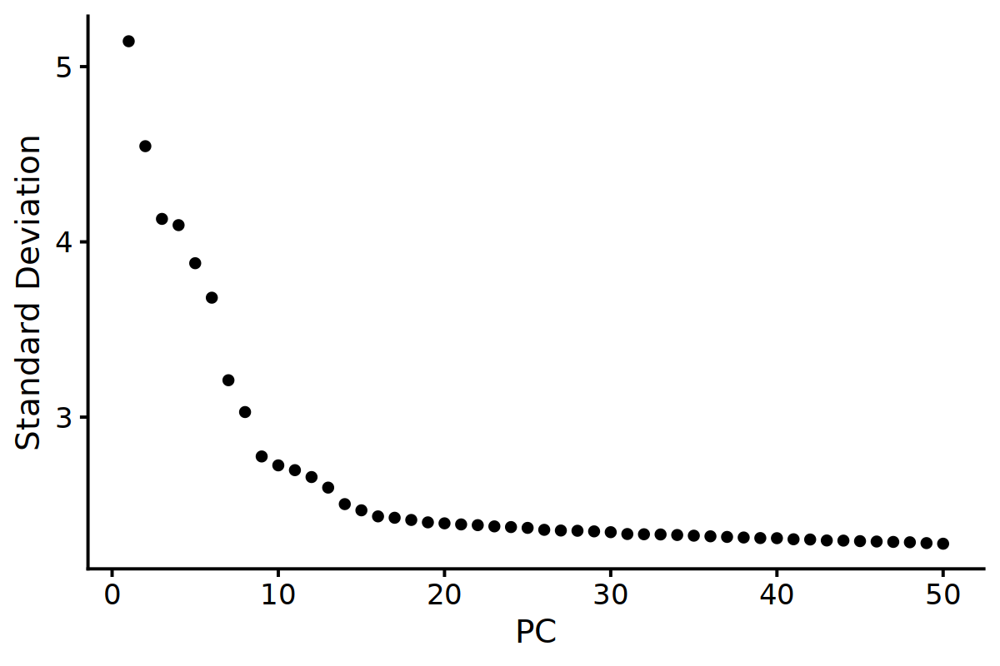

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
pca <- ElbowPlot(endo_filt, ndims = 50)

pca

ggsave(file="Endo_aff_pca.svg", plot=pca, width=6, height=4)

In [16]:
endo_filt <- RunUMAP(endo_filt, dims = 1:15, reduction = 'pca', n.neighbors = 15, reduction.name="umap_RNA")

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
21:12:31 UMAP embedding parameters a = 0.9922 b = 1.112

21:12:31 Read 1720 rows and found 15 numeric columns

21:12:31 Using Annoy for neighbor search, n_neighbors = 15

21:12:31 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

21:12:31 Writing NN index file to temp file /tmp/RtmpVf3X1a/file6fa2c5449f52e

21:12:31 Searching Annoy index using 1 thread, search_k = 1500

21:12:31 Annoy recall = 100%

21:12:32 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors 

In [17]:
unique(endo_filt$Age)

[1] "P11" "P60"

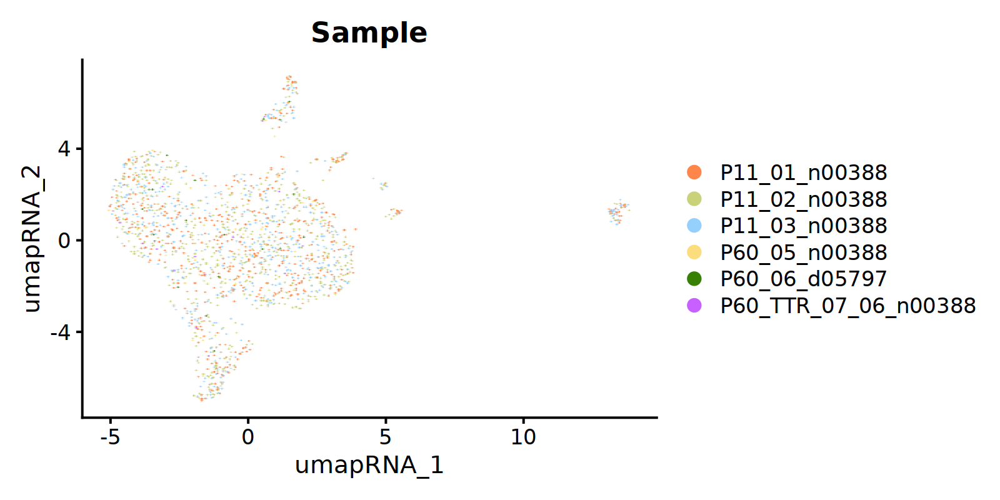

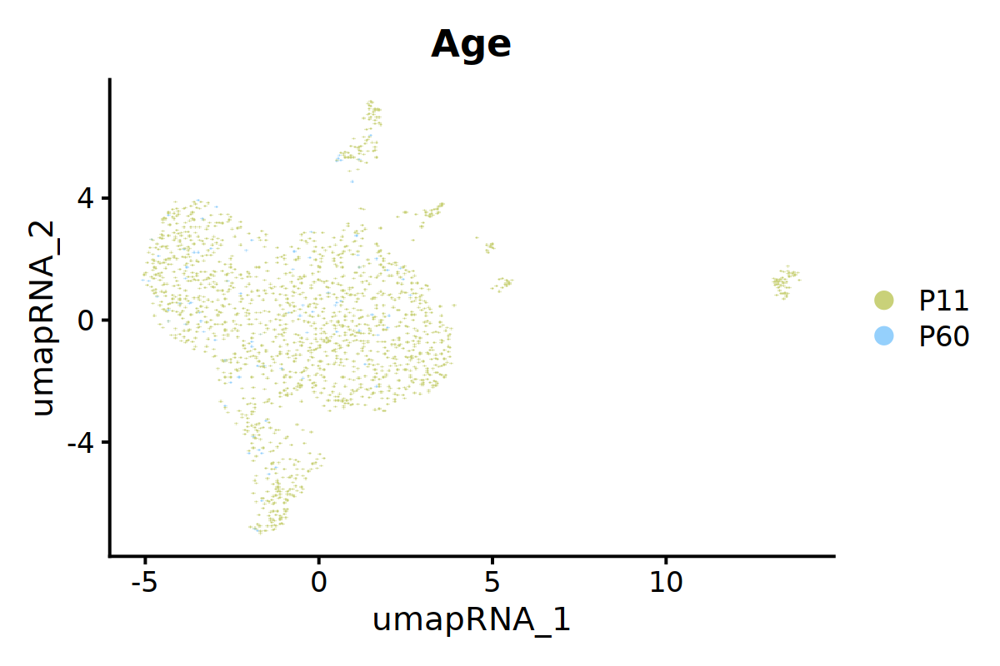

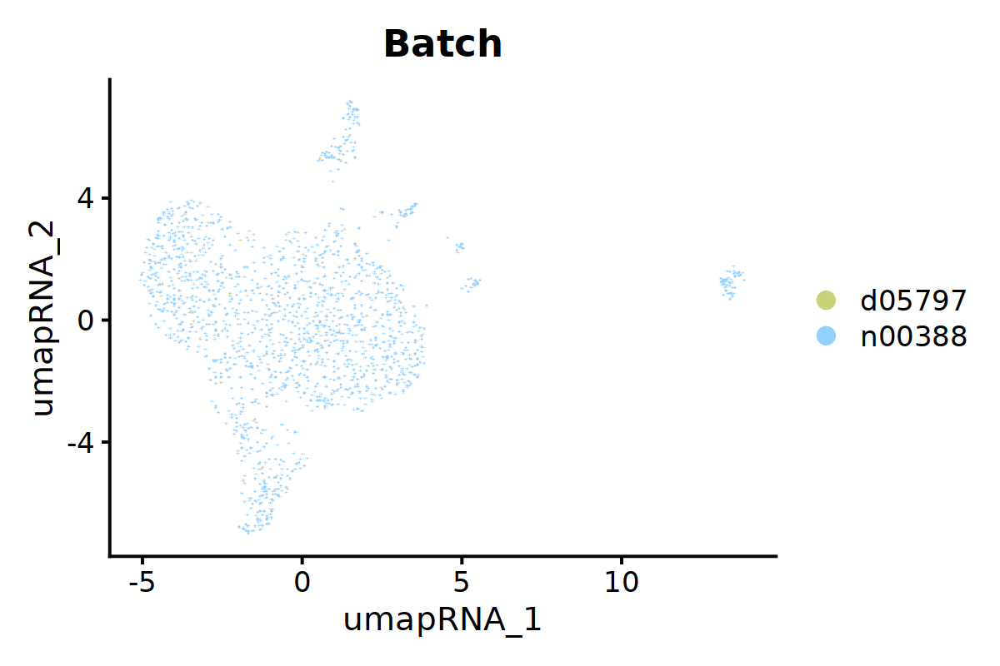

In [ ]:
options(repr.plot.width = 8, repr.plot.height = 4, repr.plot.res = 200)
before_umap_s <- DimPlot(endo_filt, reduction = 'umap_RNA', group.by = 'Sample', pt.size = 1.5, raster = TRUE, cols = my_c)

before_umap_s

ggsave(file="Endo_aff_Sample_UMAP.svg", plot=before_umap_s, width=8, height=4)


options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
before_umap_a <- DimPlot(endo_filt, reduction = 'umap_RNA', group.by = 'Age', pt.size = 1.5, raster = TRUE, cols = my_c[2:3])

before_umap_a

ggsave(file="Endo_aff_Age_UMAP.svg", plot=before_umap_a, width=6, height=4)

options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
before_umap_a <- DimPlot(endo_filt, reduction = 'umap_RNA', group.by = 'Batch', pt.size = 1.5, raster = TRUE, cols = my_c[2:3])

before_umap_a

ggsave(file="Endo_aff_Batch_UMAP.svg", plot=before_umap_a, width=6, height=4)

### Integration with Harmony

In [20]:
library(harmony)

Warning message:
“package ‘harmony’ was built under R version 4.3.3”
Loading required package: Rcpp

Warning message:
“package ‘Rcpp’ was built under R version 4.3.3”


In [21]:
integrated <- RunHarmony(endo_filt, group.by.vars = 'Sample', reduction.save = 'harmonyRNA')

Transposing data matrix

Initializing state using k-means centroids initialization

Harmony 1/10

Harmony converged after 1 iterations



In [22]:
integrated

An object of class Seurat 
215510 features across 1720 samples within 2 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: peaks
 4 dimensional reductions calculated: pca, umap, umap_RNA, harmonyRNA

In [23]:
integrated <- RunUMAP(integrated, reduction = 'harmonyRNA', dims = 1:15, n.neighbors = 15, reduction.name="harmony_RNA")

21:12:56 UMAP embedding parameters a = 0.9922 b = 1.112

21:12:56 Read 1720 rows and found 15 numeric columns

21:12:56 Using Annoy for neighbor search, n_neighbors = 15

21:12:56 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

21:12:56 Writing NN index file to temp file /tmp/RtmpVf3X1a/file6fa2c7ce5e193

21:12:56 Searching Annoy index using 1 thread, search_k = 1500

21:12:56 Annoy recall = 100%

21:12:57 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 15

21:12:59 Initializing from normalized Laplacian + noise (using RSpectra)

21:12:59 Commencing optimization for 500 epochs, with 32974 positive edges

21:13:02 Optimization finished

Warning message:
“Key ‘harmonyRNA_’ taken, using ‘harmonyrna_’ instead”


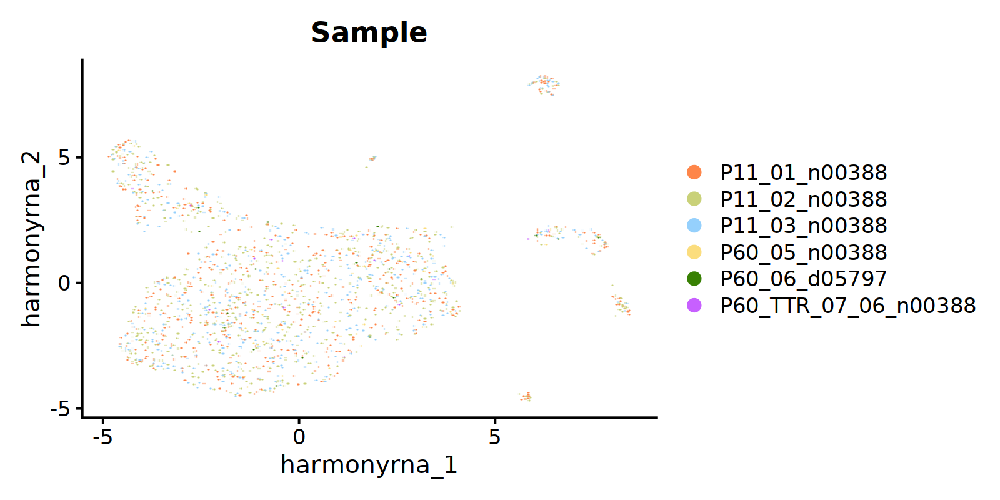

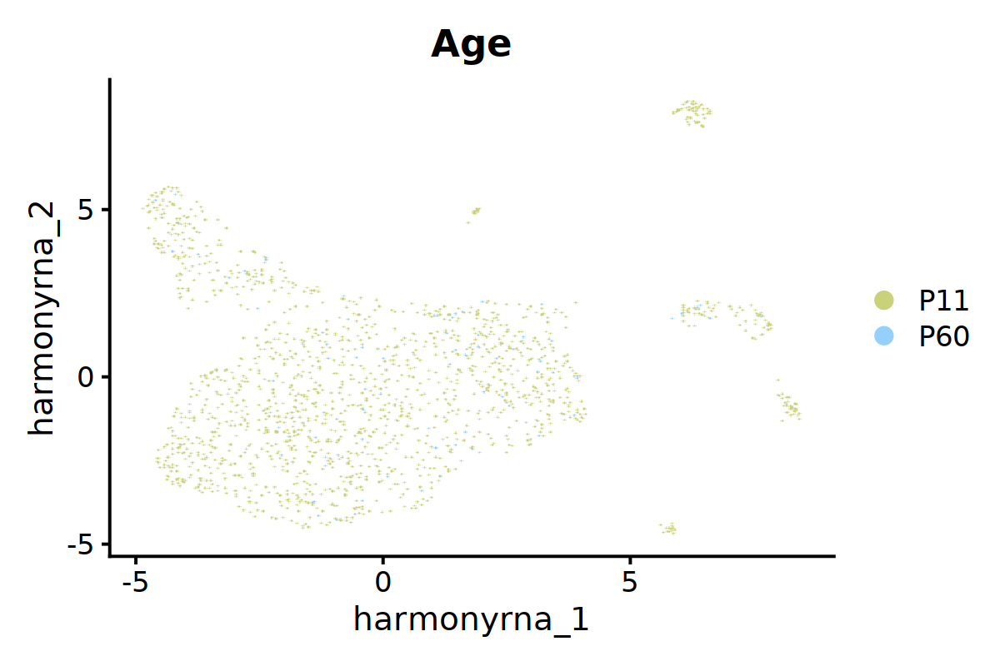

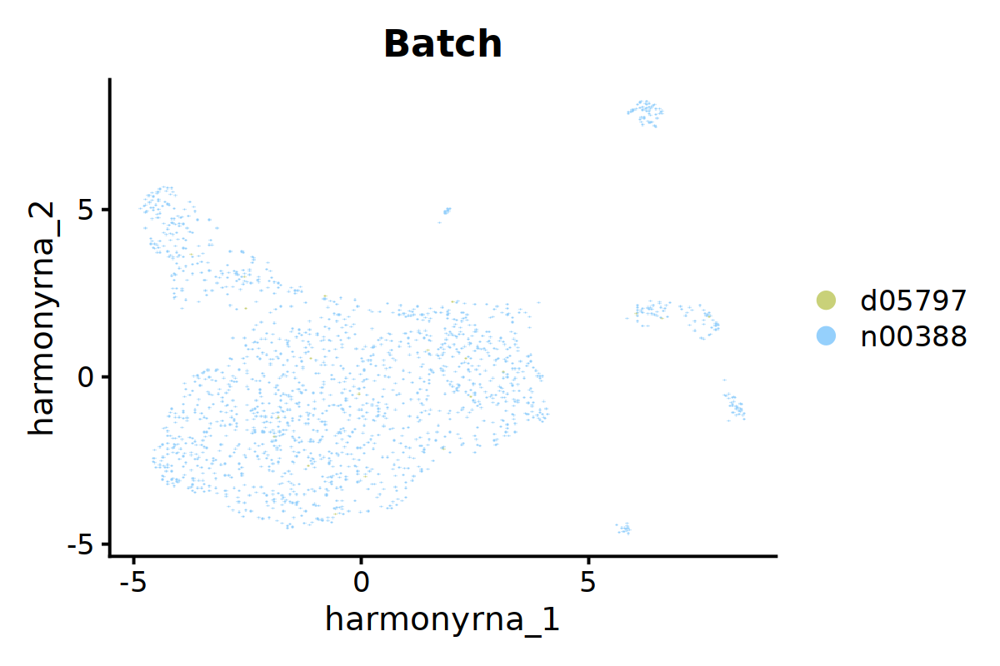

In [ ]:
options(repr.plot.width = 8, repr.plot.height = 4, repr.plot.res = 200)
after_umap_s <- DimPlot(integrated, reduction = 'harmony_RNA', group.by = 'Sample', pt.size = 1.5, raster = TRUE, cols = my_c)

after_umap_s

ggsave(file="Harmony_RNA_sample_UMAP.svg", plot=after_umap_s, width=8, height=4)


options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
after_umap_a <- DimPlot(integrated, reduction = 'harmony_RNA', group.by = 'Age', pt.size = 1.5, raster = TRUE, cols = my_c[2:3])

after_umap_a

ggsave(file="Harmony_RNA_Age_UMAP.svg", plot=after_umap_a, width=6, height=4)

options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
after_umap_b <- DimPlot(integrated, reduction = 'harmony_RNA', group.by = 'Batch', pt.size = 1.5, raster = TRUE, cols = my_c[2:3])

after_umap_b

ggsave(file="Harmony_RNA_Batch_UMAP.svg", plot=after_umap_b, width=6, height=4)


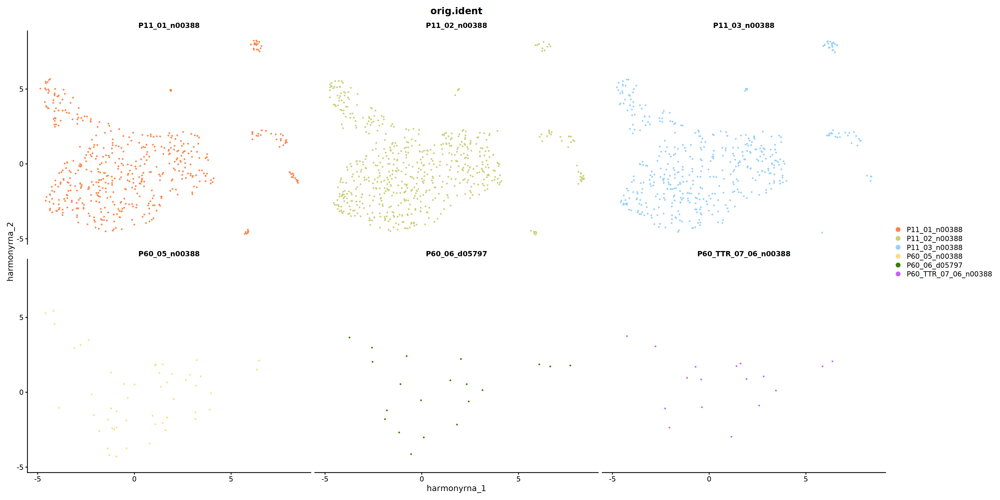

In [ ]:
options(repr.plot.width=24, repr.plot.height=12)
dpl <- DimPlot(integrated, group.by="orig.ident", split.by="orig.ident", reduction="harmony_RNA", shuffle=TRUE, cols=my_c, ncol=3, pt.size=0.5, label=FALSE)

dpl

ggsave(file="Harmony_each_sample_UMAP.svg", plot=dpl, width=24, height=12)

Warning message:
“All cells have the same value (4) of “Ttr””
Warning message:
“All cells have the same value (0) of “Sox10””
Warning message:
“All cells have the same value (0) of “Mog””
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding anoth

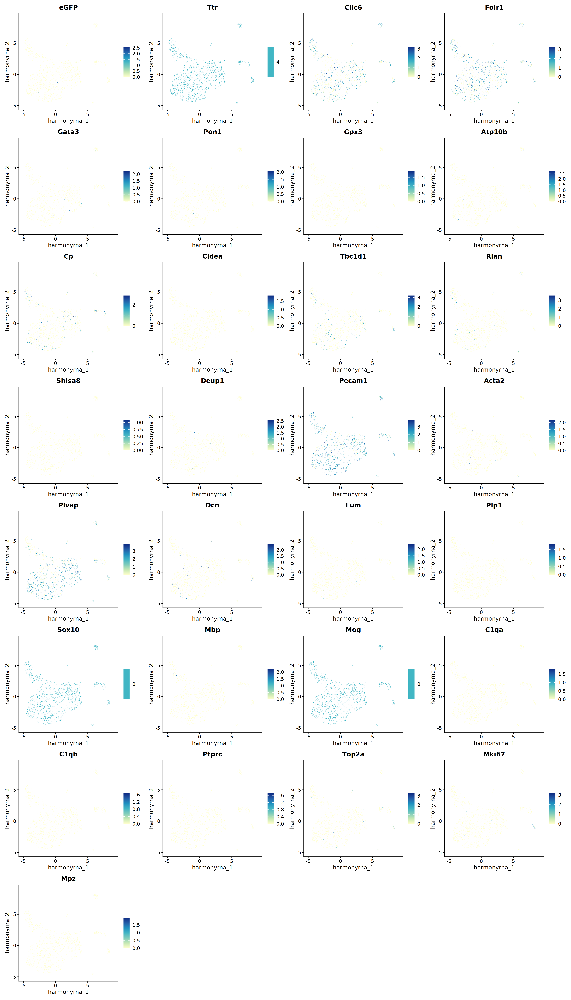

In [ ]:
options(repr.plot.width = 20, repr.plot.height = 35, repr.plot.res = 200)
ftp <- FeaturePlot(integrated, reduction = 'harmony_RNA', features = c('eGFP', 'Ttr', 'Clic6', 'Folr1', 'Gata3', 'Pon1', 'Gpx3', 'Atp10b', 'Cp', 'Cidea', 'Tbc1d1', 'Rian', 'Shisa8', 'Deup1', 'Pecam1', 'Acta2', 'Plvap', 
                                                  'Dcn', 'Lum', 'Plp1', 'Sox10', 'Mbp', 'Mog', 'C1qa', 'C1qb', 'Ptprc', 'Top2a', 'Mki67', 'Mpz'), 
             min.cutoff = 0, max.cutoff = 4, label.size = 2, ncol = 4, pt.size = 1.5, raster=TRUE) & scale_color_distiller(palette = "YlGnBu", direction = 1)
ftp 


ggsave(file="Harmony_geneExpression.svg", plot=ftp, width=20, height=35)

### Clustering

In [27]:
integrated

An object of class Seurat 
215510 features across 1720 samples within 2 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: peaks
 5 dimensional reductions calculated: pca, umap, umap_RNA, harmonyRNA, harmony_RNA

In [28]:
DefaultAssay(integrated) <- 'RNA'

In [29]:
integrated <- integrated %>% FindNeighbors(reduction = 'harmonyRNA', dims = 1:15) %>%
                                FindClusters(resolution = c(0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1, 1.2, 1.3, 1.4, 1.5, 1.6))

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 1720
Number of edges: 61697

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9220
Number of communities: 4
Elapsed time: 0 seconds
Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 1720
Number of edges: 61697

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8631
Number of communities: 6
Elapsed time: 0 seconds
Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 1720
Number of edges: 61697

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8272
Number of communities: 6
Elapsed time: 0 seconds
Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 1720
Number of edges: 61697

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7921
Number of communities: 6
Elapsed time: 0 seconds
Modularity Optimizer ver

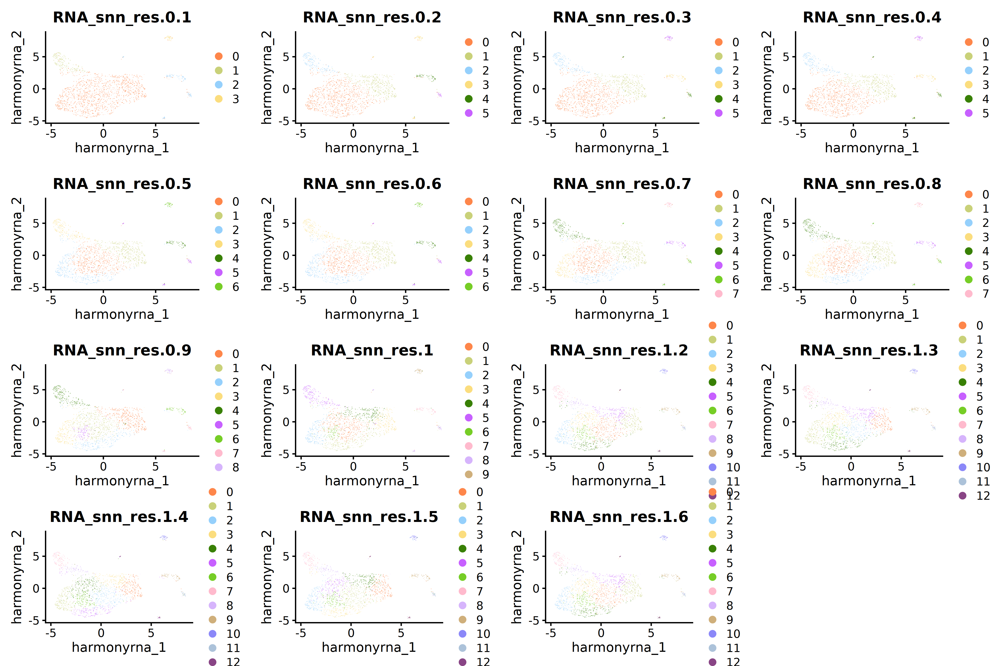

In [ ]:
options(repr.plot.width = 15, repr.plot.height = 10, repr.plot.res = 300)
grid <- plot_grid(DimPlot(integrated, reduction = "harmony_RNA", pt.size=1.5, group.by = 'RNA_snn_res.0.1', cols = my_c, raster = TRUE), 
                  DimPlot(integrated, reduction = "harmony_RNA", pt.size=1.5, group.by = 'RNA_snn_res.0.2', cols = my_c, raster = TRUE),
                  DimPlot(integrated, reduction = "harmony_RNA", pt.size=1.5, group.by = 'RNA_snn_res.0.3', cols = my_c, raster = TRUE),
                  DimPlot(integrated, reduction = "harmony_RNA", pt.size=1.5, group.by = 'RNA_snn_res.0.4', cols = my_c, raster = TRUE),
                  DimPlot(integrated, reduction = "harmony_RNA", pt.size=1.5, group.by = 'RNA_snn_res.0.5', cols = my_c, raster = TRUE),
                  DimPlot(integrated, reduction = "harmony_RNA", pt.size=1.5, group.by = 'RNA_snn_res.0.6', cols = my_c, raster = TRUE),
                  DimPlot(integrated, reduction = "harmony_RNA", pt.size=1.5, group.by = 'RNA_snn_res.0.7', cols = my_c, raster = TRUE),
                  DimPlot(integrated, reduction = "harmony_RNA", pt.size=1.5, group.by = 'RNA_snn_res.0.8', cols = my_c, raster = TRUE),
                  DimPlot(integrated, reduction = "harmony_RNA", pt.size=1.5, group.by = 'RNA_snn_res.0.9', cols = my_c, raster = TRUE),
                  DimPlot(integrated, reduction = "harmony_RNA", pt.size=1.5, group.by = 'RNA_snn_res.1', cols = my_c, raster = TRUE),
                  DimPlot(integrated, reduction = "harmony_RNA", pt.size=1.5, group.by = 'RNA_snn_res.1.2', cols = my_c, raster = TRUE),
                  DimPlot(integrated, reduction = "harmony_RNA", pt.size=1.5, group.by = 'RNA_snn_res.1.3', cols = my_c, raster = TRUE),
                  DimPlot(integrated, reduction = "harmony_RNA", pt.size=1.5, group.by = 'RNA_snn_res.1.4', cols = my_c, raster = TRUE),
                  DimPlot(integrated, reduction = "harmony_RNA", pt.size=1.5, group.by = 'RNA_snn_res.1.5', cols = my_c, raster = TRUE),
                  DimPlot(integrated, reduction = "harmony_RNA", pt.size=1.5, group.by = 'RNA_snn_res.1.6', cols = my_c, raster = TRUE))
grid

ggsave(file="Endothelial_integrated_clusters_all.svg", plot=grid, width=15, height=30)

In [31]:
integrated <- SetIdent(integrated, value = 'RNA_snn_res.1.2')

In [32]:
integrated_predicted.markers <- FindAllMarkers(integrated, test.use="wilcox", only.pos=TRUE, max.cells.per.ident=15)

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6

Calculating cluster 7

Calculating cluster 8

Calculating cluster 9

Calculating cluster 10

Calculating cluster 11

Calculating cluster 12



In [34]:
integrated_predicted.markers %>% group_by(cluster) %>%
                                slice_head(n = 10) %>%
                                ungroup() -> top10_predicted

In [35]:
top10_predicted <- top10_predicted[!duplicated(top10_predicted$gene), ]

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


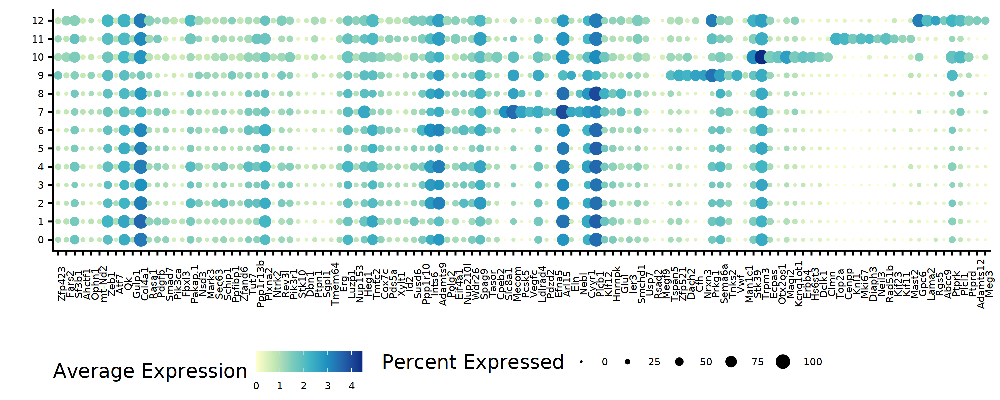

In [ ]:
options(repr.plot.width = 10, repr.plot.height = 4, repr.plot.res = 300)
dtp <- DotPlot(integrated, features = top10_predicted$gene, col.min = 0, col.max = 4, dot.scale = 4, scale=FALSE) + theme(axis.text.x=element_text(size=7, angle = 90),axis.text.y=element_text(size=7), 
                                                                                                 legend.position = 'bottom', legend.direction = 'horizontal', 
                                                                                                  legend.text = element_text(size=7)) + xlab('') + ylab('') & scale_color_distiller(palette = "YlGnBu", direction = 1)

dtp


In [ ]:
saveRDS(integrated, 'Endothelial_integrated_multiome_peaks_clusters.rds')

# ATAC

In [ ]:
integrated <- readRDS('Endothelial_integrated_multiome_peaks_clusters.rds')

In [39]:
DefaultAssay(integrated) <- "peaks"

In [40]:
integrated <- FindTopFeatures(integrated, assay = "peaks", min.cutoff = 10)

In [41]:
integrated <- RunTFIDF(integrated, assay="peaks")

Performing TF-IDF normalization

Warning message in RunTFIDF.default(object = GetAssayData(object = object, layer = "counts"), :
“Some features contain 0 total counts”


In [42]:
integrated <- RunSVD(integrated, assay="peaks")

Running SVD

Scaling cell embeddings



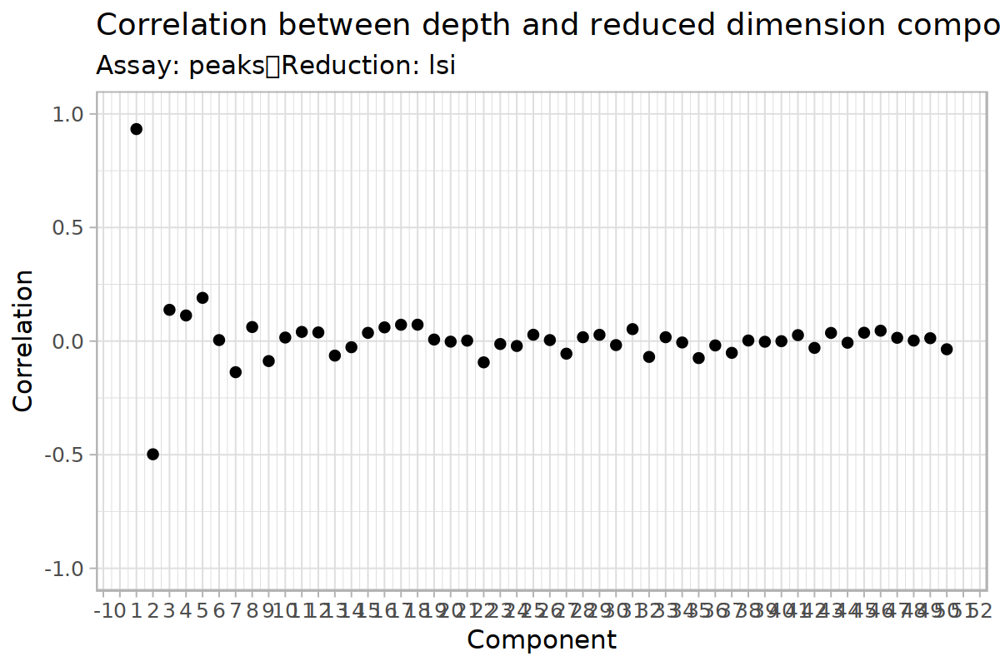

In [ ]:
options(repr.plot.width=6, repr.plot.height=4, repr.plot.res = 200)
dpc <- DepthCor(integrated, n=50)

dpc

ggsave(file="Merged_depthCorr.svg", plot=dpc, width=6, height=4)

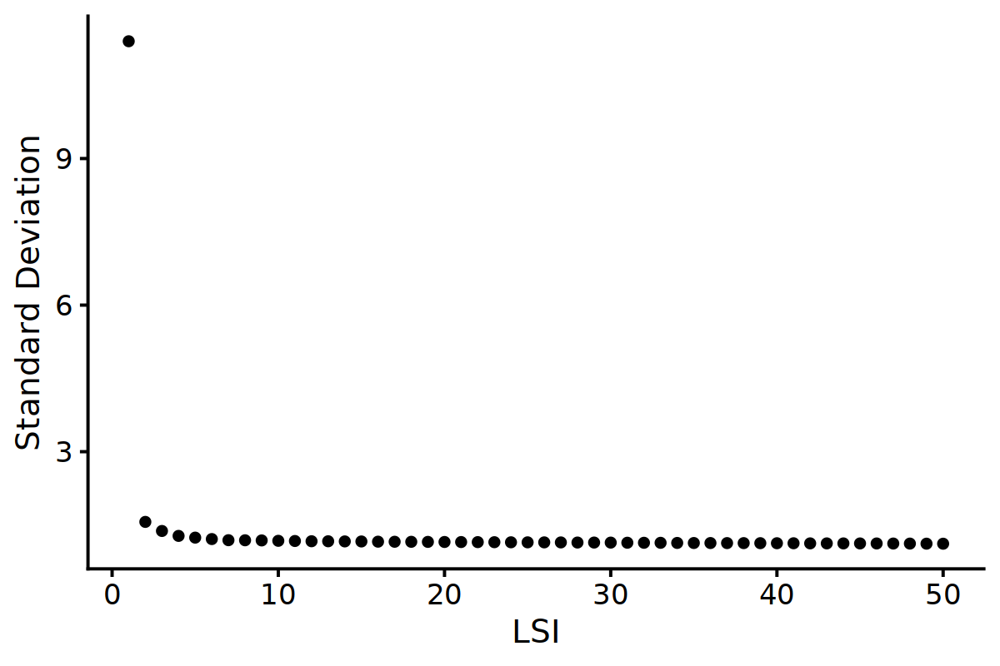

In [ ]:
options(repr.plot.width=6, repr.plot.height=4, repr.plot.res = 200)
ebl <- ElbowPlot(integrated, reduction = "lsi", n=50)

ebl

ggsave(file="Merged_depthCorr_ebl.svg", plot=ebl, width=6, height=4)

In [45]:
integrated <- FindNeighbors(integrated, reduction = 'lsi', dims = 2:10, graph.name="snn_peaks")

Computing nearest neighbor graph

Computing SNN

Only one graph name supplied, storing nearest-neighbor graph only



In [46]:
integrated <- RunUMAP(integrated, dims = 2:10, reduction = 'lsi', reduction.name="umap_peaks")

21:14:19 UMAP embedding parameters a = 0.9922 b = 1.112

21:14:19 Read 1720 rows and found 9 numeric columns

21:14:19 Using Annoy for neighbor search, n_neighbors = 30

21:14:19 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

21:14:19 Writing NN index file to temp file /tmp/RtmpVf3X1a/file6fa2c187ee47d

21:14:19 Searching Annoy index using 1 thread, search_k = 3000

21:14:20 Annoy recall = 100%

21:14:21 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

21:14:23 Initializing from normalized Laplacian + noise (using RSpectra)

21:14:23 Commencing optimization for 500 epochs, with 64910 positive edges

21:14:26 Optimization finished



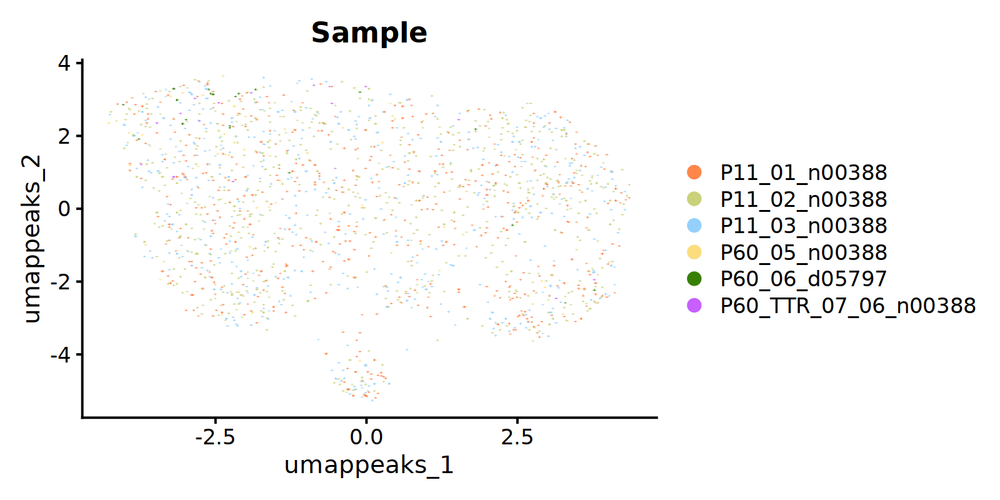

In [ ]:
options(repr.plot.width=8, repr.plot.height=4)
dpl <- DimPlot(integrated, group.by="Sample", reduction="umap_peaks", pt.size = 1.5, raster = TRUE, cols = my_c, label=FALSE)

dpl 

ggsave(file="Merged_peaks_Sample_UMAP.svg", plot=dpl, width=8, height=4)

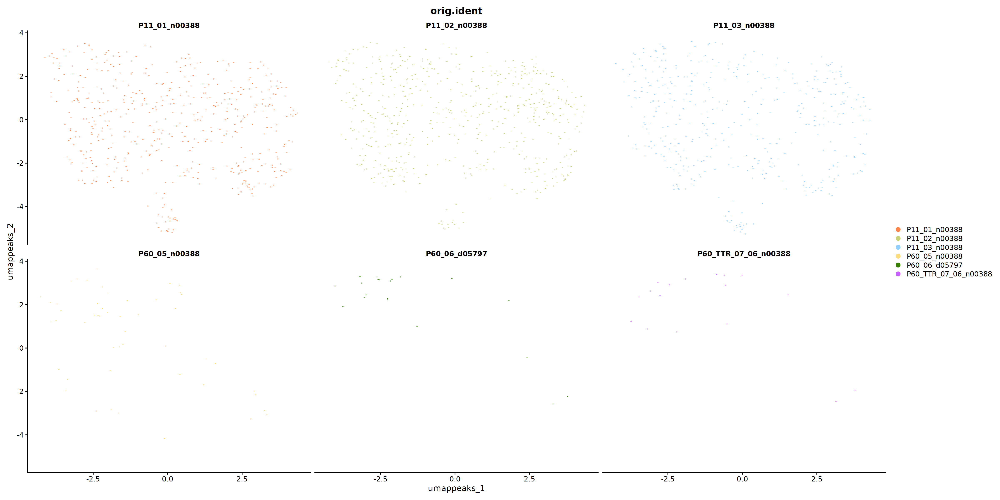

In [ ]:
options(repr.plot.width=24, repr.plot.height=12)
dpl <- DimPlot(integrated, group.by="orig.ident", split.by="orig.ident", reduction="umap_peaks", shuffle=TRUE, cols=my_c, ncol=3, pt.size=1.5, raster = TRUE, label=FALSE)

dpl

ggsave(file="Merged_peaks_each_sample_UMAP.svg", plot=dpl, width=8, height=4)

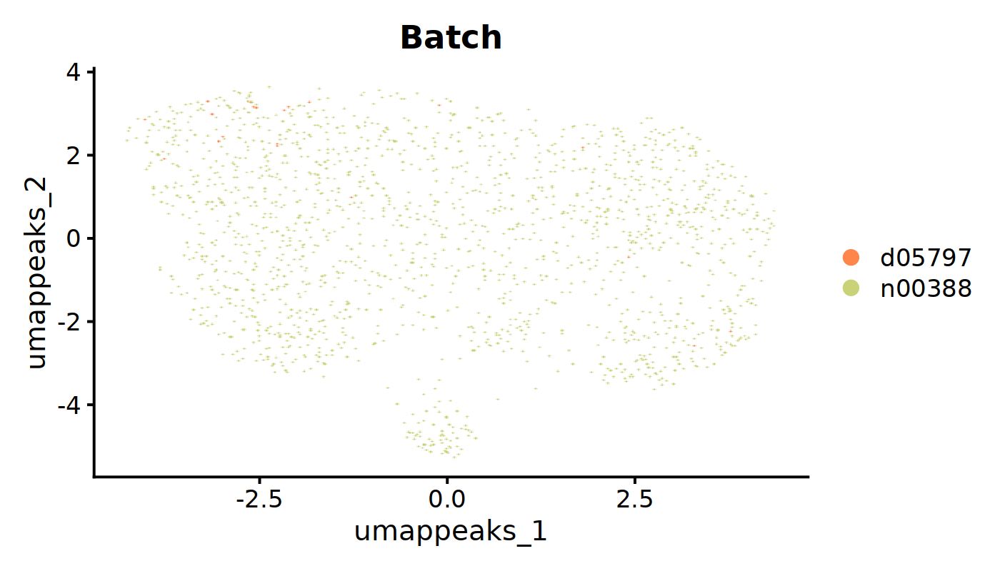

In [ ]:
options(repr.plot.width=7, repr.plot.height=4)
dpl <- DimPlot(integrated, group.by="Batch", reduction="umap_peaks", pt.size = 1.5, raster = TRUE, cols = my_c, label=FALSE)

dpl

ggsave(file="Merged_peaks_Batch_UMAP.svg", plot=dpl, width=7, height=4)

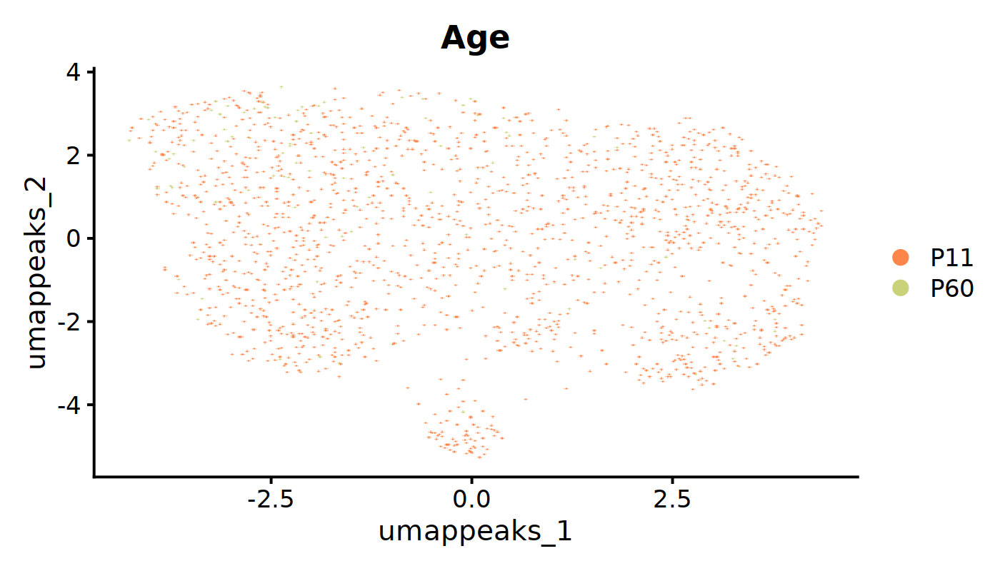

In [ ]:
options(repr.plot.width=7, repr.plot.height=4)
dpl <- DimPlot(integrated, group.by="Age", reduction="umap_peaks", pt.size = 1.5, raster = TRUE, cols = my_c, label=FALSE)

dpl

ggsave(file="Merged_peaks_Age_UMAP.svg", plot=dpl, width=7, height=4)

### Integration with Harmony

In [52]:
library(harmony)

In [53]:
integrated <- RunHarmony(integrated, group.by.vars = 'Sample', reduction = 'lsi', assay.use = 'peaks', reduction.save = 'harmonypeaks', project.dim = FALSE)

Transposing data matrix

Initializing state using k-means centroids initialization

Harmony 1/10

Harmony 2/10

Harmony 3/10

Harmony 4/10

Harmony 5/10

Harmony 6/10

Harmony 7/10

Harmony 8/10

Harmony converged after 8 iterations



In [54]:
# re-compute the UMAP using corrected LSI embeddings
integrated <- RunUMAP(integrated, dims = 2:10, reduction = 'harmonypeaks', reduction.name = 'harmony_peaks')

21:14:33 UMAP embedding parameters a = 0.9922 b = 1.112

21:14:33 Read 1720 rows and found 9 numeric columns

21:14:33 Using Annoy for neighbor search, n_neighbors = 30

21:14:33 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

21:14:33 Writing NN index file to temp file /tmp/RtmpVf3X1a/file6fa2c3459ad8a

21:14:33 Searching Annoy index using 1 thread, search_k = 3000

21:14:33 Annoy recall = 100%

21:14:35 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

21:14:37 Initializing from normalized Laplacian + noise (using RSpectra)

21:14:37 Commencing optimization for 500 epochs, with 65138 positive edges

21:14:40 Optimization finished

Warning message:
“Key ‘harmonypeaks_’ taken, using ‘pghfu_’ instead”


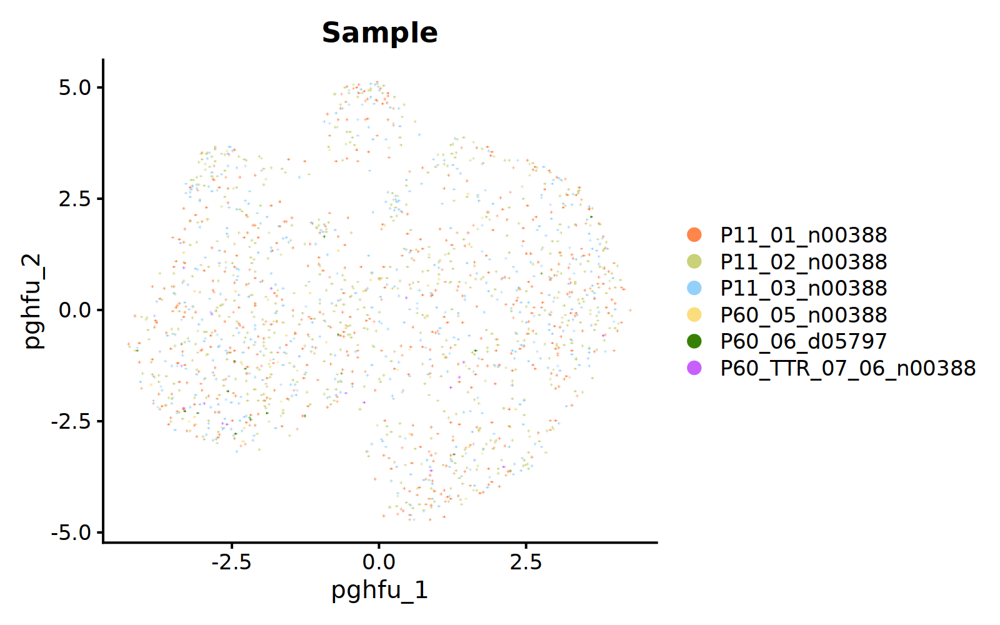

In [ ]:
options(repr.plot.width=8, repr.plot.height=5)
dpl <- DimPlot(integrated, group.by = 'Sample', pt.size = 1.5, raster=TRUE, cols=my_c, reduction = 'harmony_peaks')

dpl

ggsave(file="Endothelial_integrated_peaks_Sample_UMAP.svg", plot=dpl, width=8, height=5)

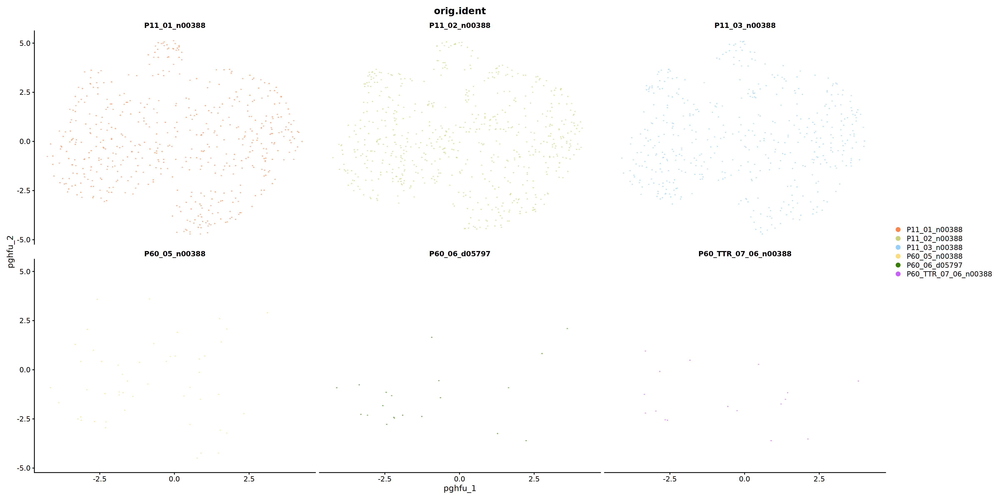

In [ ]:
options(repr.plot.width=24, repr.plot.height=12)
dpl <- DimPlot(integrated, group.by="orig.ident", split.by="orig.ident", reduction="harmony_peaks", shuffle=TRUE, cols=my_c, ncol=3, pt.size=1.5, raster = TRUE, label=FALSE)

dpl

ggsave(file="Endothelial_integrated_peaks_each_Sample_UMAP.svg", plot=dpl, width=24, height=12)

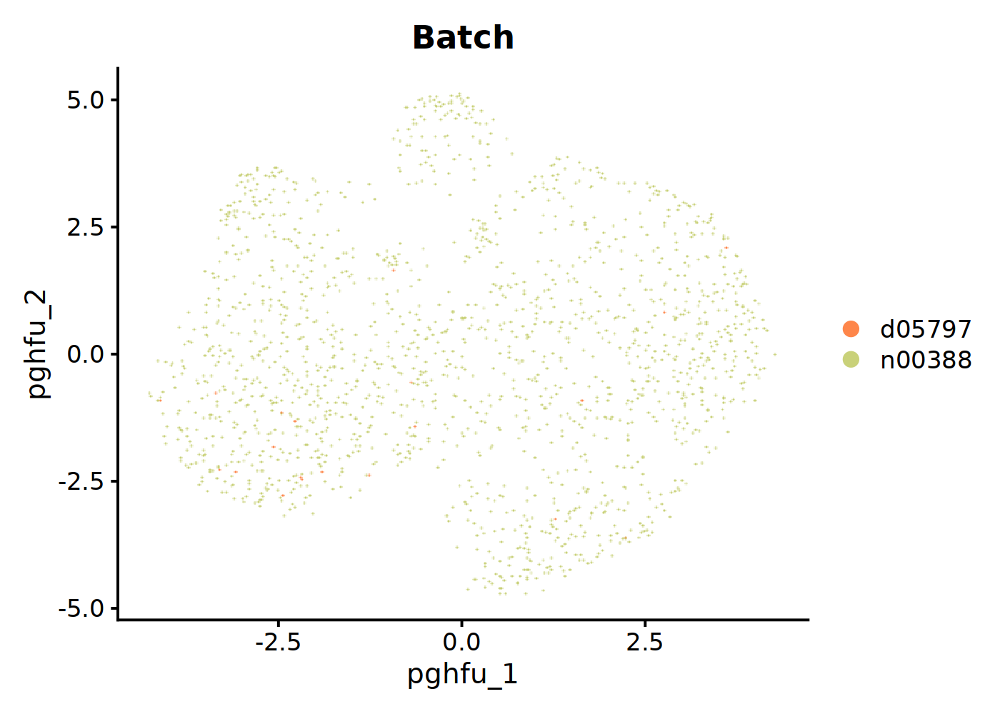

In [ ]:
options(repr.plot.width=7, repr.plot.height=5)
dpl <- DimPlot(integrated, group.by="Batch", reduction="harmony_peaks", pt.size = 1.5, raster = TRUE, cols = my_c, label=FALSE)

dpl

ggsave(file="Endothelial_integrated_peaks_Batch_UMAP.svg", plot=dpl, width=7, height=5)

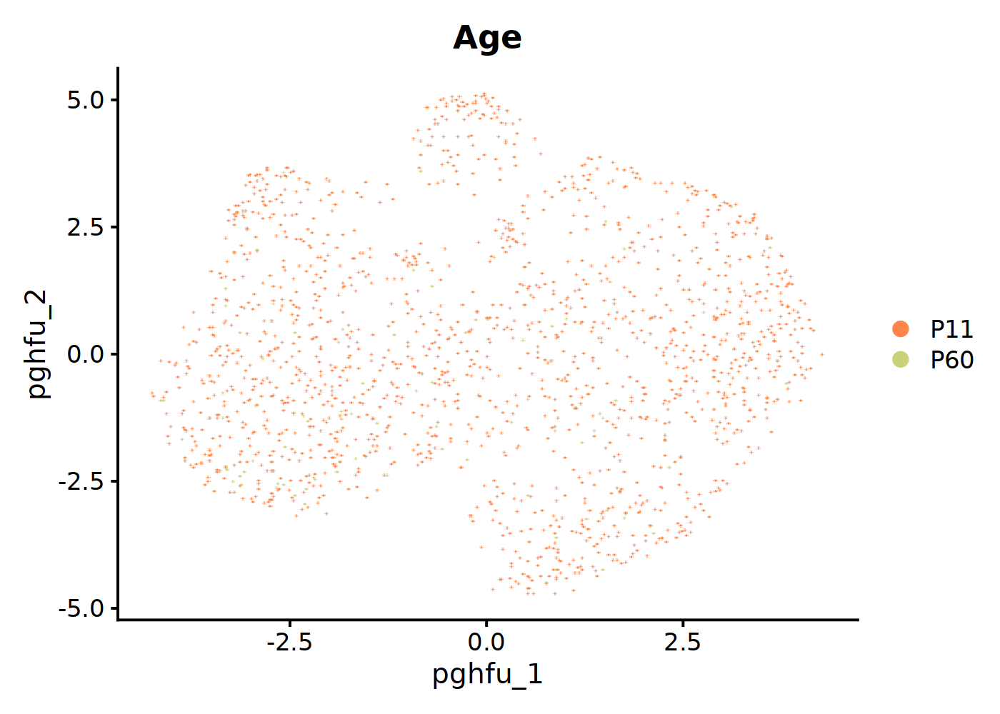

In [ ]:
options(repr.plot.width=7, repr.plot.height=5)
dpl <- DimPlot(integrated, group.by="Age", reduction="harmony_peaks", pt.size = 1.5, raster = TRUE, cols = my_c, label=FALSE)

dpl

ggsave(file="Endothelial_integrated_peaks_Age_UMAP.svg", plot=dpl, width=7, height=5)

### Clustering

In [60]:
DefaultAssay(integrated) <- 'peaks'

In [61]:
integrated

An object of class Seurat 
215510 features across 1720 samples within 2 assays 
Active assay: peaks (183223 features, 32945 variable features)
 2 layers present: counts, data
 1 other assay present: RNA
 9 dimensional reductions calculated: pca, umap, umap_RNA, harmonyRNA, harmony_RNA, lsi, umap_peaks, harmonypeaks, harmony_peaks

In [62]:
integrated <- integrated %>% FindNeighbors(reduction = 'harmonypeaks', dims = 2:10) %>%
                                FindClusters(resolution = c(0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1))

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 1720
Number of edges: 59841

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9016
Number of communities: 2
Elapsed time: 0 seconds
Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 1720
Number of edges: 59841

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8426
Number of communities: 5
Elapsed time: 0 seconds
Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 1720
Number of edges: 59841

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8067
Number of communities: 5
Elapsed time: 0 seconds
Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 1720
Number of edges: 59841

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7765
Number of communities: 7
Elapsed time: 0 seconds
Modularity Optimizer ver

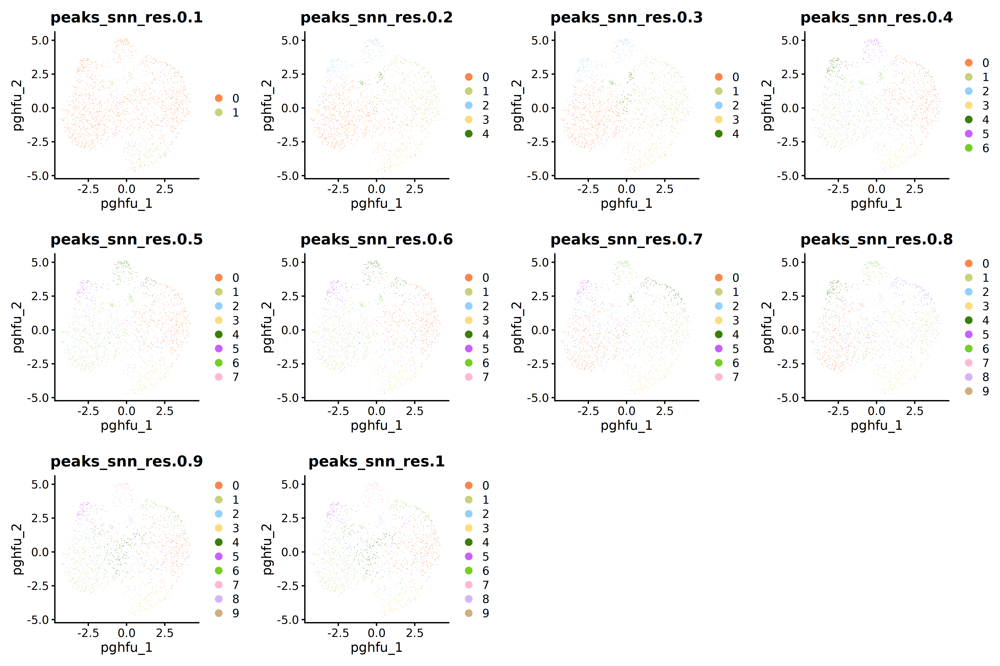

In [ ]:
options(repr.plot.width = 15, repr.plot.height = 10, repr.plot.res = 300)
grid <- plot_grid(DimPlot(integrated, reduction = "harmony_peaks", pt.size=1.5, group.by = 'peaks_snn_res.0.1', cols = my_c, raster = TRUE), 
                  DimPlot(integrated, reduction = "harmony_peaks", pt.size=1.5, group.by = 'peaks_snn_res.0.2', cols = my_c, raster = TRUE),
                  DimPlot(integrated, reduction = "harmony_peaks", pt.size=1.5, group.by = 'peaks_snn_res.0.3', cols = my_c, raster = TRUE),
                  DimPlot(integrated, reduction = "harmony_peaks", pt.size=1.5, group.by = 'peaks_snn_res.0.4', cols = my_c, raster = TRUE),
                  DimPlot(integrated, reduction = "harmony_peaks", pt.size=1.5, group.by = 'peaks_snn_res.0.5', cols = my_c, raster = TRUE),
                  DimPlot(integrated, reduction = "harmony_peaks", pt.size=1.5, group.by = 'peaks_snn_res.0.6', cols = my_c, raster = TRUE),
                  DimPlot(integrated, reduction = "harmony_peaks", pt.size=1.5, group.by = 'peaks_snn_res.0.7', cols = my_c, raster = TRUE),
                  DimPlot(integrated, reduction = "harmony_peaks", pt.size=1.5, group.by = 'peaks_snn_res.0.8', cols = my_c, raster = TRUE),
                  DimPlot(integrated, reduction = "harmony_peaks", pt.size=1.5, group.by = 'peaks_snn_res.0.9', cols = my_c, raster = TRUE),
                  DimPlot(integrated, reduction = "harmony_peaks", pt.size=1.5, group.by = 'peaks_snn_res.1', cols = my_c, raster = TRUE))
grid

ggsave(file="Endothelial_integrated_peaks_clusters_all.svg", plot=grid, width=15, height=30)

In [ ]:
saveRDS(integrated, 'Endothelial_integrated_multiome_peaks_clusters.rds')

# Cell type annotation

In [ ]:
integrated <- readRDS('Endothelial_integrated_multiome_peaks_clusters.rds')

In [67]:
DefaultAssay(integrated) <- 'RNA'

In [68]:
integrated <- SetIdent(integrated, value = 'RNA_snn_res.1.2')

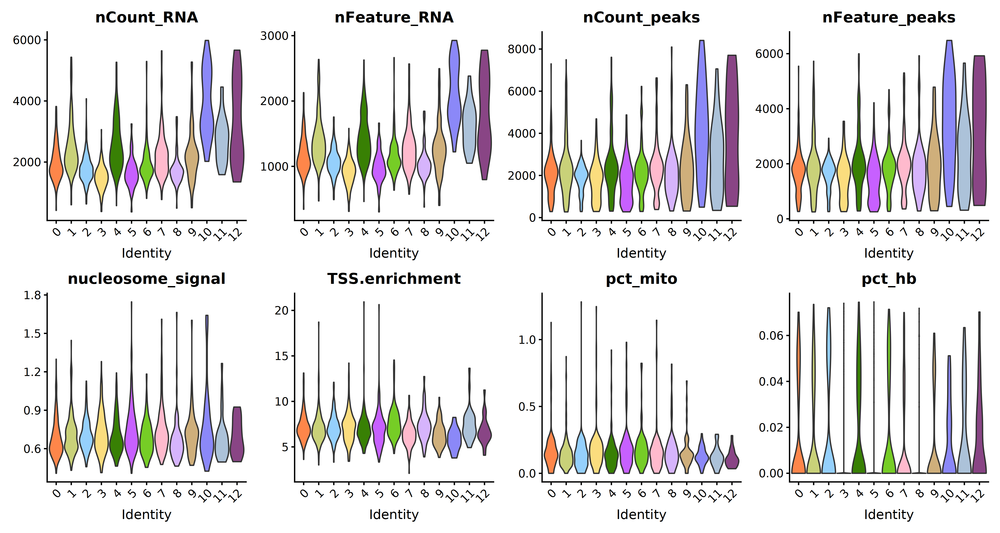

In [ ]:
options(repr.plot.width = 15, repr.plot.height = 8, repr.plot.res = 300)

vln <- VlnPlot(integrated, features=c('nCount_RNA', 'nFeature_RNA', 'nCount_peaks', 'nFeature_peaks', 'nucleosome_signal', 'TSS.enrichment', 'pct_mito', 'pct_hb'), 
        ncol=4, pt.size=0, col = my_c) 

vln

In [70]:
marker_genes <- c('Folr1', 'Clic6', 'Krt18', 'Ttr', 'Dcn', 'Itga8', 'Col3a1', 'Flt1', 'Plvap', 'Pecam1', 'Cd86', 'Tank', 
                  'Cd83', 'Dscam', 'Ptprz1', 'Gria2')

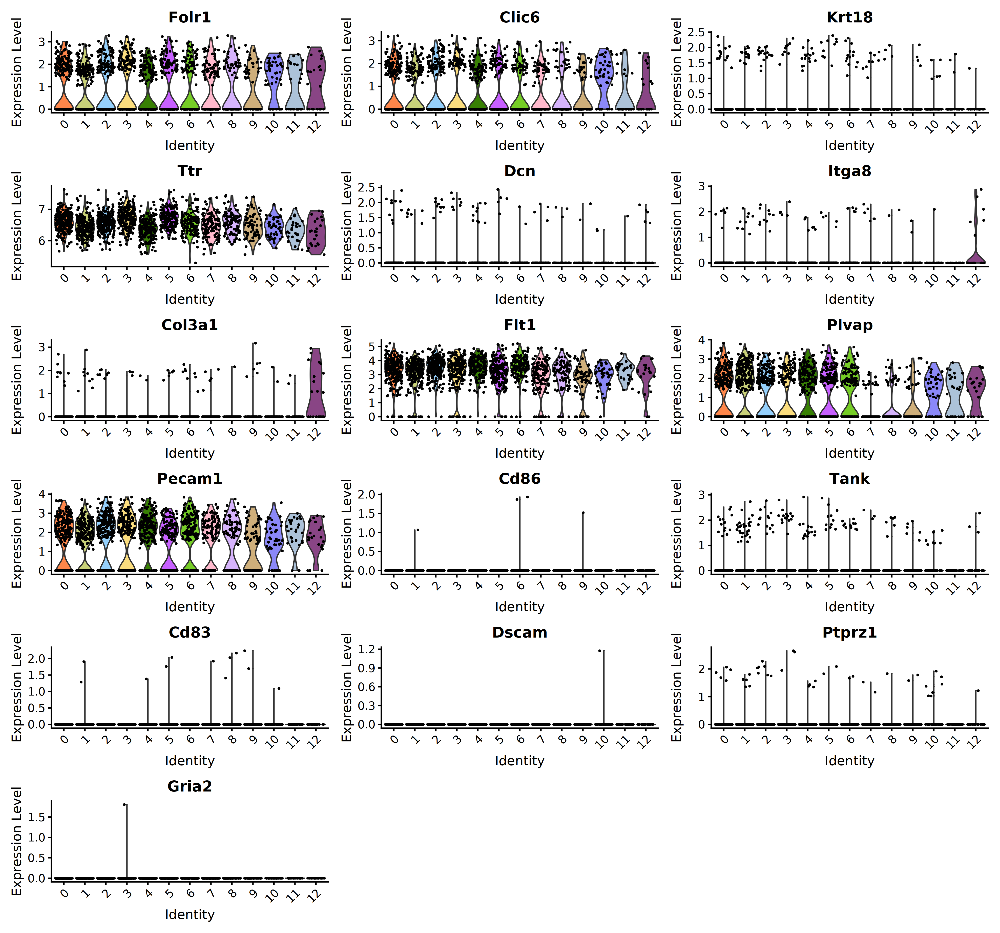

In [ ]:
options(repr.plot.width = 15, repr.plot.height = 14, repr.plot.res = 300)
vln <- VlnPlot(object = integrated, features = marker_genes, pt.size=0.5, cols = my_c, ncol = 3)

vln

In [72]:
endo_markers <- c('Plvap', 'Cd300lg', 'Esm1', 'Jam3', 'Top2a', 'Mki67', 'Birc5', 'Pclaf', 'Pcsk5', 'Nebl', 'Gja4', 
                  'Fbln5', 'Vwf', 'Pcdh7', 'Lbp', 'Nr2f2')

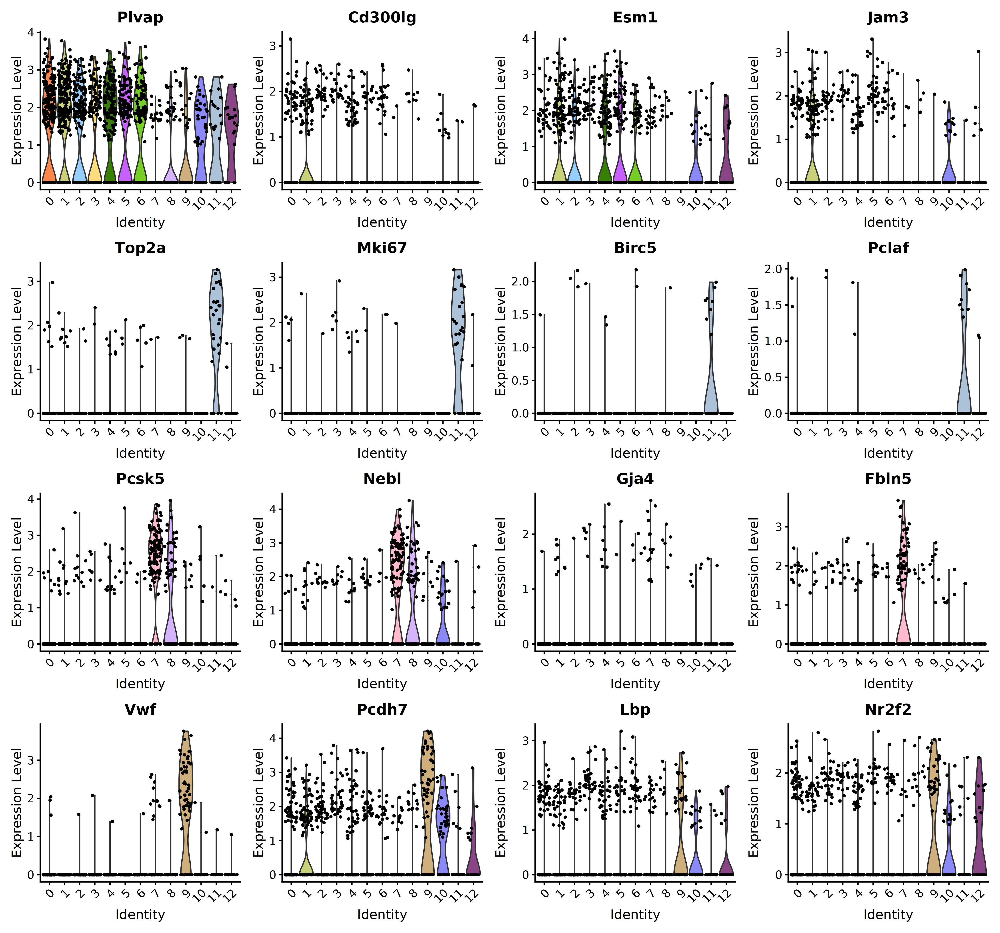

In [ ]:
options(repr.plot.width = 15, repr.plot.height = 14, repr.plot.res = 300)
vln <- VlnPlot(object = integrated, features = endo_markers, pt.size=0.8, cols = my_c, ncol = 4)

vln

In [ ]:
endo_markers_1 <- c('Mgp', 'Cytl1', 'Fbln5', 'Clu', 'Eln', 'Bgn', 'Igfbp4', 'Cfh', 'Lmcd1', 'Bpgm','Cmip',
                            '8430408G22Rik', 'S100a6', 'Azin1', 'Pi16', 'Cd9', 'Gadd45g', 'Timp3', 'Stmn2', 'Nr4a1','Apold1', 'Hbegf',
                            'Gkn3', 'Egfl8', 'Vegfc', 'Hrct1', 'Cdkn1c', 'Eps8l2', 'Alpl', 'Hey1', 'Edn3', 'Mgst1', 'Eogt',
                            'Glul', 'Rad54b', 'Tuba1a', 'Tgfb2', 'Slc26a10', 'Stmn1', 'Akap12', 'Klf6', 'Dusp1', 'Zfp771', 'Actb',
                            'Cxcl12', 'Spock2', 'Gm9946', 'Lrrn3', 'Gstm7', 'Palm', 'Tbx3', 'Prdm16', 'Rasgrp2', 'Cd83', 'Pik3ip1',
                            'Car4', 'Gatm', 'Itm2a', 'Hmcn1', 'Slc7a1', 'Nkd1', 'Hspa1a', 'Smox', 'Slc31a1', 'Slc39a8', 'Ttyh2',
                            'Tmsb10', 'Vcam1', 'Slc38a5', 'Icam1', 'Tmem252', 'Lcn2', 'Vwf', 'Ctsc', 'Tgm2', 'Ackr1', 'Apod',
                            'Isg15', 'Ifit1', 'Pglyrp1', 'Slc7a5', 'Ifit3', 'Sparcl1', 'Slc3a2', 'Ifit3b', 'Slc38a3', 'Usp18', 'Nostrin',
                            'Plvap', 'Plpp3', 'Plpp1', 'Nrp1', 'Cd24a', 'Socs3', 'Rgcc', 'Igfbp3', 'Kdr', 'Ehd4', 'Esm1')

In [ ]:
options(repr.plot.width = 40, repr.plot.height = 40, repr.plot.res = 300)
vln <- VlnPlot(object = integrated, features = endo_markers_carmeliet, pt.size=0, cols = my_c, ncol = 11)

vln

Warning message:
“The following requested variables were not found: 8430408G22Rik”
Warning message in SingleExIPlot(type = type, data = data[, x, drop = FALSE], idents = idents, :
“All cells have the same value of Ifit3b.”


In [ ]:
options(repr.plot.width = 40, repr.plot.height = 40, repr.plot.res = 200)
ftp <- FeaturePlot(integrated, reduction = 'harmony_RNA', features = endo_markers_carmeliet, min.cutoff = 0, max.cutoff = 4, label.size = 2, ncol = 11, pt.size = 1.5, raster=TRUE) & scale_color_distiller(palette = "YlGnBu", direction = 1)
ftp 


Warning message:
“The following requested variables were not found: 8430408G22Rik”
Warning message:
“All cells have the same value (0) of “Ifit3b””
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace 

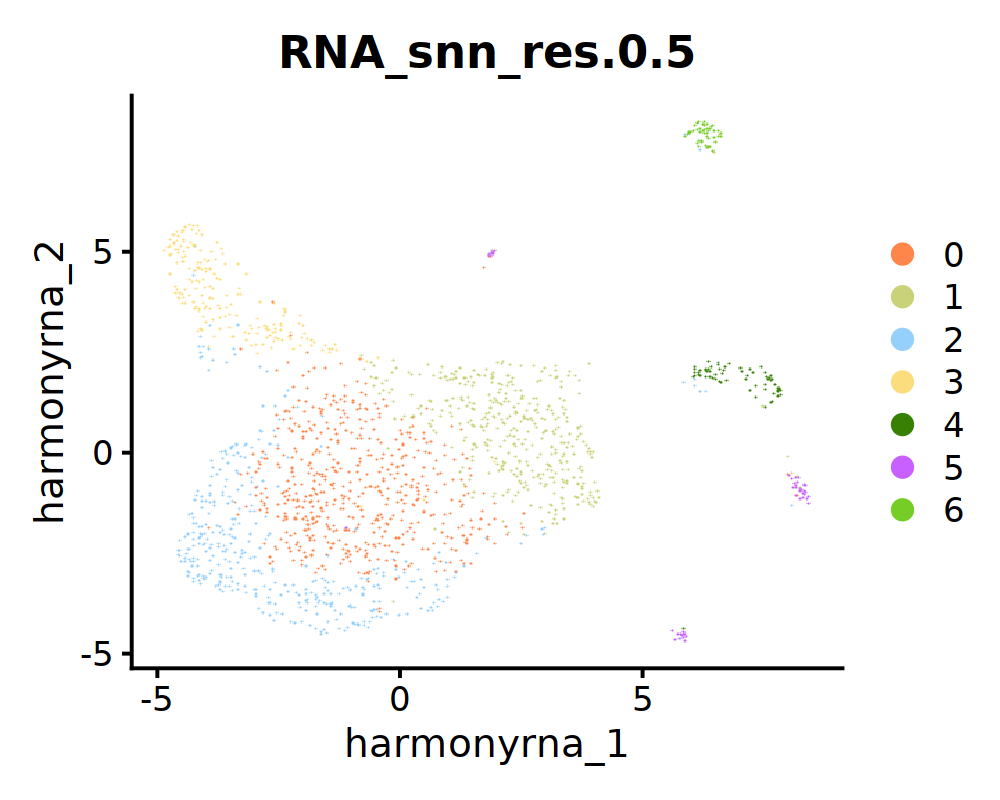

In [ ]:
options(repr.plot.width = 5, repr.plot.height = 4, repr.plot.res = 200)
dpt <- DimPlot(integrated, group.by = "RNA_snn_res.0.5", pt.size=1.5, raster = TRUE, cols = my_c, label = FALSE, repel = TRUE, reduction = 'harmony_RNA')

dpt

ggsave(file="Endothelial_integrated_clusters_RNA.svg", plot=dpt, width=7, height=5)

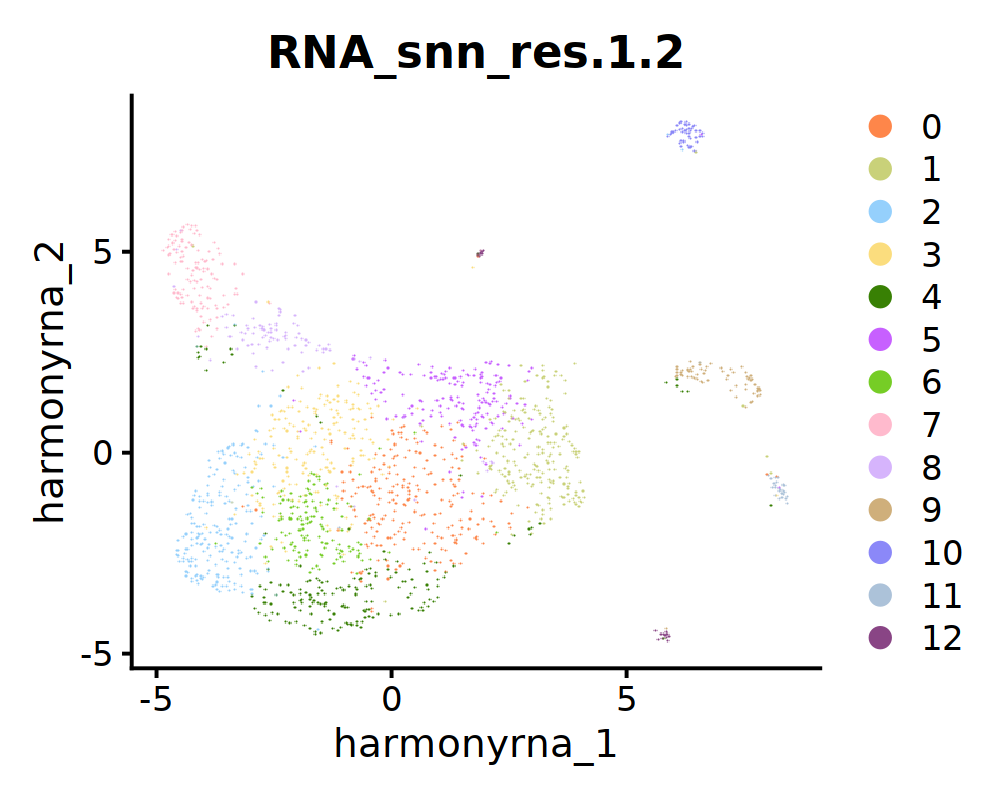

In [ ]:
options(repr.plot.width = 5, repr.plot.height = 4, repr.plot.res = 200)
dpt <- DimPlot(integrated, group.by = "RNA_snn_res.1.2", pt.size=1.5, raster = TRUE, cols = my_c, label = FALSE, repel = TRUE, reduction = 'harmony_RNA')

dpt

ggsave(file="Endothelial_integrated_clusters_RNA.svg", plot=dpt, width=7, height=5)

# Remove clusters of doublets

In [79]:
integrated <- subset(integrated, , idents = c(10, 12), invert = TRUE)

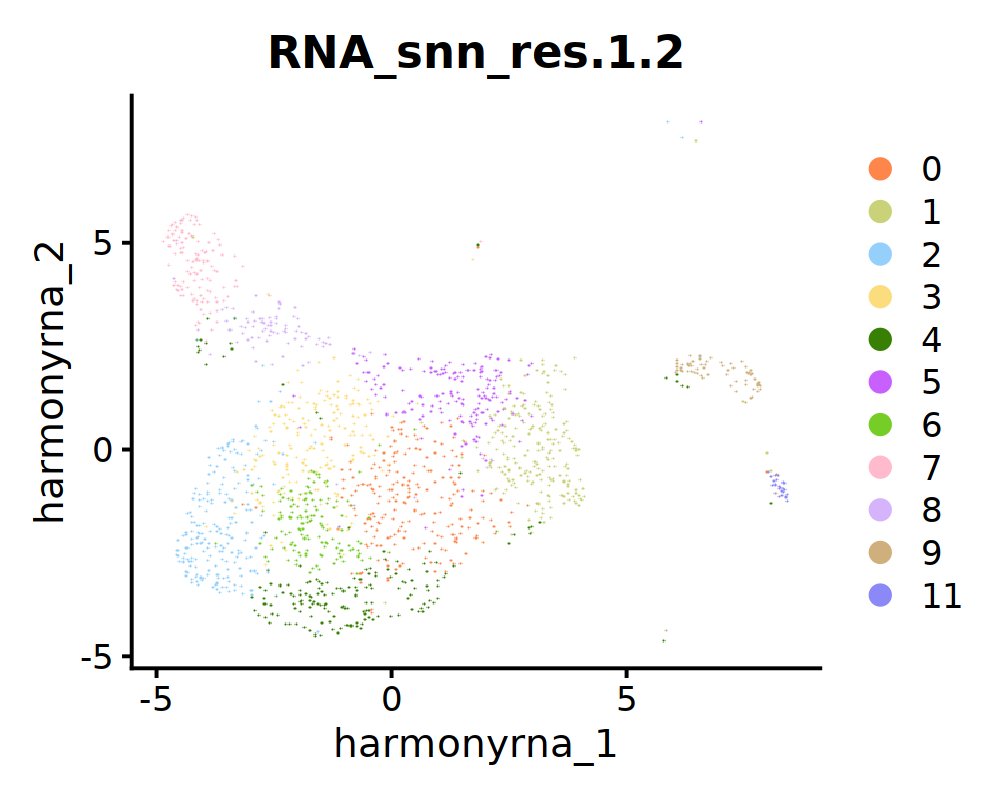

In [ ]:
options(repr.plot.width = 5, repr.plot.height = 4, repr.plot.res = 200)
dpt <- DimPlot(integrated, group.by = "RNA_snn_res.1.2", pt.size=1.5, raster = TRUE, cols = my_c, label = FALSE, repel = TRUE, reduction = 'harmony_RNA')

dpt

ggsave(file="Endothelial_integrated_dblRemoved_clusters_RNA.svg", plot=dpt, width=7, height=5)

In [81]:
integrated

An object of class Seurat 
215510 features across 1651 samples within 2 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: peaks
 9 dimensional reductions calculated: pca, umap, umap_RNA, harmonyRNA, harmony_RNA, lsi, umap_peaks, harmonypeaks, harmony_peaks

In [85]:
endo_noDBL <- subset(endo, cells=rownames(integrated@meta.data))

In [86]:
endo_noDBL

An object of class Seurat 
195169 features across 1651 samples within 2 assays 
Active assay: ATAC (162882 features, 0 variable features)
 2 layers present: counts, data
 1 other assay present: RNA

# Redo the analysis without doublets

In [87]:
endo_noDBL@assays

$RNA
Assay data with 32287 features for 1651 cells
First 10 features:
 Xkr4, Gm1992, Gm19938, Gm37381, Rp1, Sox17, Gm37587, Gm37323, Mrpl15,
Lypla1 

$ATAC
ChromatinAssay data with 162882 features for 1651 cells
Variable features: 0 
Genome: 
Annotation present: TRUE 
Motifs present: FALSE 
Fragment files: 6 


In [88]:
unique(endo_noDBL$Sample)

[1] "P11_01_n00388"        "P11_02_n00388"        "P11_03_n00388"       
[4] "P60_05_n00388"        "P60_06_d05797"        "P60_TTR_07_06_n00388"

In [89]:
unique(endo_noDBL$Age)

[1] "P11" "P60"

In [90]:
DefaultAssay(endo_noDBL) <- 'ATAC'

Warning message:
“Removed 39 rows containing non-finite outside the scale range (`stat_bin()`).”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range (`geom_bar()`).”
Warning message:
“Removed 39 rows containing non-finite outside the scale range (`stat_bin()`).”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range (`geom_bar()`).”


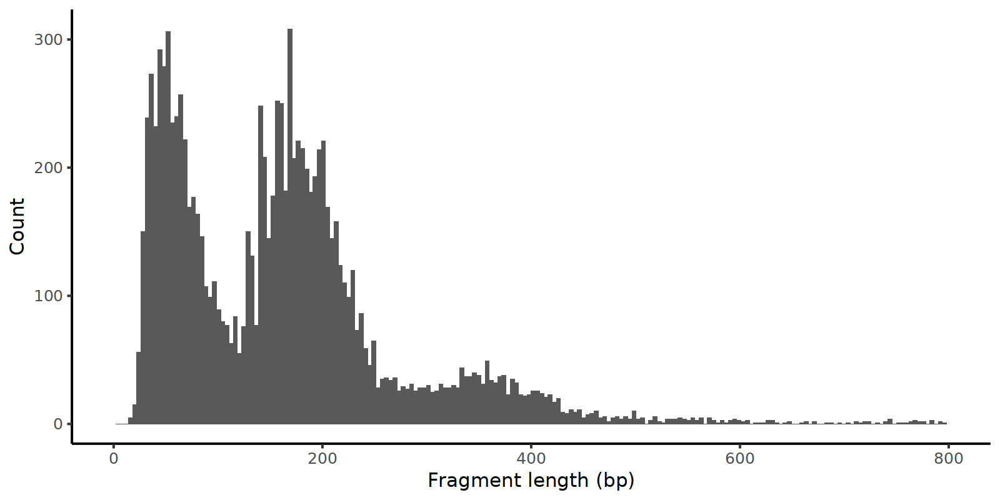

In [ ]:
options(repr.plot.width = 8, repr.plot.height = 4, repr.plot.res = 200)
endo_noDBL$nucleosome_group <- ifelse(endo_noDBL$nucleosome_signal > 2.0, 'NS > 2.0', 'NS < 2.0')

frag_hist <- FragmentHistogram(object = endo_noDBL, group.by = 'nucleosome_group', region = 'chr1-1-10000000')

frag_hist

ggsave(file="endo_noDBL_frag_hist.svg", plot=frag_hist, width=8, height=4)

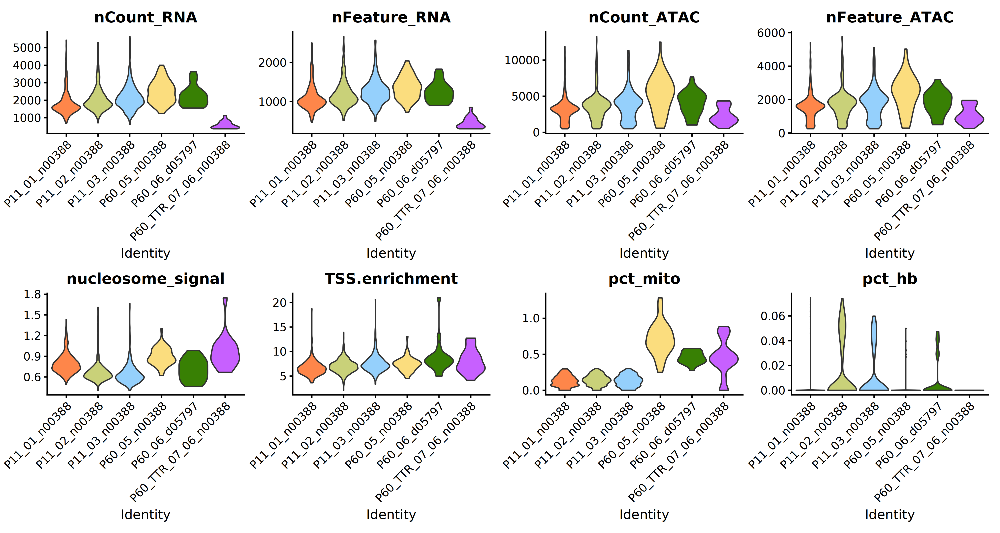

In [ ]:
options(repr.plot.width = 15, repr.plot.height = 8, repr.plot.res = 300)

vln <- VlnPlot(endo_noDBL, features=c('nCount_RNA', 'nFeature_RNA', 'nCount_ATAC', 'nFeature_ATAC', 'nucleosome_signal', 'TSS.enrichment', 'pct_mito', 'pct_hb'), 
        ncol=4, pt.size=0, col = my_c) 

vln

ggsave(file="endo_noDBL_all_vln_prefilter.svg", plot=vln, width=15, height=8)


In [93]:
DefaultAssay(endo_noDBL) <- 'RNA'

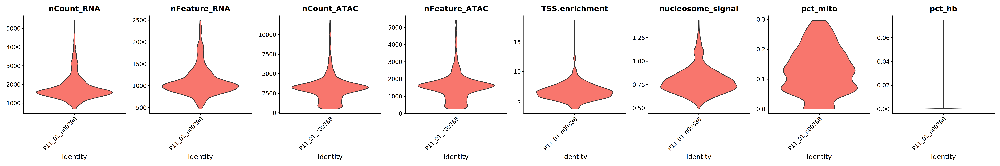

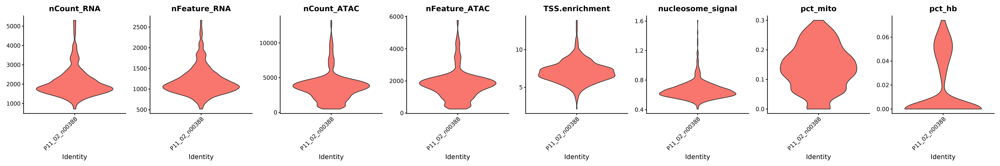

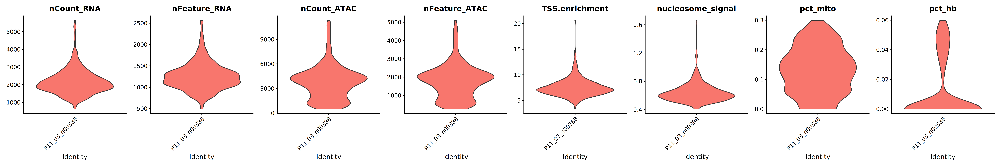

Warning message in SingleExIPlot(type = type, data = data[, x, drop = FALSE], idents = idents, :
“All cells have the same value of pct_hb.”


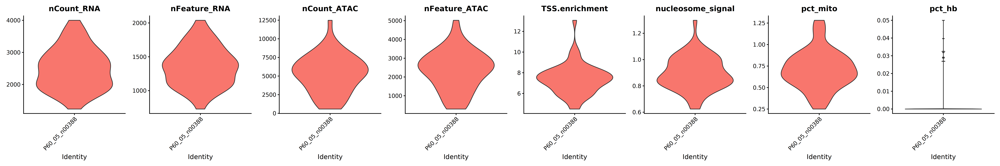

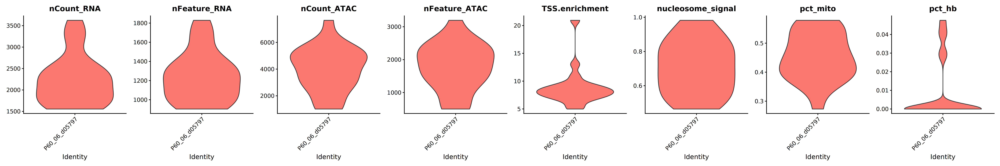

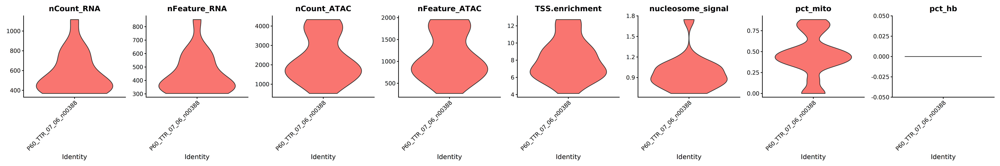

In [ ]:
options(repr.plot.width=30, repr.plot.height=5)
vlns_pre <- c()
for (sample in sample_names){
    s <- subset(endo_noDBL, subset = Sample == sample)
    vln <- VlnPlot(object = s, features = c("nCount_RNA", "nFeature_RNA", "nCount_ATAC", "nFeature_ATAC", "TSS.enrichment", "nucleosome_signal", "pct_mito", "pct_hb"), 
                  ncol = 8, pt.size = 0)
    
    plot_name = paste("", sample, "_noDBL_vln_prefilter.svg")

    print(vln)
    
    ggsave(file=plot_name, plot=vln, width=30, height=5)
    
    
}

# Filtering

In [95]:
table(endo_noDBL$orig.ident)


       P11_01_n00388        P11_02_n00388        P11_03_n00388 
                 502                  620                  442 
       P60_05_n00388        P60_06_d05797 P60_TTR_07_06_n00388 
                  50                   20                   17 

In [96]:
DefaultAssay(endo_noDBL) <- "RNA"

Since we already have the peaks assay we can delete the ATAC assay, which allows to save compuattional resources 

In [97]:
samples.list <- SplitObject(endo_noDBL, split.by = 'Sample')

In [98]:
samples.list

$P11_01_n00388
An object of class Seurat 
195169 features across 502 samples within 2 assays 
Active assay: RNA (32287 features, 0 variable features)
 2 layers present: counts, data
 1 other assay present: ATAC

$P11_02_n00388
An object of class Seurat 
195169 features across 620 samples within 2 assays 
Active assay: RNA (32287 features, 0 variable features)
 2 layers present: counts, data
 1 other assay present: ATAC

$P11_03_n00388
An object of class Seurat 
195169 features across 442 samples within 2 assays 
Active assay: RNA (32287 features, 0 variable features)
 2 layers present: counts, data
 1 other assay present: ATAC

$P60_05_n00388
An object of class Seurat 
195169 features across 50 samples within 2 assays 
Active assay: RNA (32287 features, 0 variable features)
 2 layers present: counts, data
 1 other assay present: ATAC

$P60_06_d05797
An object of class Seurat 
195169 features across 20 samples within 2 assays 
Active assay: RNA (32287 features, 0 variable features)
 2 l

In [99]:
vars_to_regress <- c('Sample')

In [100]:
endo_noDBL <- endo_noDBL %>% 
                            NormalizeData(normalization.method = "LogNormalize", scale.factor = 10000) %>%
                            FindVariableFeatures(selection.method = "vst", nfeatures=4000, ) %>%
                            ScaleData() %>%
                            RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  Slc8a1, Mecom, Pcsk5, Vegfc, Nebl, Eln, Fn1, Fbln2, Ptprj, Vwf 
	   Efna5, Foxp1, Fbln5, Mast4, Cldn5, Gja5, Vim, Jag1, Dst, Edn1 
	   Stmn2, Nrxn3, Col5a2, Cxcl12, Heg1, Thsd7a, Unc13b, Zeb2, Sema3g, Tec 
Negative:  Col4a1, Plvap, Plpp3, Ivns1abp, Piezo2, Enpp2, Igfbp3, Arhgef7, Fbxl18, Prkd1 
	   Col13a1, Kcnq1, Slc23a2, Thbs1, Gpihbp1, Scarb1, Ints6, Ednrb, Dcbld1, Plpp1 
	   Flt1, Lncpint, Ramp3, Hecw2, Plcb1, Pde7b, Kdr, Egr1, Igfbp7, Chrm2 
PC_ 2 
Positive:  Pcsk5, Slc8a1, Nebl, Fbln5, Vegfc, Mecom, Efna5, Enpp2, Fbln2, Atp13a3 
	   Mast4, Ptprj, Fosb, Stmn2, Gm42418, Sema3g, Jag1, Ints6, Tox2, Gja5 
	   Specc1, Prdm16, Tec, Nup210l, Stat3, Bmx, Creb5, Sox17, Plcg2, Rhoj 
Negative:  Col4a1, Piezo2, Plpp1, Plpp3, Snrk, Kdr, Top2a, Rasal2, Knl1, Plvap 
	   Nrp1, Prkd1, Trp53i11, Emcn, Neil3, Tmtc2, Sparcl1, Ivns1abp, Cenpp, Marcks 
	   Ralgps2, Pde7b, Kif15, Arhgap29, Ccdc85a, Rflnb, Itga1, Mki67, Ptk2, Snx13 
PC_ 3 
Positive:  V

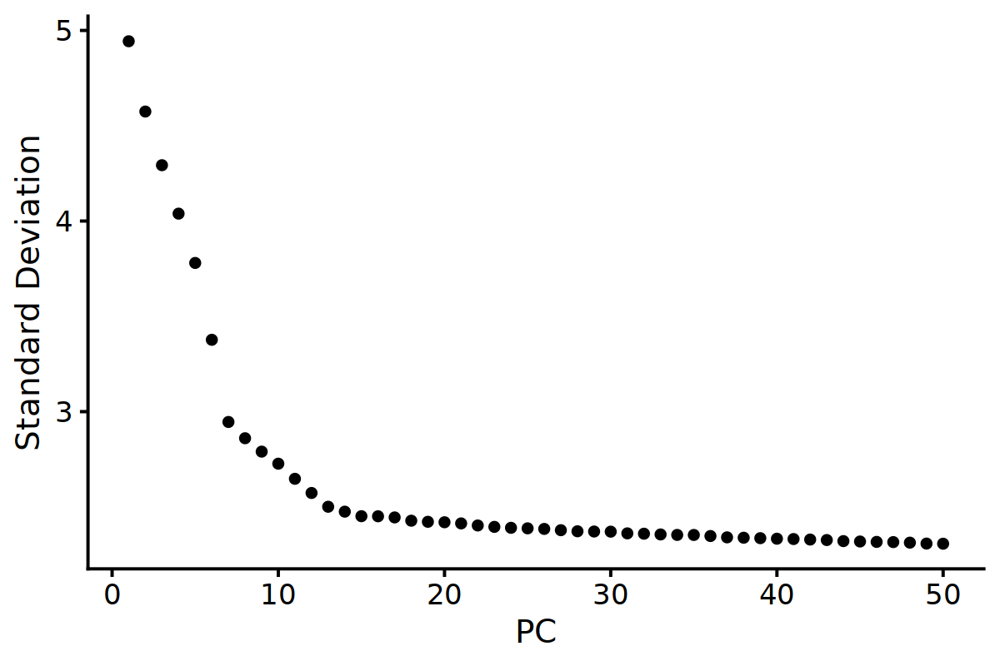

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
pca <- ElbowPlot(endo_noDBL, ndims = 50)

pca

ggsave(file="endo_noDBL_pca.svg", plot=pca, width=6, height=4)

In [90]:
endo_noDBL <- RunUMAP(endo_noDBL, dims = 1:14, reduction = 'pca', n.neighbors = 15)

10:58:24 UMAP embedding parameters a = 0.9922 b = 1.112

10:58:24 Read 1647 rows and found 14 numeric columns

10:58:24 Using Annoy for neighbor search, n_neighbors = 15

10:58:24 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

10:58:24 Writing NN index file to temp file /scratch/49978710/RtmpWxnPCb/file57834092b57e

10:58:24 Searching Annoy index using 1 thread, search_k = 1500

10:58:25 Annoy recall = 100%

10:58:26 Commencing smooth kNN distance calibration using 1 thread

10:58:29 Initializing from normalized Laplacian + noise

10:58:29 Commencing optimization for 500 epochs, with 31624 positive edges

10:58:34 Optimization finished



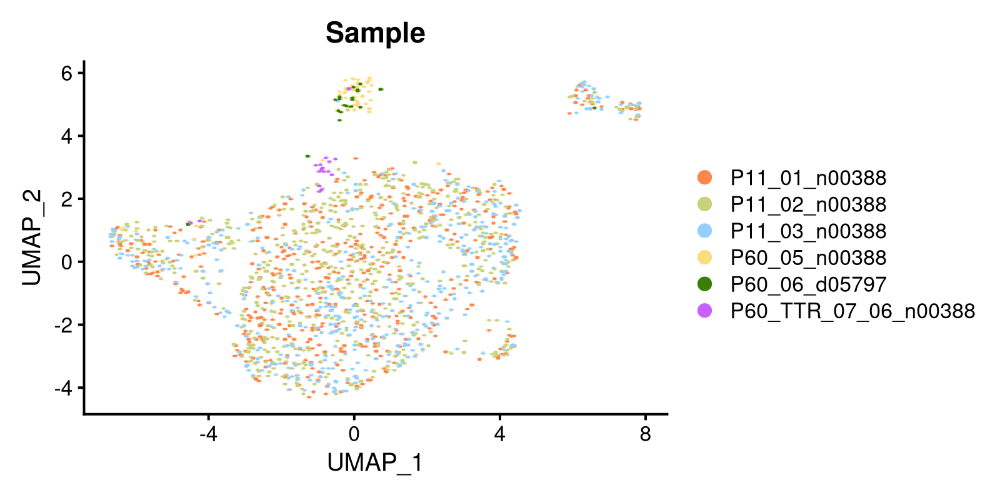

In [ ]:
options(repr.plot.width = 8, repr.plot.height = 4, repr.plot.res = 200)
dpl <- DimPlot(endo_noDBL, reduction = 'umap', group.by = 'Sample', pt.size = 1.5, raster = TRUE, cols = my_c)

dpl

ggsave(file="endo_noDBL_RNA_UMAP.svg", plot=dpl, width=8, height=4)

**NOTE**:The functions *get_density* and *DensityScatter* are from the packages Signac V 1.10, since we are using the version 1.4 we copied only the necessary function to plot the wanted plots.

In [92]:
get_density <- function(x, y, ...) {
  if (!requireNamespace("MASS", quietly = TRUE)) {
    stop("Please install MASS: install.packages('MASS')")
  }
  if (!is.numeric(x = x) | !is.numeric(x = y)) {
      stop("Must supply numeric values")
  }
  dens <- MASS::kde2d(x = x, y = y, ...)
  ix <- findInterval(x = x, vec = dens$x)
  iy <- findInterval(x = y, vec = dens$y)
  ii <- cbind(ix, iy)
  return(dens$z[ii])
}

In [93]:
DensityScatter <- function(
    object,
    x,
    y,
    log_x = FALSE,
    log_y = FALSE,
    quantiles = NULL
) {
    md <- object[[]]
    if (!(x %in% colnames(x = md))) {
        stop(x, " not found")
    }
    if (!(y %in% colnames(x = md))) {
        stop(y, " not found")
    }
    log10p <- function(x) {
        return(log10(x = x + 1))
    }
    null_fn <- function(x) {
        return(x)
    }
    logfnx <- ifelse(test = log_x, yes = log10p, no = null_fn)
    logfny <- ifelse(test = log_y, yes = log10p, no = null_fn)
    # logfny <- null_fn
    md$Density <- get_density(
        x = logfnx(md[[x]]),
        y = logfny(md[[y]]),
        n = 1000,
        h = c(1,1)
    )
    md <- md[order(md$Density), ]
    # quantiles
    use_quantile <- FALSE
    if (!is.null(x = quantiles)) {
        use_quantile <- TRUE
        # set default if TRUE passed
        if (is.logical(x = quantiles)) {
            if (quantiles) {
                quantiles <- c(5, 10, 90, 95)
            } else {
                use_quantile <- FALSE
            }
        }
        # make sure integers between 0 and 100
        if (!(all(quantiles >= 0) & all(quantiles <= 100))) {
            warning("Quantile values must be between 0 and 100",
                    immediate. = TRUE)
            use_quantile <- FALSE
        }
        if (any(sapply(X = quantiles, FUN = function(x) x %% 1 != 0))) {
            warning("Quantile values must be integers",
                    immediate. = TRUE)
            use_quantile <- FALSE
        }
    }
    if (use_quantile) {
        # convert to string
        quantiles <- paste0(quantiles, '%')

        # quantiles for x and y
        x_quant <- quantile(x = md[[x]], probs = seq(0, 1, 0.01))
        y_quant <- quantile(x = md[[y]], probs = seq(0, 1, 0.01))
        xlines <- x_quant[quantiles]
        ylines <- y_quant[quantiles]

        # round
        xlines <- round(x = xlines, digits = 2)
        ylines <- round(x = ylines, digits = 2)
    }        
    p <- ggplot(
           data = md,
           mapping = aes(x = .data[[x]], y = .data[[y]], color = .data[["Density"]])
         ) +
           geom_point(size = 1) +
           scale_color_viridis_c(option = "B") +
           theme_bw()
    if (log_x) {
        p <- p + scale_x_log10()
    }
    if (log_y) {
        p <- p + scale_y_log10()
    }
    if (use_quantile) {
        p <- p +
          geom_vline(xintercept = unname(obj = xlines), color = "red") +
          geom_hline(yintercept = unname(obj = ylines), color = "red") +
          labs(title = "Quantiles",
               subtitle = paste0(x, ": ", paste0(names(x = xlines), ":",
                                                 xlines, collapse = " "), "\n",
                                 y, ": ", paste0(names(x = ylines), ":",
                                                 ylines, collapse = " ")))
    }
    return(p)
}

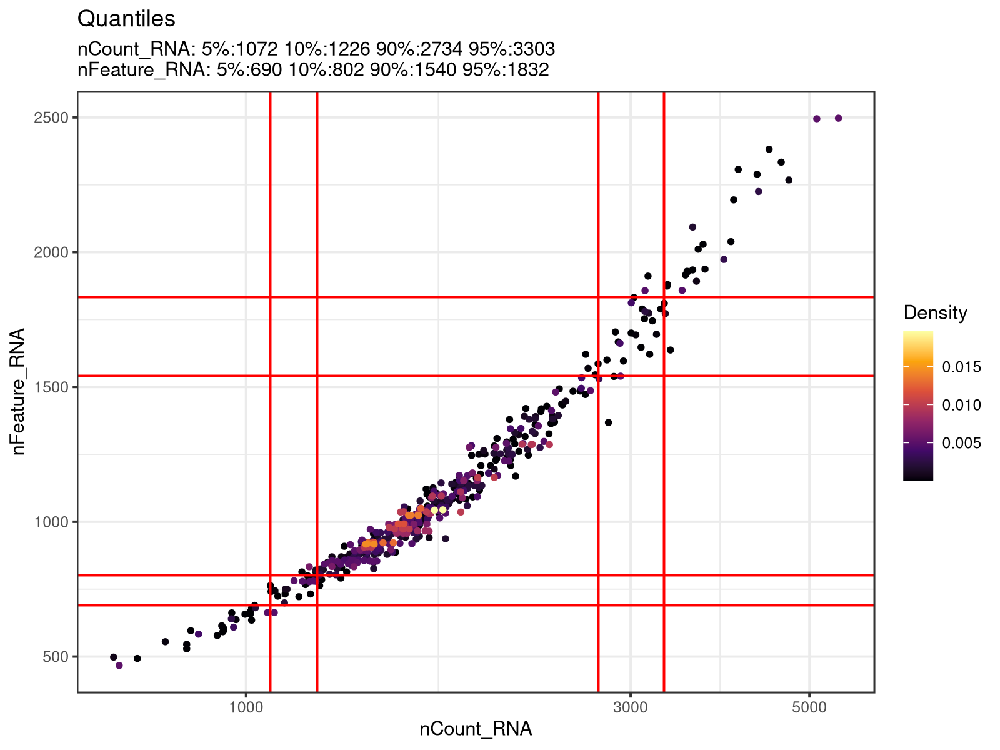

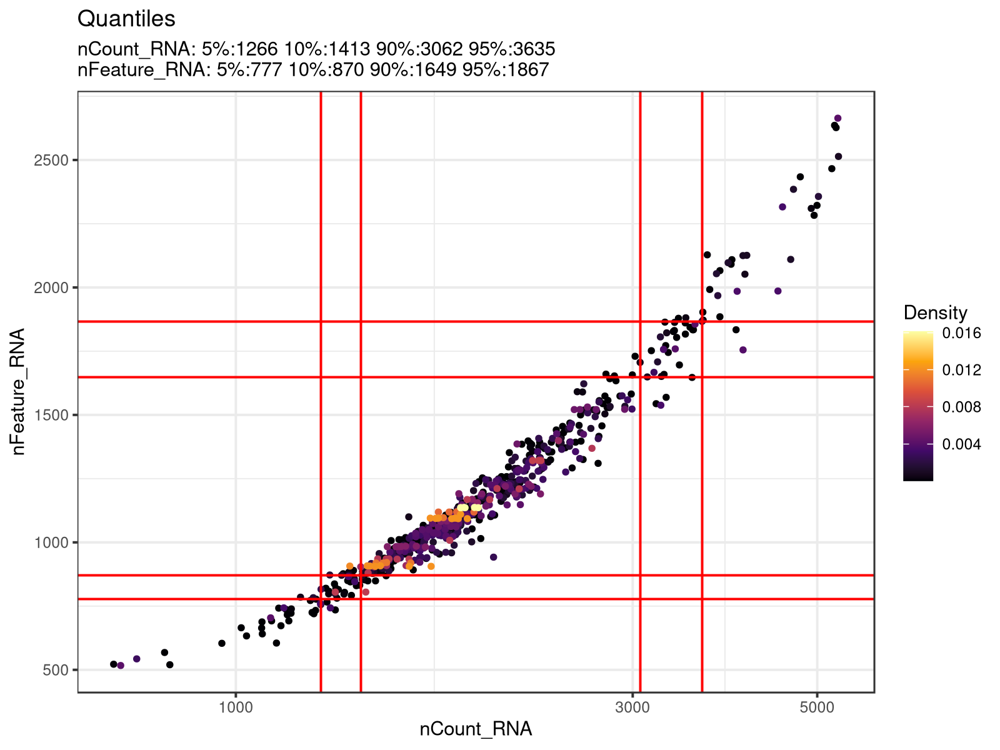

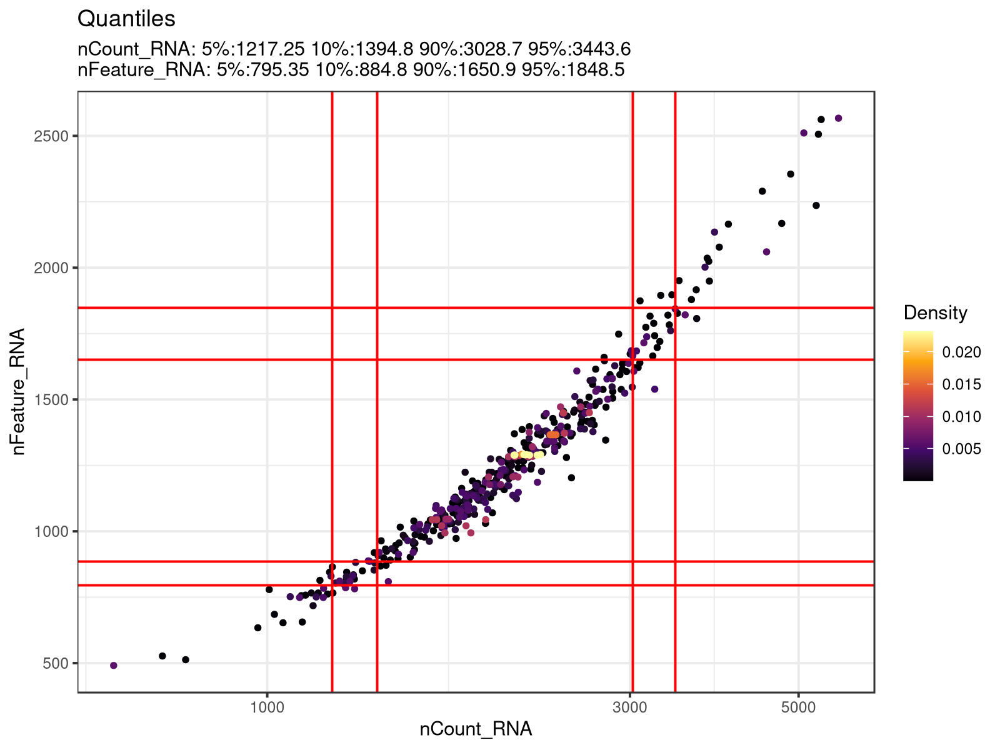

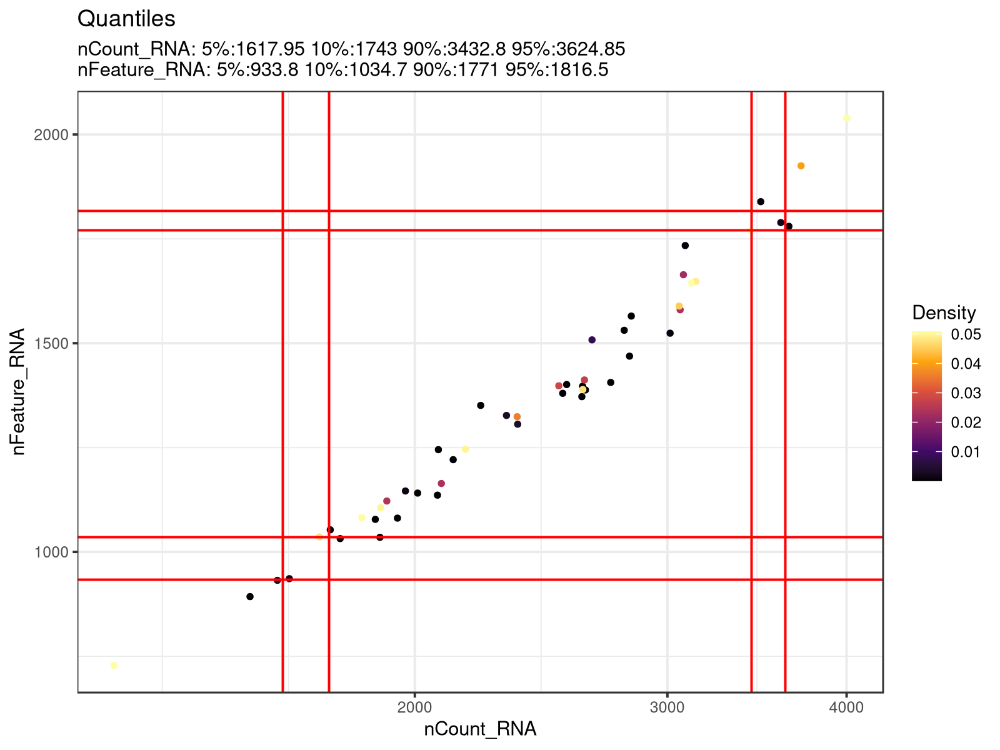

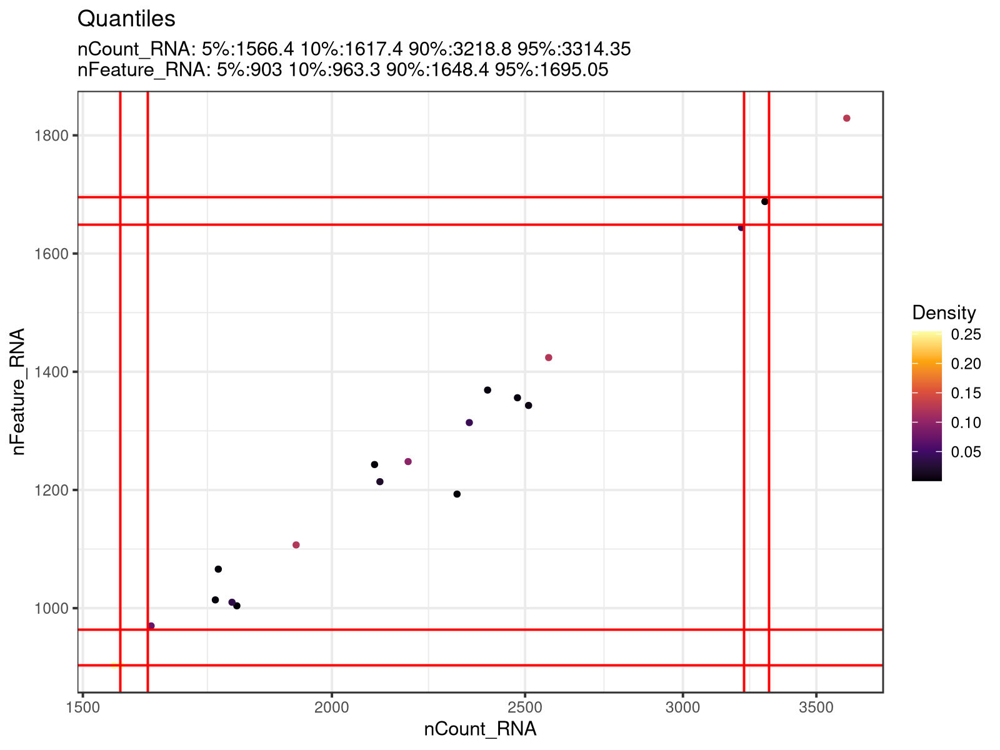

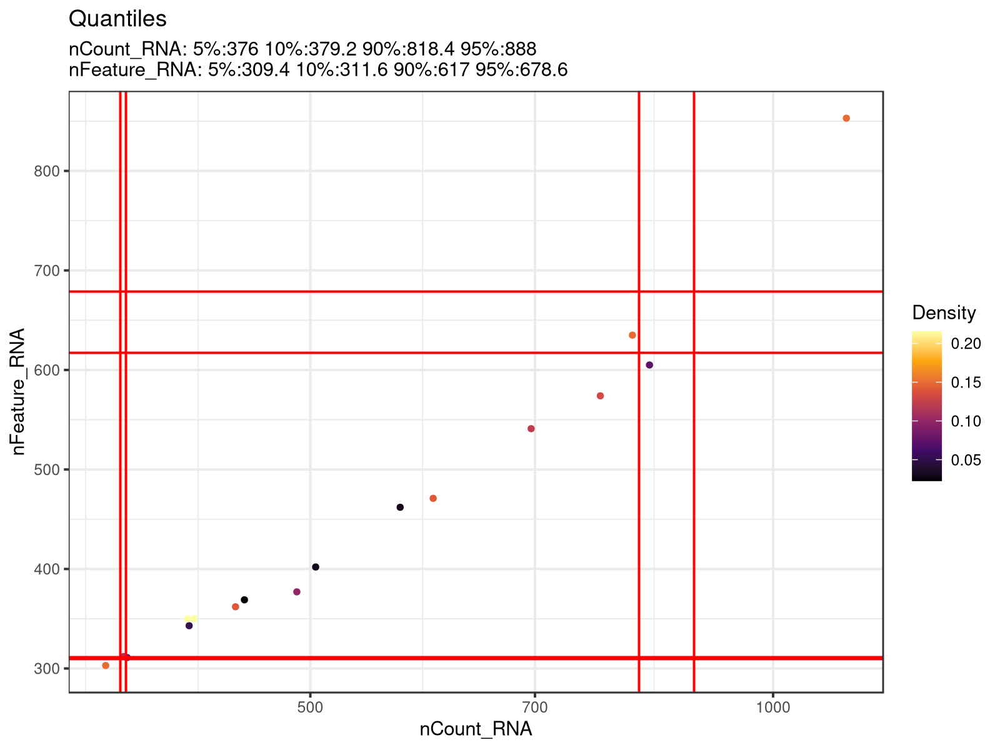

In [ ]:
options(repr.plot.width=30, repr.plot.height=5)
vlns_pre <- c()
for (sample in sample_names){
    s <- subset(endo_noDBL, subset = Sample == sample)
    scatterplt <- DensityScatter(object = s, x = 'nCount_RNA', y = 'nFeature_RNA', log_x = TRUE, quantiles = TRUE)
    
    plot_name = paste("", sample, "Densenty_scatter_prefilter_nodbl_RNA.svg")
    #vlns_pre <- c(vlns_pre, vln)
    options(repr.plot.width = 8, repr.plot.height = 6)
    print(scatterplt)
    
    ggsave(file=plot_name, plot=scatterplt, width=8, height=6)
    
    
}

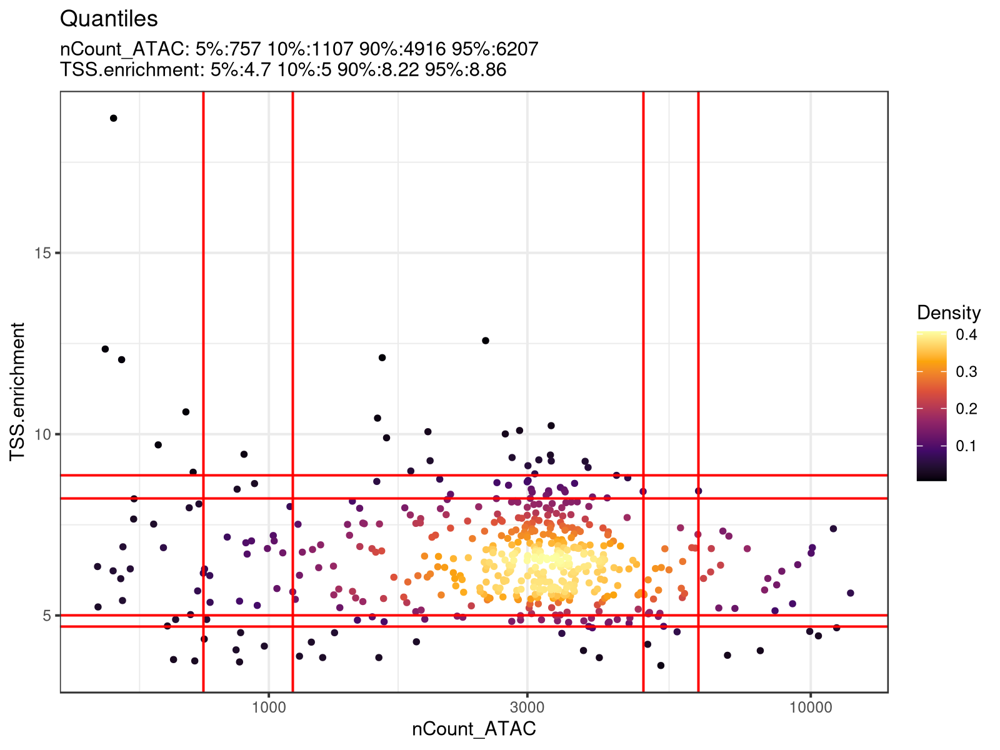

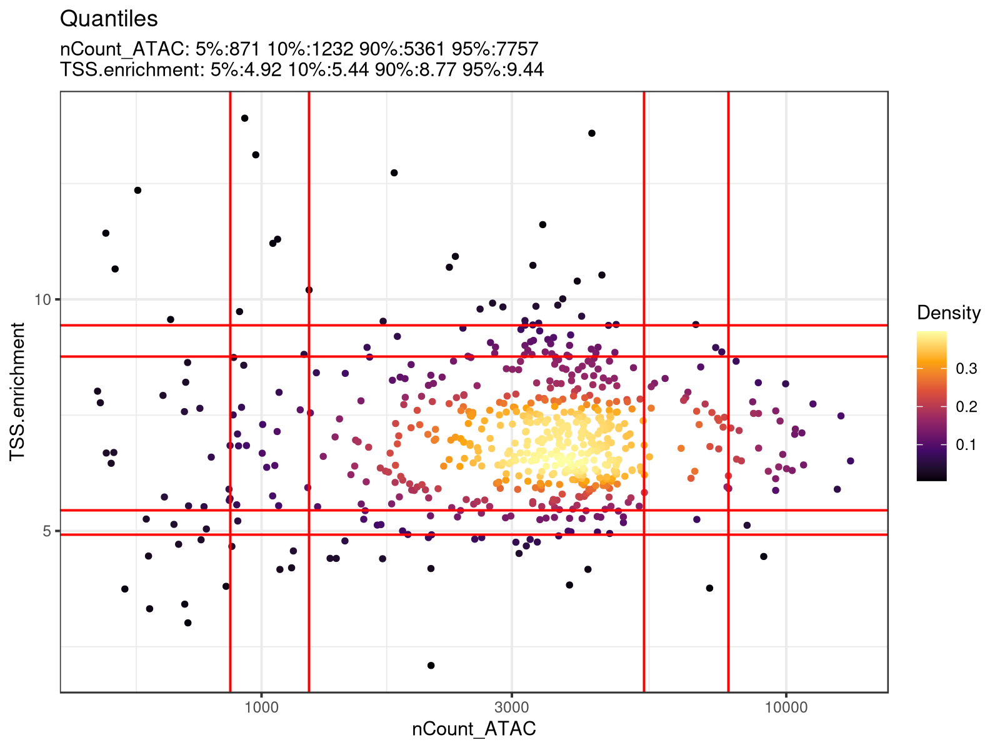

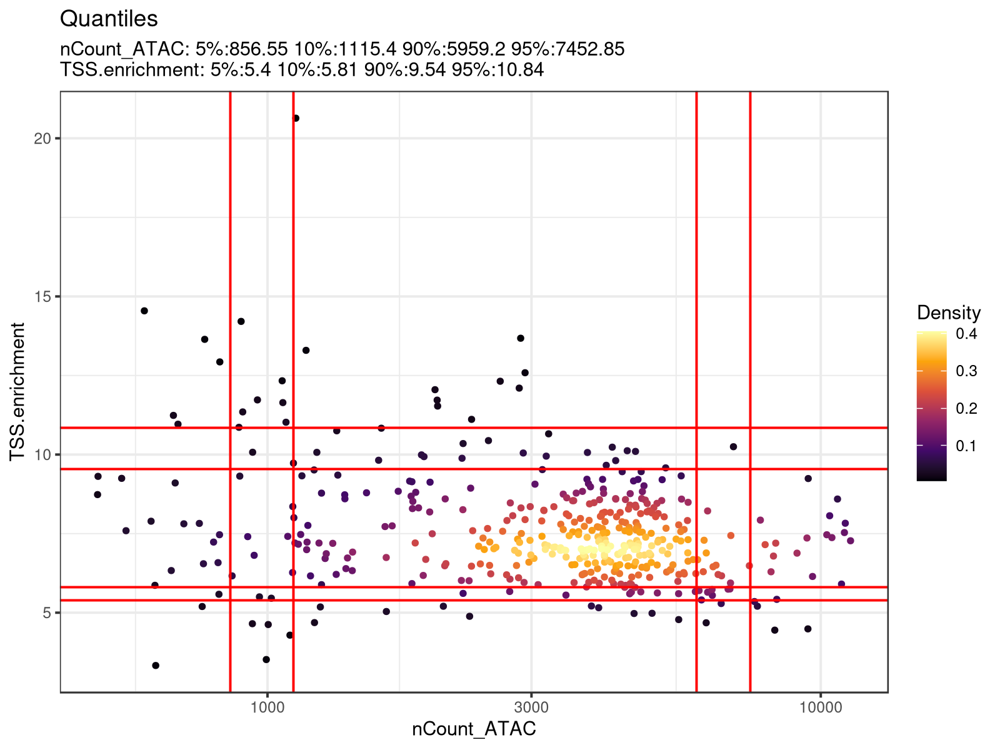

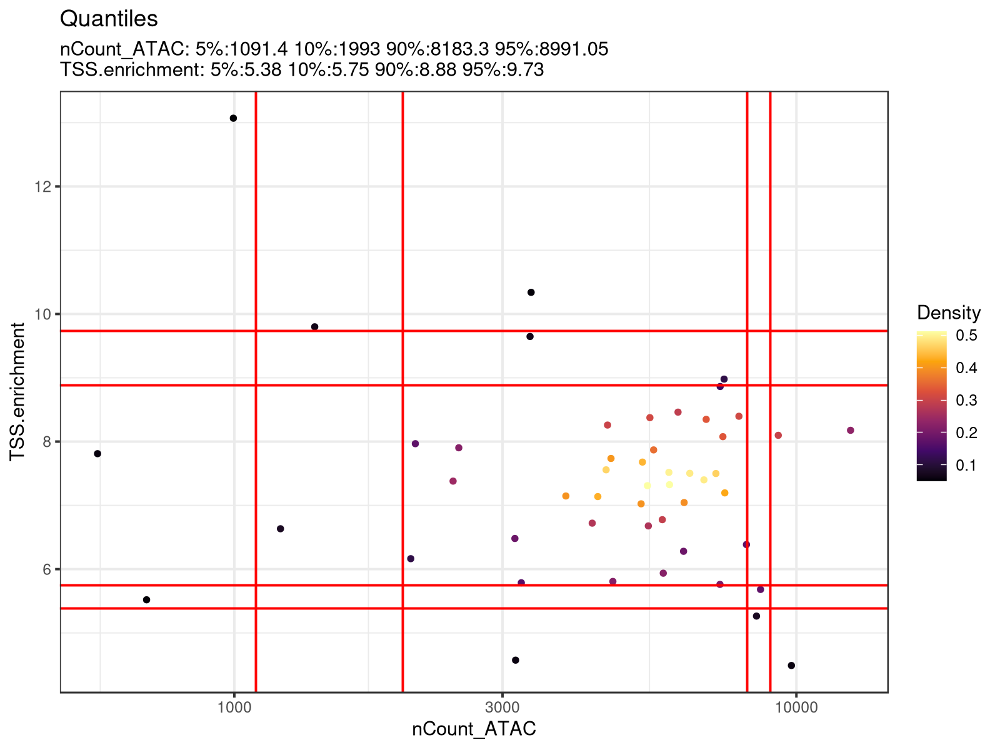

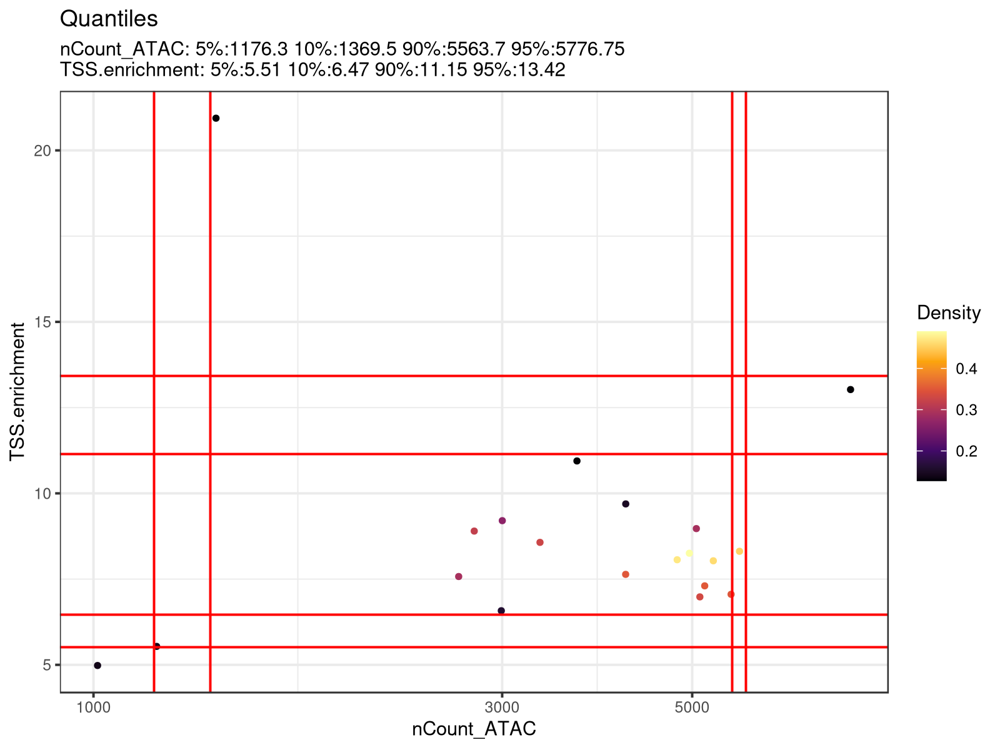

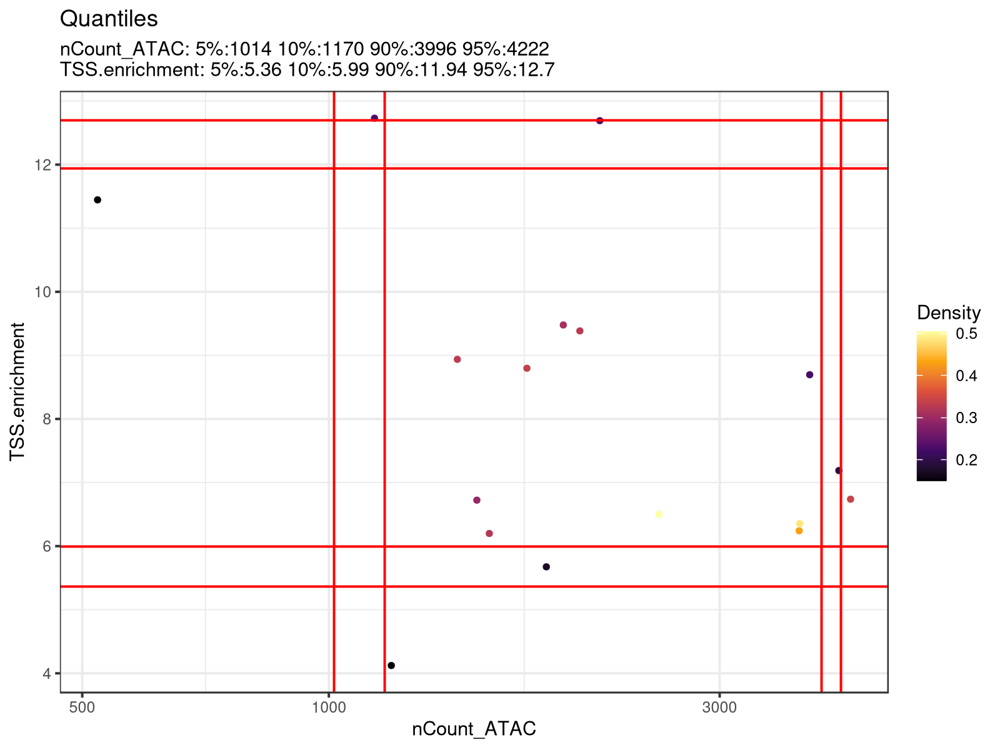

In [ ]:
options(repr.plot.width=30, repr.plot.height=5)
vlns_pre <- c()
for (sample in sample_names){
    s <- subset(endo_noDBL, subset = Sample == sample)
    scatterplt <- DensityScatter(object = s, x = 'nCount_ATAC', y = 'TSS.enrichment', log_x = TRUE, quantiles = TRUE)
    
    plot_name = paste("", sample, "Densenty_scatter_prefilter_nodbl.svg")

    options(repr.plot.width = 8, repr.plot.height = 6)
    print(scatterplt)
    
    ggsave(file=plot_name, plot=scatterplt, width=8, height=6)
    
    
}

In [102]:

nCount_RNA_max <- c(4000, 4200, 4000, 5000, 4000, 2000)

nCount_RNA_min <- c(250, 250, 250, 250, 250, 250)

nFeature_RNA_max <- c(2800, 2500, 2900, 2500, 2000, 1200)

nFeature_RNA_min <- c(250, 250, 250, 250, 250, 250)

nCount_ATAC_max <- c(85000, 12500, 12500, 12500, 90000, 5000)

nCount_ATAC_min <- c(400, 400, 400, 450, 600, 200)

nFeature_ATAC_max <- c(4500, 5700, 5800, 5000, 4000, 3000)

nFeature_ATAC_min <- c(250, 250, 250, 250, 250, 250)

nucleosome_signal_max <- c(2.0, 2.0, 2.0, 2.0, 2.0, 2.0)

TSS.enrichment_min <- c(2.0, 2.0, 2.0, 2.0, 2.0, 2.0)

pct_mito_max <- c(0.3, 0.3, 0.3, 1.3, 0.7, 1.2)

pct_hb_max <- c(0.075, 0.075, 0.06, 0.05, 0.05, 0.05)


In [103]:
options(repr.plot.width=30, repr.plot.height=5)
cells_to_keep <- c()

[1] "P11_01_n00388"
An object of class Seurat 
195169 features across 502 samples within 2 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: ATAC
 1 dimensional reduction calculated: pca
[1] 4000
[1] 85000
[1] 250
[1] 400
[1] 2800
[1] 4500
[1] 250
[1] 250
[1] 2
[1] 2
[1] 0.3
[1] 0.075
[1] 489
[1] 489
[1] "P11_02_n00388"
An object of class Seurat 
195169 features across 620 samples within 2 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: ATAC
 1 dimensional reduction calculated: pca
[1] 4200
[1] 12500
[1] 250
[1] 400
[1] 2500
[1] 5700
[1] 250
[1] 250
[1] 2
[1] 2
[1] 0.3
[1] 0.075
[1] 605
[1] 1094


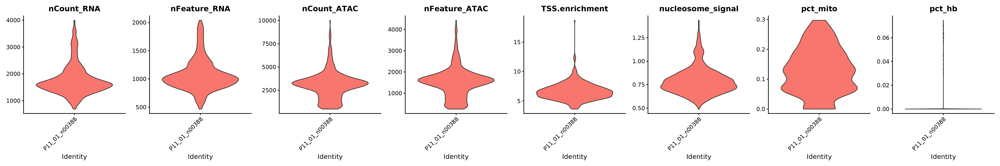

[1] "P11_03_n00388"
An object of class Seurat 
195169 features across 442 samples within 2 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: ATAC
 1 dimensional reduction calculated: pca
[1] 4000
[1] 12500
[1] 250
[1] 400
[1] 2900
[1] 5800
[1] 250
[1] 250
[1] 2
[1] 2
[1] 0.3
[1] 0.06
[1] 432
[1] 1526


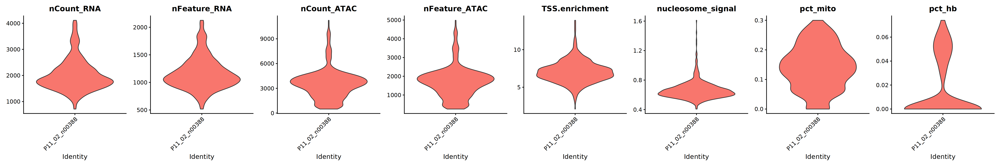

[1] "P60_05_n00388"
An object of class Seurat 
195169 features across 50 samples within 2 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: ATAC
 1 dimensional reduction calculated: pca
[1] 5000
[1] 12500
[1] 250
[1] 450
[1] 2500
[1] 5000
[1] 250
[1] 250
[1] 2
[1] 2
[1] 1.3
[1] 0.05
[1] 49
[1] 1575


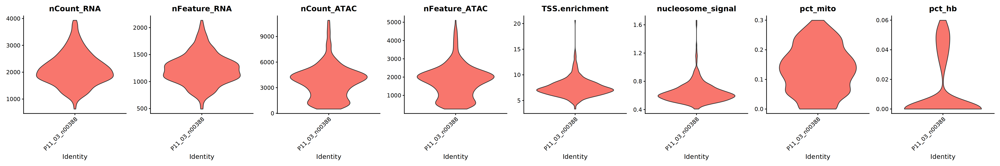

[1] "P60_06_d05797"
An object of class Seurat 
195169 features across 20 samples within 2 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: ATAC
 1 dimensional reduction calculated: pca
[1] 4000
[1] 90000
[1] 250
[1] 600
[1] 2000
[1] 4000
[1] 250
[1] 250
[1] 2
[1] 2
[1] 0.7
[1] 0.05
[1] 20
[1] 1595
[1] "P60_TTR_07_06_n00388"
An object of class Seurat 
195169 features across 17 samples within 2 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: ATAC
 1 dimensional reduction calculated: pca
[1] 2000
[1] 5000
[1] 250
[1] 200
[1] 1200
[1] 3000
[1] 250
[1] 250
[1] 2
[1] 2
[1] 1.2
[1] 0.05
[1] 17
[1] 1612


Warning message in SingleExIPlot(type = type, data = data[, x, drop = FALSE], idents = idents, :
“All cells have the same value of pct_hb.”


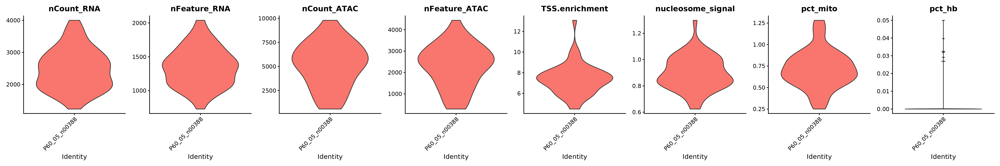

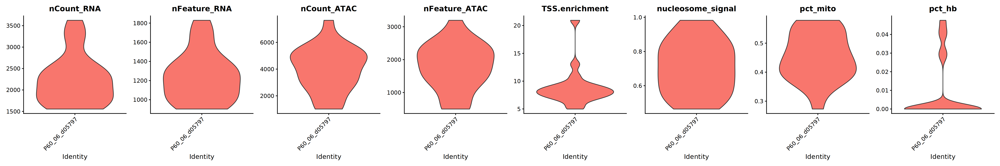

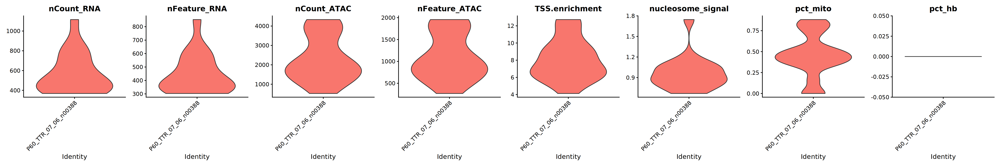

In [ ]:
for (i in 1:length(sample_names)){
    sample <- sample_names[i]
    print(sample)

    s <- subset(endo_noDBL, subset = Sample == sample)

    print(s)
    
    print(nCount_RNA_max[i])
    print(nCount_ATAC_max[i])
    print(nCount_RNA_min[i])
    print(nCount_ATAC_min[i])
    print(nFeature_RNA_max[i])
    print(nFeature_ATAC_max[i])
    print(nFeature_RNA_min[i])
    print(nFeature_ATAC_min[i])
    print(nucleosome_signal_max[i])
    print(TSS.enrichment_min[i])
    print(pct_mito_max[i])
    print(pct_hb_max[i])
      
      
    s <-  subset(s, subset=nCount_RNA < nCount_RNA_max[i] &
                      nCount_ATAC < as.numeric(nCount_ATAC_max[i]) &
                      nCount_RNA > as.numeric(nCount_RNA_min[i]) &
                      nCount_ATAC > as.numeric(nCount_ATAC_min[i]) &
                      nFeature_RNA < as.numeric(nFeature_RNA_max[i]) &
                      nFeature_ATAC < as.numeric(nFeature_ATAC_max[i]) &
                      nFeature_RNA > as.numeric(nFeature_RNA_min[i]) &
                      nFeature_ATAC > as.numeric(nFeature_ATAC_min[i]) &
                      nucleosome_signal < as.numeric(nucleosome_signal_max[i]) &
                      TSS.enrichment > as.numeric(TSS.enrichment_min[i]) &
                      pct_mito < as.numeric(pct_mito_max[i]) &
                      pct_hb < as.numeric(pct_hb_max[i]))
    
    cells_to_keep <- c(cells_to_keep, colnames(s))
    
    print(length(colnames(s)))
    print(length(cells_to_keep))
    
    vln <- VlnPlot(object = s, features = c("nCount_RNA", "nFeature_RNA", "nCount_ATAC", "nFeature_ATAC", "TSS.enrichment", "nucleosome_signal", "pct_mito", "pct_hb"), 
                  ncol = 8, pt.size = 0)
    
    print(vln)

    plot_name = paste("", sample, "_noDBL_vln_afterfilter.svg")

    
    ggsave(file=plot_name, plot=vln, width=30, height=5)
    
}

In [105]:
endo_noDBL_filt <- subset(endo_noDBL, cells = cells_to_keep)

In [106]:
table(endo_noDBL_filt$orig.ident)


       P11_01_n00388        P11_02_n00388        P11_03_n00388 
                 489                  605                  432 
       P60_05_n00388        P60_06_d05797 P60_TTR_07_06_n00388 
                  49                   20                   17 

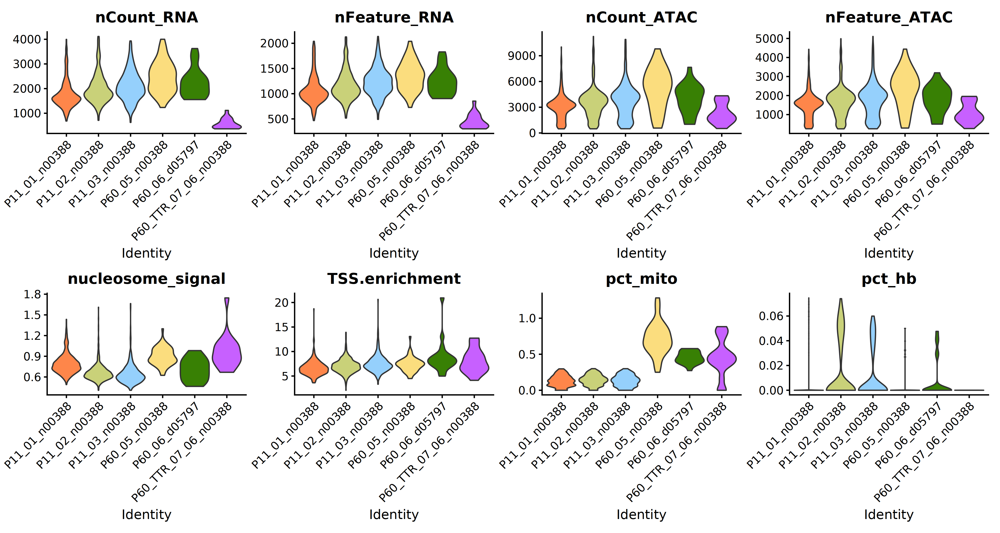

In [ ]:
options(repr.plot.width = 15, repr.plot.height = 8, repr.plot.res = 300)

vln <- VlnPlot(endo_noDBL_filt, features=c('nCount_RNA', 'nFeature_RNA', 'nCount_ATAC', 'nFeature_ATAC', 'nucleosome_signal', 'TSS.enrichment', 'pct_mito', 'pct_hb'), 
        ncol=4, pt.size=0, col = my_c) 

vln

ggsave(file="endo_noDBL_all_vln_after_filter.svg", plot=vln, width=15, height=8)


In [ ]:
saveRDS(endo_noDBL_filt, 'Endo_noDBL_filt_multiome.rds')

# Call peaks

In [ ]:
endo_noDBL_filt <- readRDS('Endo_noDBL_filt_multiome.rds')

In [21]:
endo_noDBL_filt

An object of class Seurat 
195169 features across 1612 samples within 2 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: ATAC
 1 dimensional reduction calculated: pca

In [22]:
DefaultAssay(endo_noDBL_filt) <- 'ATAC'

In [23]:
# call peaks using MACS2
peaks <- CallPeaks(object=endo_noDBL_filt, 
                outdir='callpeaks', cleanup=FALSE)

In [24]:
# remove peaks on nonstandard chromosomes and in genomic blacklist regions
peaks <- keepStandardChromosomes(peaks, pruning.mode = "coarse")
peaks <- subsetByOverlaps(peaks, ranges = blacklist_mm10, invert = TRUE)

In [25]:
macs2_counts <- FeatureMatrix(fragments = Fragments(endo_noDBL_filt), features = peaks, cells = colnames(endo_noDBL_filt))

Extracting reads overlapping genomic regions

Extracting reads overlapping genomic regions

Extracting reads overlapping genomic regions

Extracting reads overlapping genomic regions

Extracting reads overlapping genomic regions

Extracting reads overlapping genomic regions



In [26]:
endo_noDBL_filt[['peaks']] <- CreateChromatinAssay(counts = macs2_counts, sep = c('-', '-'), fragments = Fragments(endo_noDBL_filt), 
                                             annotation = annotation)

In [27]:
endo_noDBL_filt@assays

$RNA
Assay data with 32287 features for 1612 cells
Top 10 variable features:
 Kirrel3, Selp, Slc8a1, Pcdh9, Nrxn3, Dach1, Mecom, Eln, Fn1, Dkk2 

$ATAC
ChromatinAssay data with 162882 features for 1612 cells
Variable features: 0 
Genome: 
Annotation present: TRUE 
Motifs present: FALSE 
Fragment files: 6 

$peaks
ChromatinAssay data with 183223 features for 1612 cells
Variable features: 0 
Genome: 
Annotation present: TRUE 
Motifs present: FALSE 
Fragment files: 6 


In [28]:
DefaultAssay(endo_noDBL_filt) <- 'peaks'

In [29]:
endo_noDBL_filt[['ATAC']] <- NULL

# FRiP

In [53]:
endo_noDBL_filt <- FRiP(endo_noDBL_filt, assay = 'peaks', total.fragments = "nCount_ATAC", col.name = 'FRiP', verbose = TRUE)

Calculating fraction of reads in peaks per cell



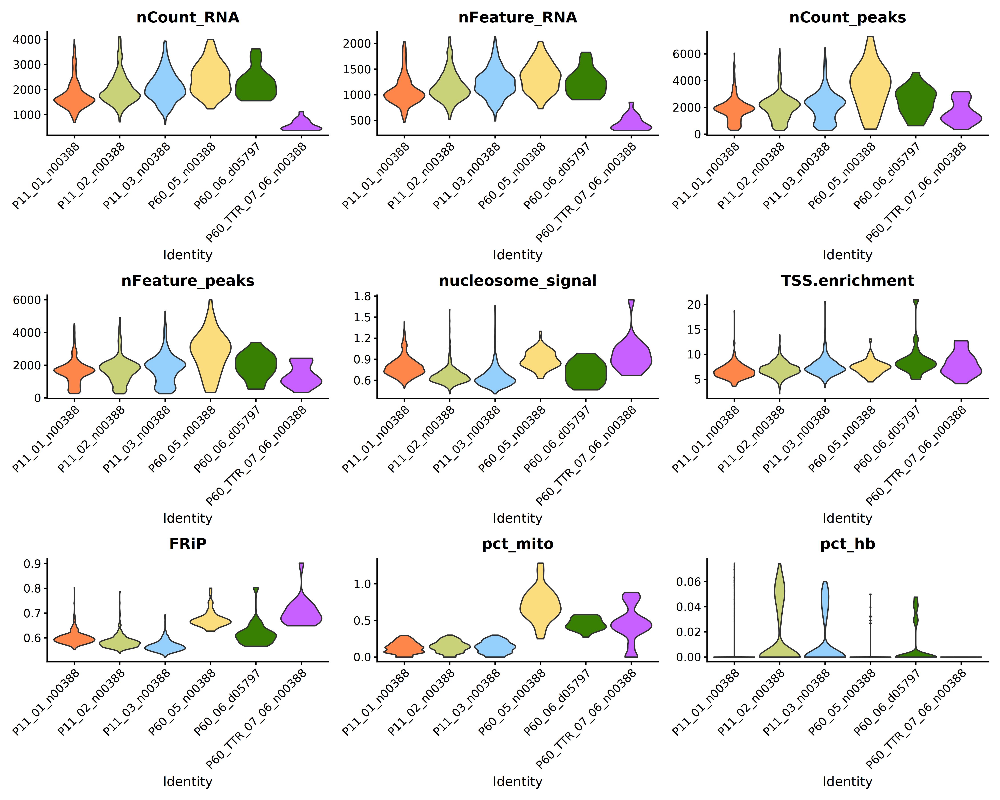

In [ ]:
options(repr.plot.width = 15, repr.plot.height = 12, repr.plot.res = 300)

vln <- VlnPlot(endo_noDBL_filt, features=c('nCount_RNA', 'nFeature_RNA', 'nCount_peaks', 'nFeature_peaks', 'nucleosome_signal', 'TSS.enrichment', 'FRiP', 'pct_mito', 'pct_hb'), 
        ncol=3, pt.size=0, col = my_c) 

vln

ggsave(file="Endothelial_endo_noDBL_filt_vln_pre_filter_frip.svg", plot=vln, width=15, height=12)


In [ ]:
saveRDS(endo_noDBL_filt, 'Endothelial_noDBL_endo_filt_multiome_peaks.rds')

# Downstream analysis

In [ ]:
endo_noDBL_filt <- readRDS('Endothelial_noDBL_endo_filt_multiome_peaks.rds')

In [33]:
DefaultAssay(endo_noDBL_filt) <- "RNA"

## RNA

In [34]:
endo_noDBL_filt@assays

$RNA
Assay data with 32287 features for 1612 cells
Top 10 variable features:
 Kirrel3, Selp, Slc8a1, Pcdh9, Nrxn3, Dach1, Mecom, Eln, Fn1, Dkk2 

$peaks
ChromatinAssay data with 183223 features for 1612 cells
Variable features: 0 
Genome: 
Annotation present: TRUE 
Motifs present: FALSE 
Fragment files: 6 


In [35]:
table(endo_noDBL_filt$orig.ident)


       P11_01_n00388        P11_02_n00388        P11_03_n00388 
                 489                  605                  432 
       P60_05_n00388        P60_06_d05797 P60_TTR_07_06_n00388 
                  49                   20                   17 

In [36]:
vars_to_regress <- c('Sample')

In [37]:
endo_noDBL_filt <- endo_noDBL_filt %>% 
                            NormalizeData(normalization.method = "LogNormalize", scale.factor = 10000) %>%
                            FindVariableFeatures(selection.method = "vst", nfeatures=4000, ) %>%
                            ScaleData(vars.to.regress = vars_to_regress) %>%
                            RunPCA() 

Regressing out Sample

Centering and scaling data matrix

PC_ 1 
Positive:  Col4a1, Piezo2, Plpp3, Plvap, Ivns1abp, Arhgef7, Prkd1, Pde7b, Igfbp3, Plpp1 
	   Kcnq1, Kdr, Dcbld1, Slc23a2, Hecw2, Plcb1, Scarb1, Lncpint, Tmtc2, Col13a1 
	   Ednrb, Flt1, Gpihbp1, Igfbp7, Ints6, Chrm2, Samd4, Fbxl18, Thbs1, Oxr1 
Negative:  Slc8a1, Mecom, Pcsk5, Vegfc, Nebl, Eln, Fn1, Ptprj, Fbln2, Efna5 
	   Vwf, Gja5, Fbln5, Cldn5, Stmn2, Sema3g, Nrxn3, Foxp1, Mast4, Thsd7a 
	   Jag1, Vim, Cxcl12, Edn1, Bmx, Olfml2a, Dst, Tec, Col5a2, Atp13a3 
PC_ 2 
Positive:  Plpp1, Marcks, Shroom2, Zcchc7, Piezo2, Rflnb, Snx13, Mrtfb, Kdr, Plpp3 
	   Nrp1, Ccdc85a, Arhgap29, Rdx, Tmsb4x, Cd34, Emcn, Chrm3, Trp53i11, Dennd1b 
	   Vwf, Tspan18, Trpc3, Top2a, Ralgps2, Zfp280d, Slc44a1, Neil3, Cntln, Adgrg6 
Negative:  Ints6, Nup210l, Rhoj, Fosb, Stat3, Dleu2, Adamts9, Arhgef7, Pdlim5, Zswim6 
	   Apold1, Hivep2, Egr1, Slc38a2, Ube2h, Prkcg, Spag9, Chd4, Tssc4, Tut7 
	   Myo1e, Adamts1, Pcsk5, Dlgap4, Hsph1, Elf1, Egr3, Sc

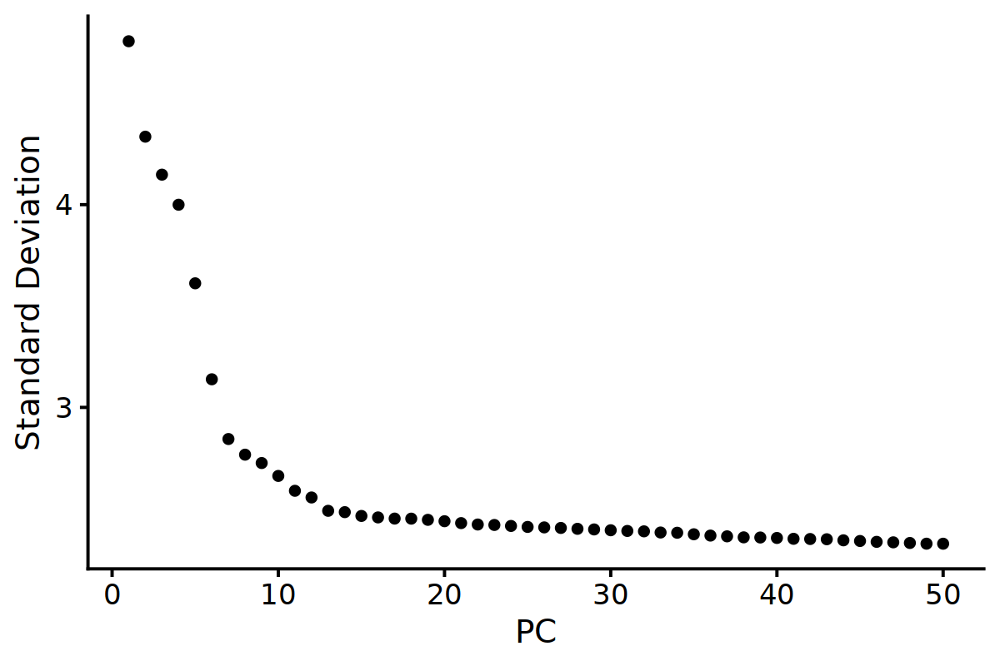

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
pca <- ElbowPlot(endo_noDBL_filt, ndims = 50)

pca

ggsave(file="endo_noDBL_aff_pca.svg", plot=pca, width=6, height=4)

In [39]:
endo_noDBL_filt <- RunUMAP(endo_noDBL_filt, dims = 1:13, reduction = 'pca', n.neighbors = 15, reduction.name="umap_RNA")

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
17:07:33 UMAP embedding parameters a = 0.9922 b = 1.112

17:07:33 Read 1612 rows and found 13 numeric columns

17:07:33 Using Annoy for neighbor search, n_neighbors = 15

17:07:33 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

17:07:33 Writing NN index file to temp file /tmp/RtmpcPWQYU/file4173ab9cdc93

17:07:33 Searching Annoy index using 1 thread, search_k = 1500

17:07:33 Annoy recall = 100%

17:07:35 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors =

In [40]:
unique(endo_noDBL_filt$Age)

[1] "P11" "P60"

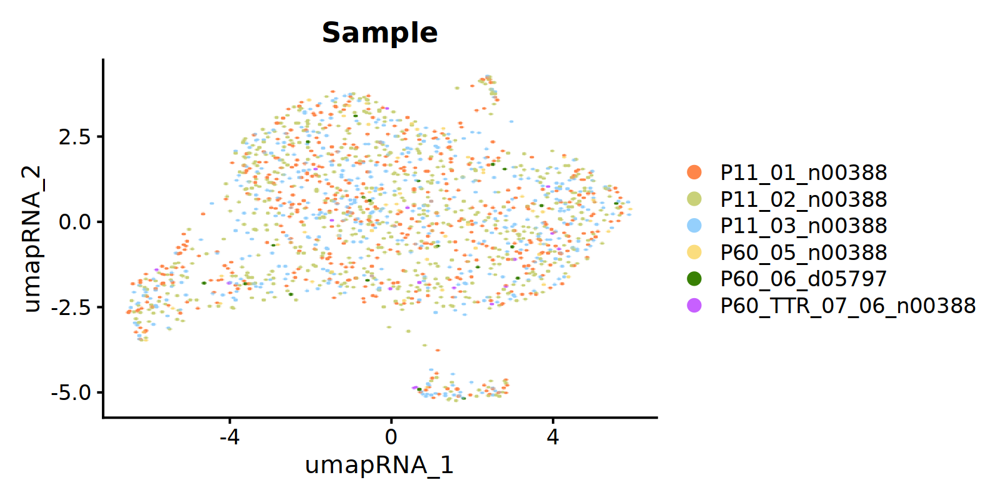

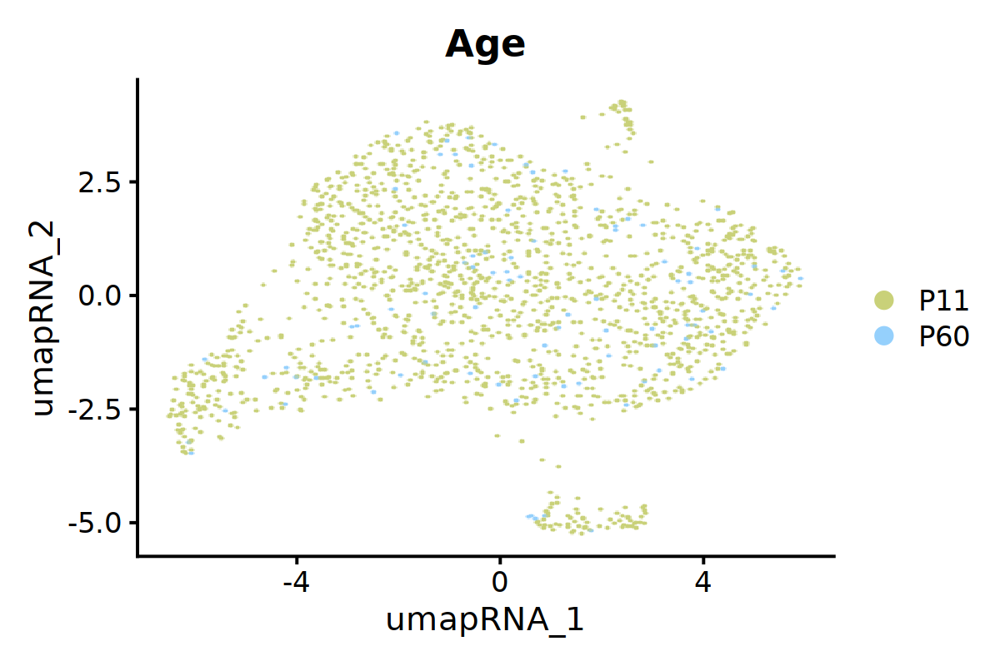

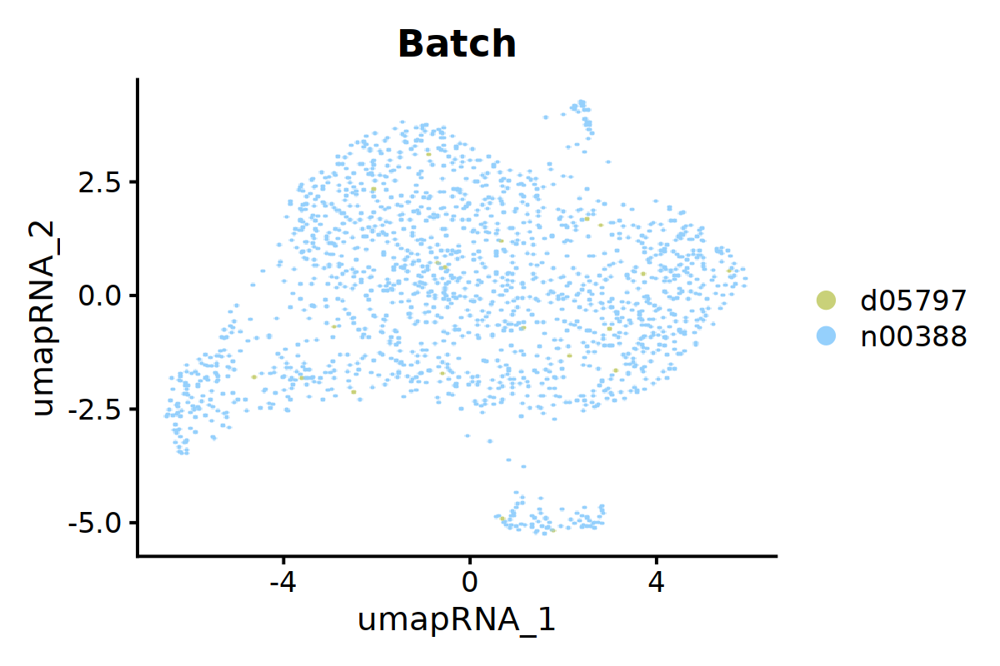

In [ ]:
options(repr.plot.width = 8, repr.plot.height = 4, repr.plot.res = 200)
before_umap_s <- DimPlot(endo_noDBL_filt, reduction = 'umap_RNA', group.by = 'Sample', pt.size = 2.5, raster = TRUE, cols = my_c)

before_umap_s

ggsave(file="endo_noDBL_aff_Sample_UMAP.svg", plot=before_umap_s, width=8, height=4)


options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
before_umap_a <- DimPlot(endo_noDBL_filt, reduction = 'umap_RNA', group.by = 'Age', pt.size = 2.5, raster = TRUE, cols = my_c[2:3])

before_umap_a

ggsave(file="endo_noDBL_aff_Age_UMAP.svg", plot=before_umap_a, width=6, height=4)

options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
before_umap_a <- DimPlot(endo_noDBL_filt, reduction = 'umap_RNA', group.by = 'Batch', pt.size = 2.5, raster = TRUE, cols = my_c[2:3])

before_umap_a

ggsave(file="endo_noDBL_aff_Batch_UMAP.svg", plot=before_umap_a, width=6, height=4)

### Integration with Harmony

In [43]:
library(harmony)

Warning message:
“package ‘harmony’ was built under R version 4.3.3”
Loading required package: Rcpp

Warning message:
“package ‘Rcpp’ was built under R version 4.3.3”


In [44]:
integrated_noDBL <- RunHarmony(endo_noDBL_filt, group.by.vars = 'Sample', reduction.save = 'harmonyRNA')

Transposing data matrix

Initializing state using k-means centroids initialization

Harmony 1/10

Harmony converged after 1 iterations



In [45]:
integrated_noDBL

An object of class Seurat 
215510 features across 1612 samples within 2 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: peaks
 3 dimensional reductions calculated: pca, umap_RNA, harmonyRNA

In [46]:
integrated_noDBL <- RunUMAP(integrated_noDBL, reduction = 'harmonyRNA', dims = 1:13, n.neighbors = 15, reduction.name="harmony_RNA")

17:07:58 UMAP embedding parameters a = 0.9922 b = 1.112

17:07:58 Read 1612 rows and found 13 numeric columns

17:07:58 Using Annoy for neighbor search, n_neighbors = 15

17:07:58 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

17:07:58 Writing NN index file to temp file /tmp/RtmpcPWQYU/file4173a3a247888

17:07:58 Searching Annoy index using 1 thread, search_k = 1500

17:07:58 Annoy recall = 100%

17:08:00 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 15

17:08:02 Initializing from normalized Laplacian + noise (using RSpectra)

17:08:02 Commencing optimization for 500 epochs, with 30284 positive edges

17:08:04 Optimization finished

Warning message:
“Key ‘harmonyRNA_’ taken, using ‘harmonyrna_’ instead”


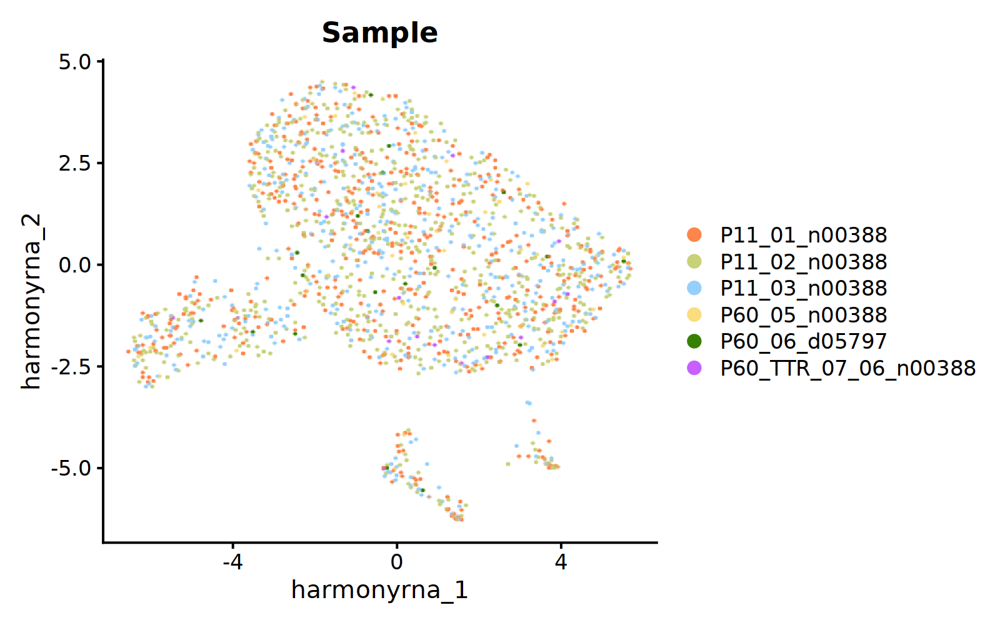

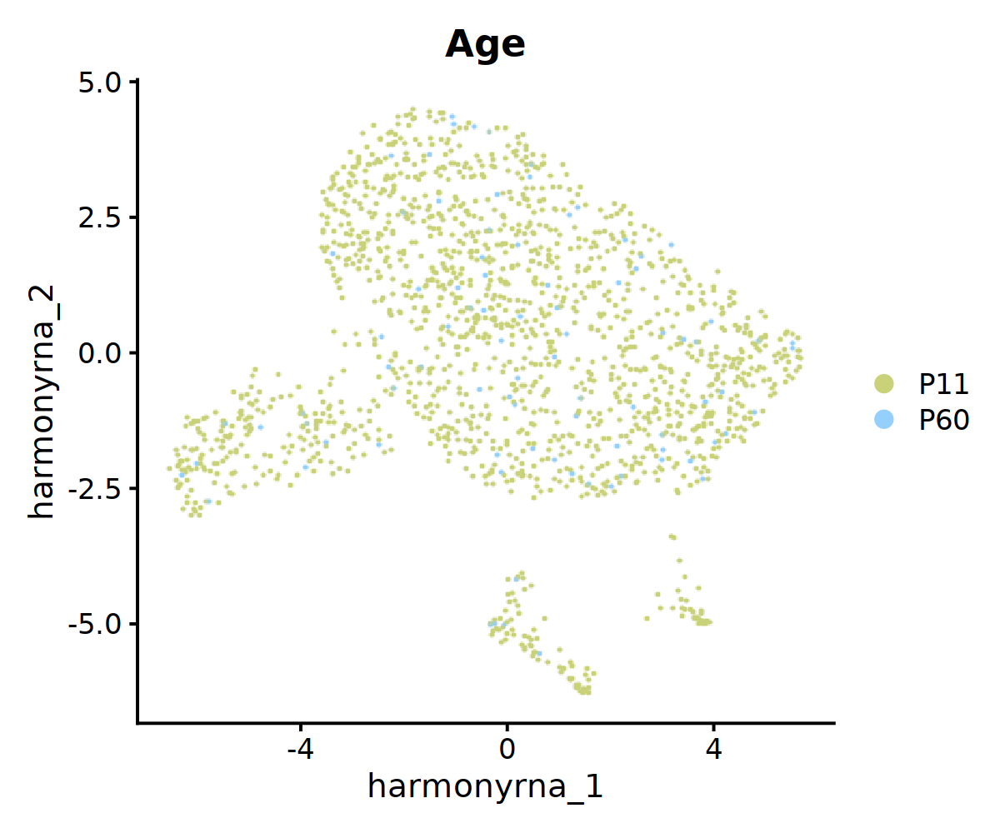

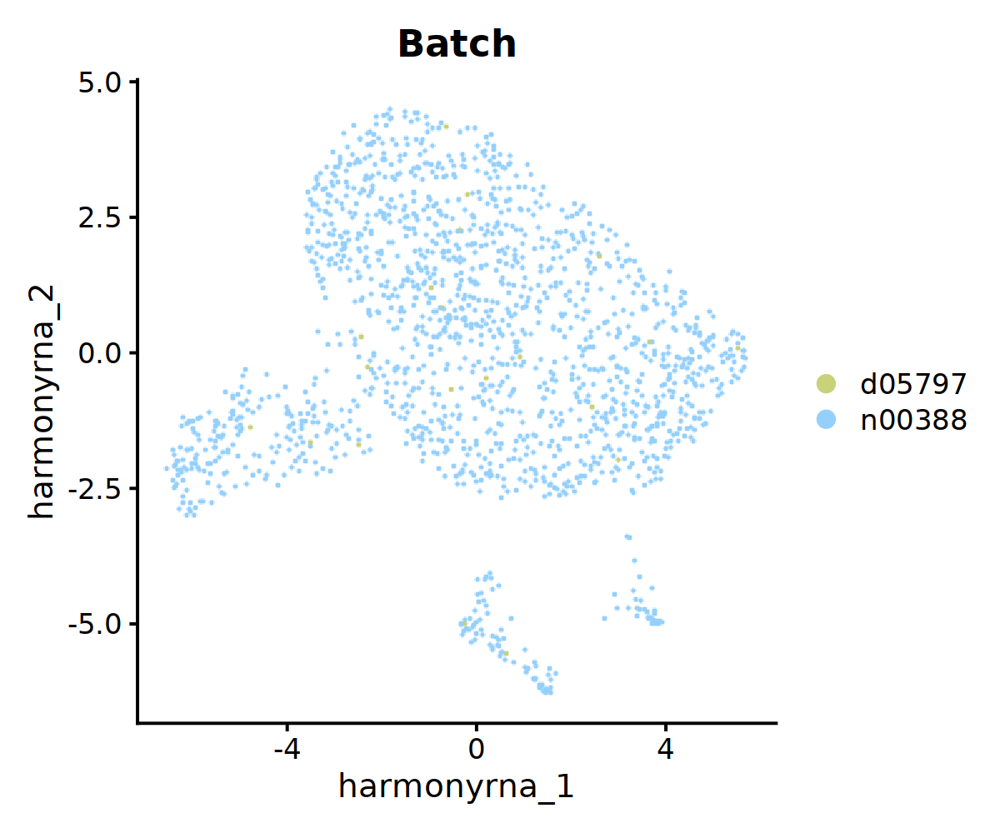

In [ ]:
options(repr.plot.width = 8, repr.plot.height = 5, repr.plot.res = 200)
after_umap_s <- DimPlot(integrated_noDBL, reduction = 'harmony_RNA', group.by = 'Sample', pt.size = 2.5, raster = TRUE, cols = my_c)

after_umap_s

ggsave(file="Harmony_RNA_noDBL_sample_UMAP.svg", plot=after_umap_s, width=8, height=4)


options(repr.plot.width = 6, repr.plot.height = 5, repr.plot.res = 200)
after_umap_a <- DimPlot(integrated_noDBL, reduction = 'harmony_RNA', group.by = 'Age', pt.size = 2.5, raster = TRUE, cols = my_c[2:3])

after_umap_a

ggsave(file="Harmony_RNA_noDBL_Age_UMAP.svg", plot=after_umap_a, width=6, height=4)

options(repr.plot.width = 6, repr.plot.height = 5, repr.plot.res = 200)
after_umap_b <- DimPlot(integrated_noDBL, reduction = 'harmony_RNA', group.by = 'Batch', pt.size = 2.5, raster = TRUE, cols = my_c[2:3])

after_umap_b

ggsave(file="Harmony_RNA_noDBL_Batch_UMAP.svg", plot=after_umap_b, width=6, height=4)


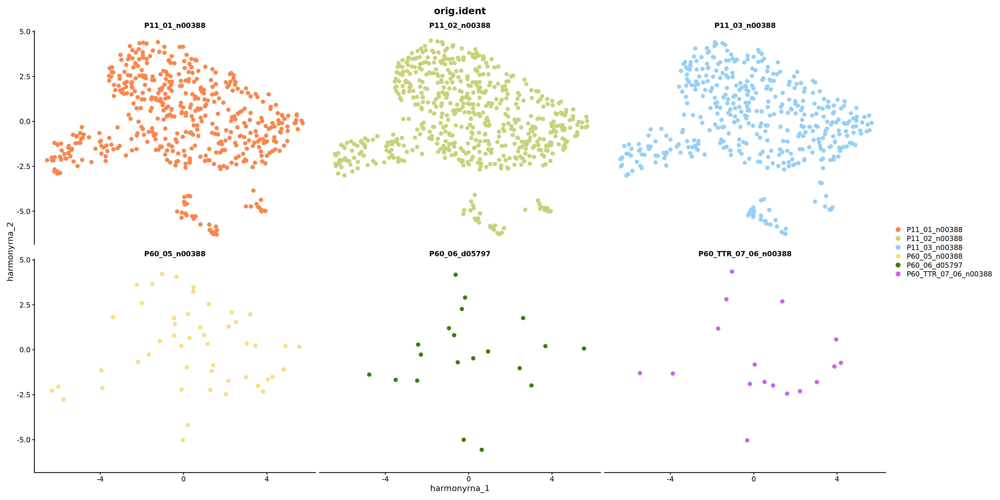

In [ ]:
options(repr.plot.width=24, repr.plot.height=12)
dpl <- DimPlot(integrated_noDBL, group.by="orig.ident", split.by="orig.ident", reduction="harmony_RNA", shuffle=TRUE, cols=my_c, ncol=3, pt.size=2.5, label=FALSE)

dpl

ggsave(file="Harmony_each_sample_noDBL_UMAP.svg", plot=dpl, width=24, height=12)

Warning message:
“All cells have the same value (4) of “Ttr””
Warning message:
“All cells have the same value (0) of “Shisa8””
Warning message:
“All cells have the same value (0) of “Sox10””
Warning message:
“All cells have the same value (0) of “Mog””
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the 

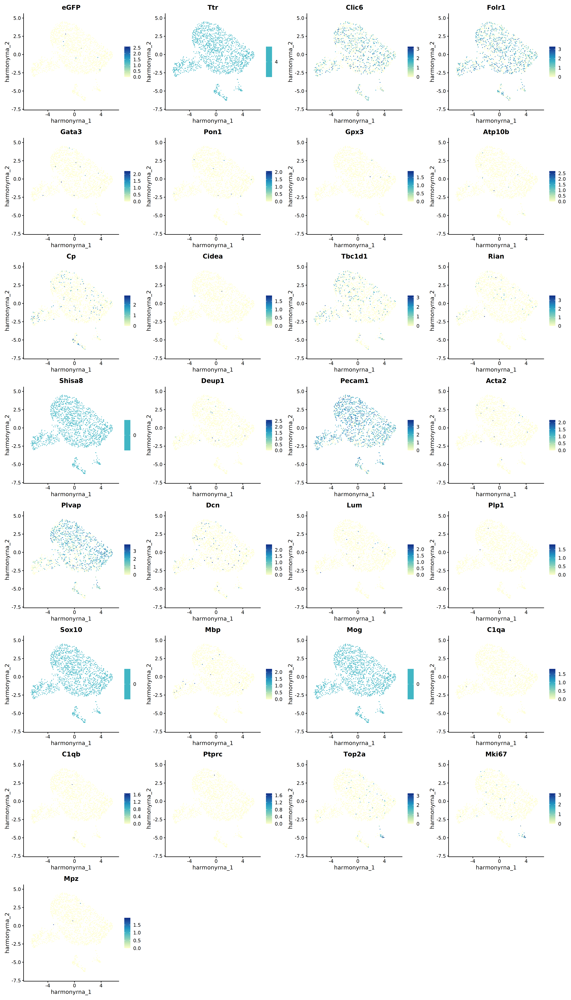

In [ ]:
options(repr.plot.width = 20, repr.plot.height = 35, repr.plot.res = 200)
ftp <- FeaturePlot(integrated_noDBL, reduction = 'harmony_RNA', features = c('eGFP', 'Ttr', 'Clic6', 'Folr1', 'Gata3', 'Pon1', 'Gpx3', 'Atp10b', 'Cp', 'Cidea', 'Tbc1d1', 'Rian', 'Shisa8', 'Deup1', 'Pecam1', 'Acta2', 'Plvap', 
                                                  'Dcn', 'Lum', 'Plp1', 'Sox10', 'Mbp', 'Mog', 'C1qa', 'C1qb', 'Ptprc', 'Top2a', 'Mki67', 'Mpz'), 
             min.cutoff = 0, max.cutoff = 4, label.size = 2, ncol = 4, pt.size = 2.5, raster=TRUE) & scale_color_distiller(palette = "YlGnBu", direction = 1)
ftp 


ggsave(file="Harmony_noDBL_geneExpression.svg", plot=ftp, width=20, height=35)

### Clustering

In [56]:
integrated_noDBL

An object of class Seurat 
215510 features across 1612 samples within 2 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: peaks
 4 dimensional reductions calculated: pca, umap_RNA, harmonyRNA, harmony_RNA

In [57]:
DefaultAssay(integrated_noDBL) <- 'RNA'

In [58]:
integrated_noDBL <- integrated_noDBL %>% FindNeighbors(reduction = 'harmonyRNA', dims = 1:14) %>%
                                FindClusters(resolution = c(0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1))

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 1612
Number of edges: 60127

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9164
Number of communities: 4
Elapsed time: 0 seconds
Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 1612
Number of edges: 60127

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8522
Number of communities: 5
Elapsed time: 0 seconds
Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 1612
Number of edges: 60127

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8133
Number of communities: 5
Elapsed time: 0 seconds
Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 1612
Number of edges: 60127

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7764
Number of communities: 5
Elapsed time: 0 seconds
Modularity Optimizer ver

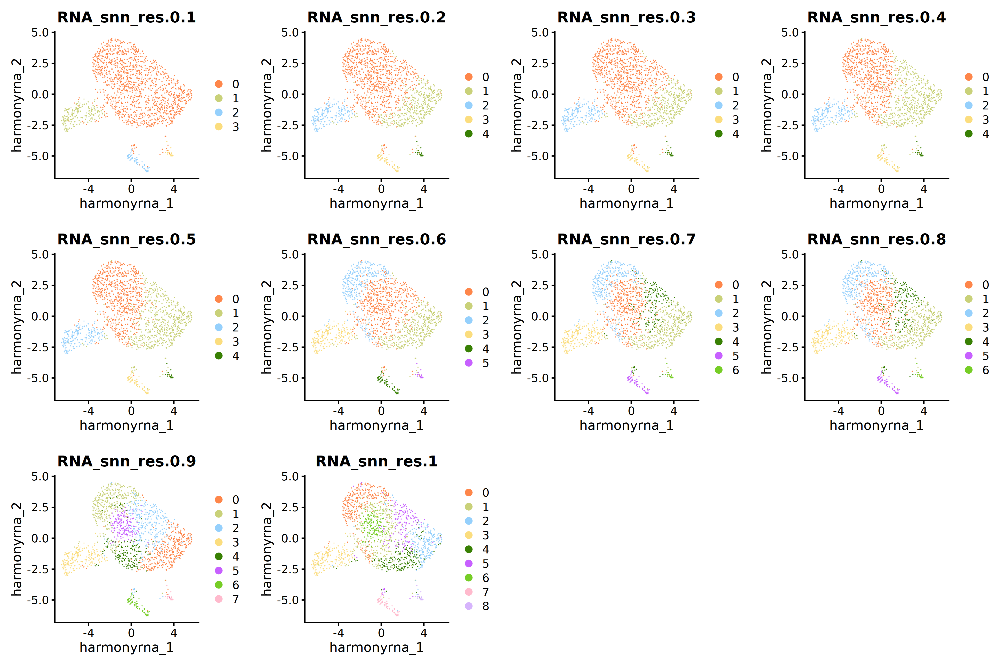

In [ ]:
options(repr.plot.width = 15, repr.plot.height = 10, repr.plot.res = 300)
grid <- plot_grid(DimPlot(integrated_noDBL, reduction = "harmony_RNA", pt.size=2.5, group.by = 'RNA_snn_res.0.1', cols = my_c, raster = TRUE), 
                  DimPlot(integrated_noDBL, reduction = "harmony_RNA", pt.size=2.5, group.by = 'RNA_snn_res.0.2', cols = my_c, raster = TRUE),
                  DimPlot(integrated_noDBL, reduction = "harmony_RNA", pt.size=2.5, group.by = 'RNA_snn_res.0.3', cols = my_c, raster = TRUE),
                  DimPlot(integrated_noDBL, reduction = "harmony_RNA", pt.size=2.5, group.by = 'RNA_snn_res.0.4', cols = my_c, raster = TRUE),
                  DimPlot(integrated_noDBL, reduction = "harmony_RNA", pt.size=2.5, group.by = 'RNA_snn_res.0.5', cols = my_c, raster = TRUE),
                  DimPlot(integrated_noDBL, reduction = "harmony_RNA", pt.size=2.5, group.by = 'RNA_snn_res.0.6', cols = my_c, raster = TRUE),
                  DimPlot(integrated_noDBL, reduction = "harmony_RNA", pt.size=2.5, group.by = 'RNA_snn_res.0.7', cols = my_c, raster = TRUE),
                  DimPlot(integrated_noDBL, reduction = "harmony_RNA", pt.size=2.5, group.by = 'RNA_snn_res.0.8', cols = my_c, raster = TRUE),
                  DimPlot(integrated_noDBL, reduction = "harmony_RNA", pt.size=2.5, group.by = 'RNA_snn_res.0.9', cols = my_c, raster = TRUE),
                  DimPlot(integrated_noDBL, reduction = "harmony_RNA", pt.size=2.5, group.by = 'RNA_snn_res.1', cols = my_c, raster = TRUE))
grid

ggsave(file="Endothelial_integrated_noDBL_clusters_all.svg", plot=grid, width=15, height=30)

In [118]:
integrated_noDBL <- SetIdent(integrated_noDBL, value = 'RNA_snn_res.0.9')

In [119]:
integrated_noDBL_predicted.markers <- FindAllMarkers(integrated_noDBL, test.use="wilcox", only.pos=TRUE, max.cells.per.ident=15)

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6

Calculating cluster 7



In [121]:
integrated_noDBL_predicted.markers %>% group_by(cluster) %>%
                                slice_head(n = 10) %>%
                                ungroup() -> top10_predicted

In [122]:
top10_predicted <- top10_predicted[!duplicated(top10_predicted$gene), ]

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


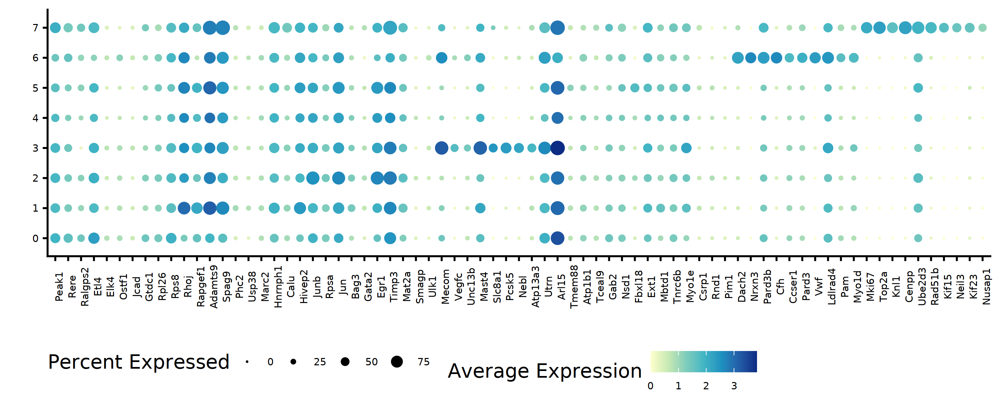

In [ ]:
options(repr.plot.width = 10, repr.plot.height = 4, repr.plot.res = 300)
dtp <- DotPlot(integrated_noDBL, features = top10_predicted$gene, col.min = 0, col.max = 4, dot.scale = 4, scale=FALSE) + theme(axis.text.x=element_text(size=7, angle = 90),axis.text.y=element_text(size=7), 
                                                                                                 legend.position = 'bottom', legend.direction = 'horizontal', 
                                                                                                  legend.text = element_text(size=7)) + xlab('') + ylab('') & scale_color_distiller(palette = "YlGnBu", direction = 1)

dtp

In [ ]:
saveRDS(integrated_noDBL, 'Endothelial_integrated_noDBL_multiome_clusters.rds')

# ATAC

In [74]:
DefaultAssay(integrated_noDBL) <- "peaks"

In [75]:
integrated_noDBL <- FindTopFeatures(integrated_noDBL, assay = "peaks", min.cutoff = 10)

In [76]:
integrated_noDBL <- RunTFIDF(integrated_noDBL, assay="peaks")

Performing TF-IDF normalization

Warning message in RunTFIDF.default(object = GetAssayData(object = object, layer = "counts"), :
“Some features contain 0 total counts”


In [77]:
integrated_noDBL <- RunSVD(integrated_noDBL, assay="peaks")

Running SVD

Scaling cell embeddings



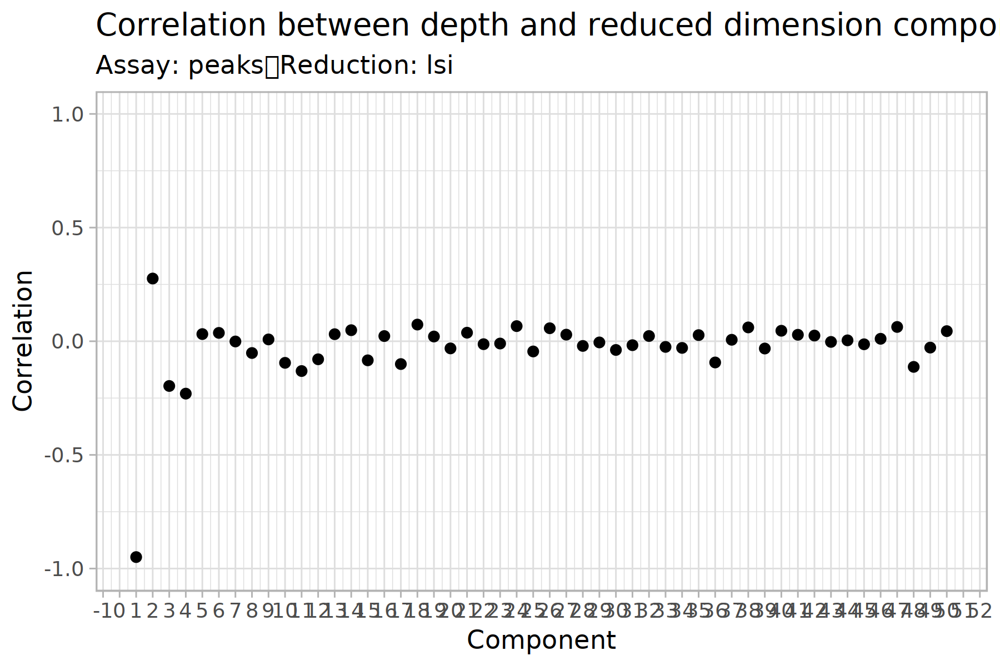

In [ ]:
options(repr.plot.width=6, repr.plot.height=4)
dpc <- DepthCor(integrated_noDBL, n=50)

dpc

ggsave(file="Merged_noDBL_depthCorr.svg", plot=dpc, width=6, height=4)

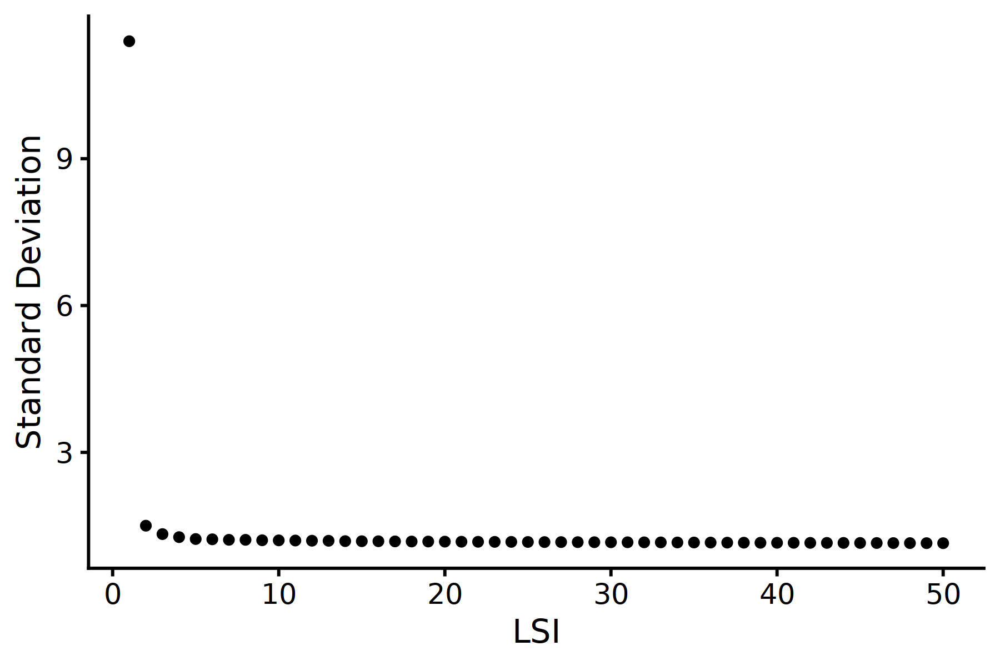

In [ ]:
options(repr.plot.width=6, repr.plot.height=4)
ebl <- ElbowPlot(integrated_noDBL, reduction = "lsi", n=50)

ebl

ggsave(file="Merged_noDBL_depthCorr_ebl.svg", plot=ebl, width=6, height=4)

In [86]:
integrated_noDBL <- FindNeighbors(integrated_noDBL, reduction = 'lsi', dims = 2:18, graph.name="snn_peaks")

Computing nearest neighbor graph

Computing SNN

Only one graph name supplied, storing nearest-neighbor graph only



In [87]:
integrated_noDBL <- RunUMAP(integrated_noDBL, dims = 2:18, reduction = 'lsi', reduction.name="umap_peaks")

13:19:36 UMAP embedding parameters a = 0.9922 b = 1.112

13:19:37 Read 1612 rows and found 17 numeric columns

13:19:37 Using Annoy for neighbor search, n_neighbors = 30

13:19:37 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

13:19:37 Writing NN index file to temp file /tmp/RtmpOsNryv/file135544becd13f

13:19:37 Searching Annoy index using 1 thread, search_k = 3000

13:19:37 Annoy recall = 100%

13:19:38 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

13:19:41 Initializing from normalized Laplacian + noise (using RSpectra)

13:19:41 Commencing optimization for 500 epochs, with 57742 positive edges

13:19:43 Optimization finished



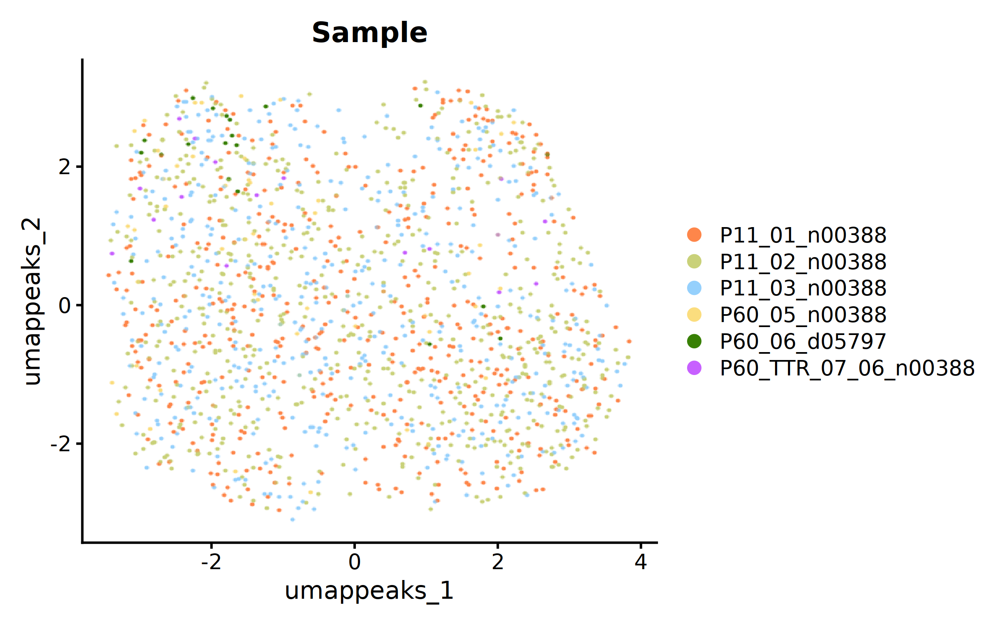

In [ ]:
options(repr.plot.width=8, repr.plot.height=5)
dpl <- DimPlot(integrated_noDBL, group.by="Sample", reduction="umap_peaks", pt.size = 2.5, raster = TRUE, cols = my_c, label=FALSE)

dpl 

ggsave(file="Merged_peaks_noDBL_Sample_UMAP.svg", plot=dpl, width=8, height=5)

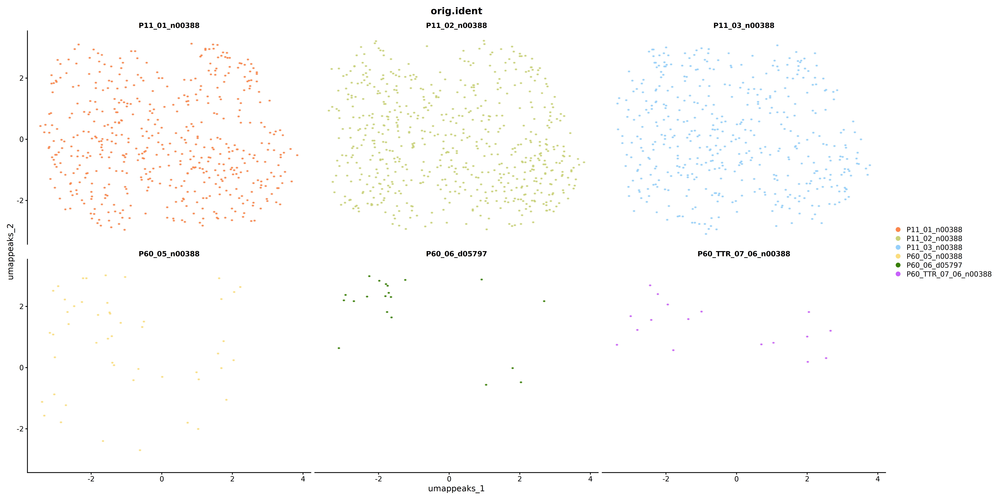

In [ ]:
options(repr.plot.width=24, repr.plot.height=12)
dpl <- DimPlot(integrated_noDBL, group.by="orig.ident", split.by="orig.ident", reduction="umap_peaks", shuffle=TRUE, cols=my_c, ncol=3, pt.size=2.5, raster = TRUE, label=FALSE)

dpl

ggsave(file="Merged_peaks_noDBL_each_sample_UMAP.svg", plot=dpl, width=8, height=4)

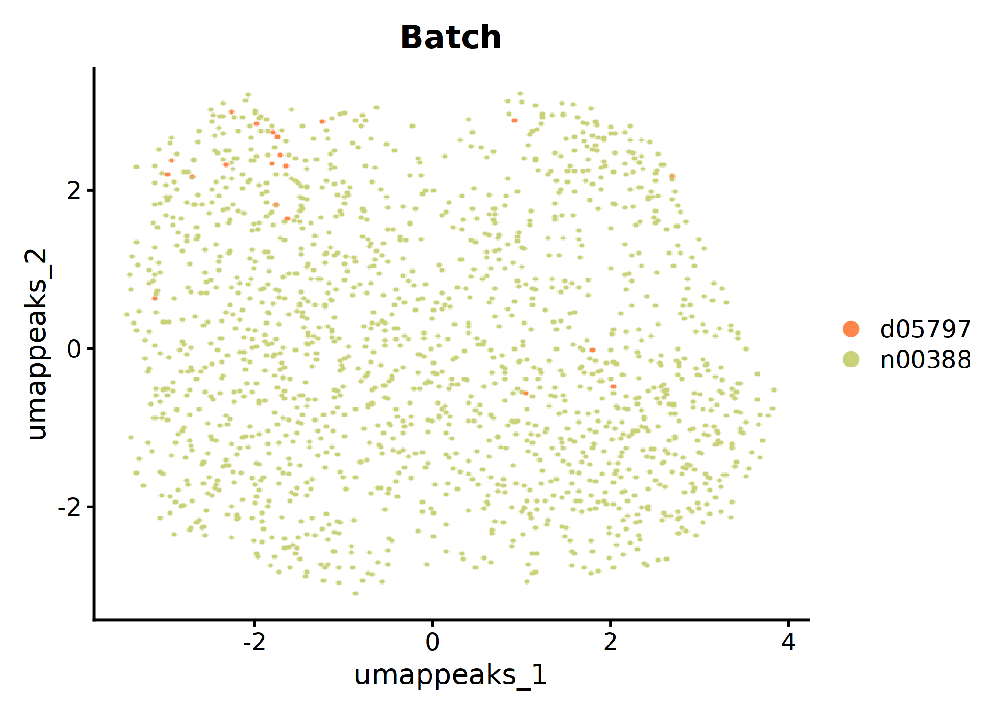

In [ ]:
options(repr.plot.width=7, repr.plot.height=5)
dpl <- DimPlot(integrated_noDBL, group.by="Batch", reduction="umap_peaks", pt.size = 2.5, raster = TRUE, cols = my_c, label=FALSE)

dpl

ggsave(file="Merged_peaks_noDBL_Batch_UMAP.svg", plot=dpl, width=7, height=5)

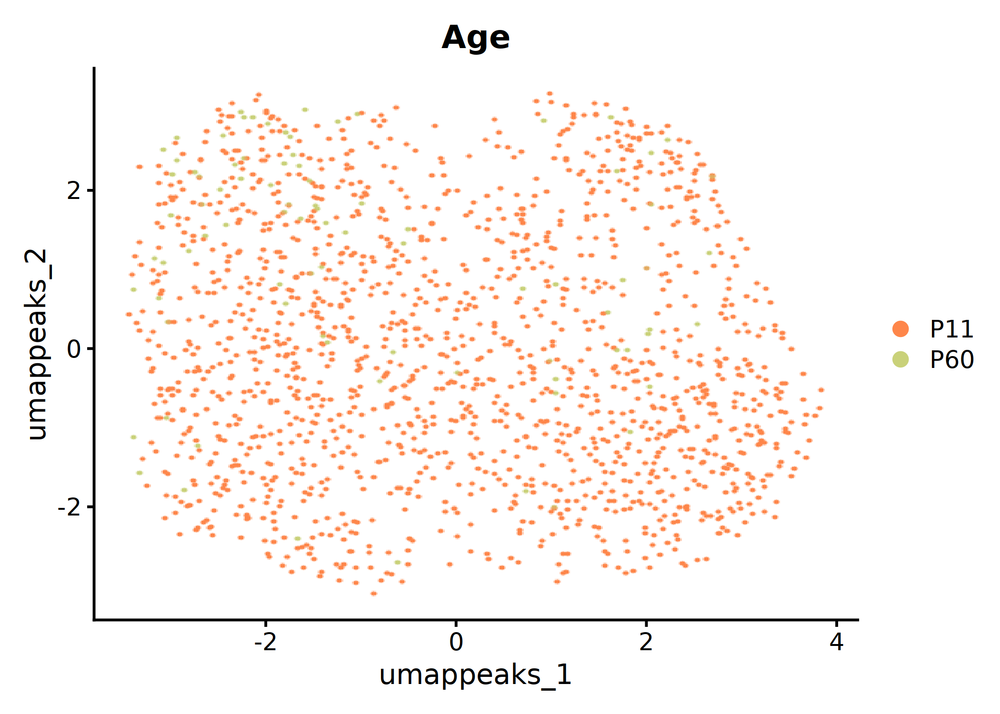

In [ ]:
options(repr.plot.width=7, repr.plot.height=5)
dpl <- DimPlot(integrated_noDBL, group.by="Age", reduction="umap_peaks", pt.size = 2.5, raster = TRUE, cols = my_c, label=FALSE)

dpl

ggsave(file="Merged_peaks_noDBL_Age_UMAP.svg", plot=dpl, width=7, height=5)

### Integration with Harmony

In [93]:
integrated_noDBL <- RunHarmony(integrated_noDBL, group.by.vars = 'Sample', reduction = 'lsi', assay.use = 'peaks', reduction.save = 'harmonyPeaks', project.dim = FALSE)

Transposing data matrix

Initializing state using k-means centroids initialization

Harmony 1/10

Harmony 2/10

Harmony 3/10

Harmony 4/10

Harmony 5/10

Harmony 6/10

Harmony 7/10

Harmony 8/10

Harmony converged after 8 iterations



In [94]:
# re-compute the UMAP using corrected LSI embeddings
integrated_noDBL <- RunUMAP(integrated_noDBL, dims = 2:18, reduction = 'harmonyPeaks', reduction.name = 'harmony_Peaks')

13:20:15 UMAP embedding parameters a = 0.9922 b = 1.112

13:20:15 Read 1612 rows and found 17 numeric columns

13:20:15 Using Annoy for neighbor search, n_neighbors = 30

13:20:15 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

13:20:15 Writing NN index file to temp file /tmp/RtmpOsNryv/file13554509d5f53

13:20:15 Searching Annoy index using 1 thread, search_k = 3000

13:20:15 Annoy recall = 100%

13:20:17 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

13:20:19 Initializing from normalized Laplacian + noise (using RSpectra)

13:20:19 Commencing optimization for 500 epochs, with 59760 positive edges

13:20:21 Optimization finished

Warning message:
“Key ‘harmonyPeaks_’ taken, using ‘harmonypeaks_’ instead”


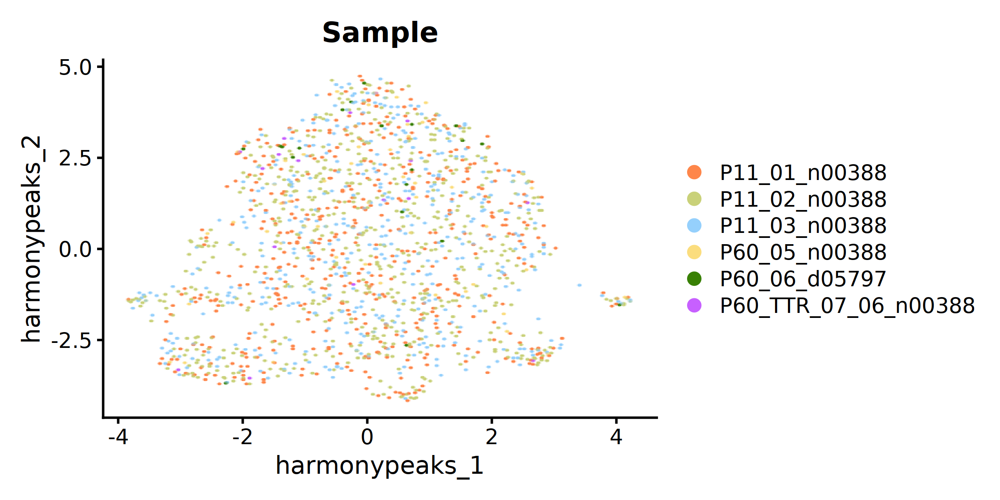

In [ ]:
options(repr.plot.width=8, repr.plot.height=4)
dpl <- DimPlot(integrated_noDBL, group.by = 'Sample', pt.size = 2.5, raster=TRUE, cols=my_c, reduction = 'harmony_Peaks')

dpl

ggsave(file="Endothelial_integrated_noDBL_peaks_noDBL_Sample_UMAP.svg", plot=dpl, width=8, height=4)

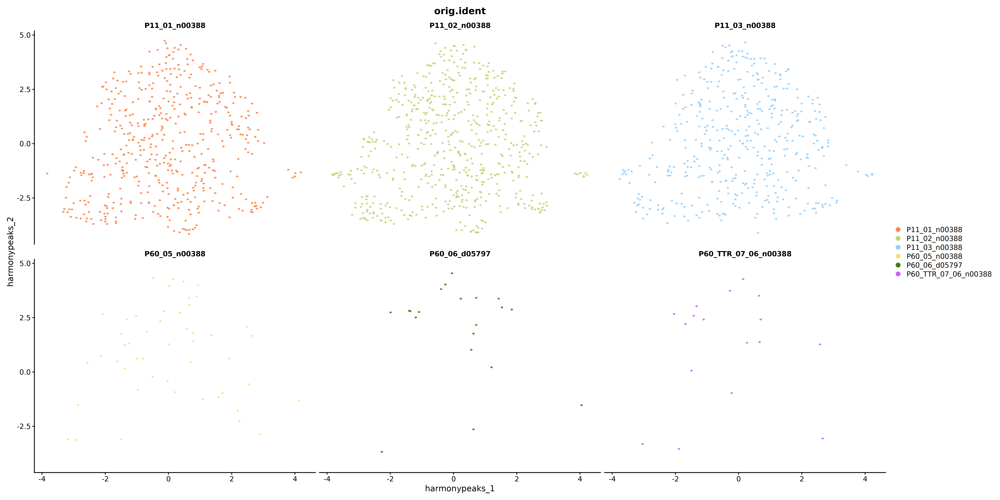

In [ ]:
options(repr.plot.width=24, repr.plot.height=12)
dpl <- DimPlot(integrated_noDBL, group.by="orig.ident", split.by="orig.ident", reduction="harmony_Peaks", shuffle=TRUE, cols=my_c, ncol=3, pt.size=2.5, raster = TRUE, label=FALSE)

dpl

ggsave(file="Endothelial_integrated_noDBL_peaks_noDBL_each_Sample_UMAP.svg", plot=dpl, width=24, height=12)

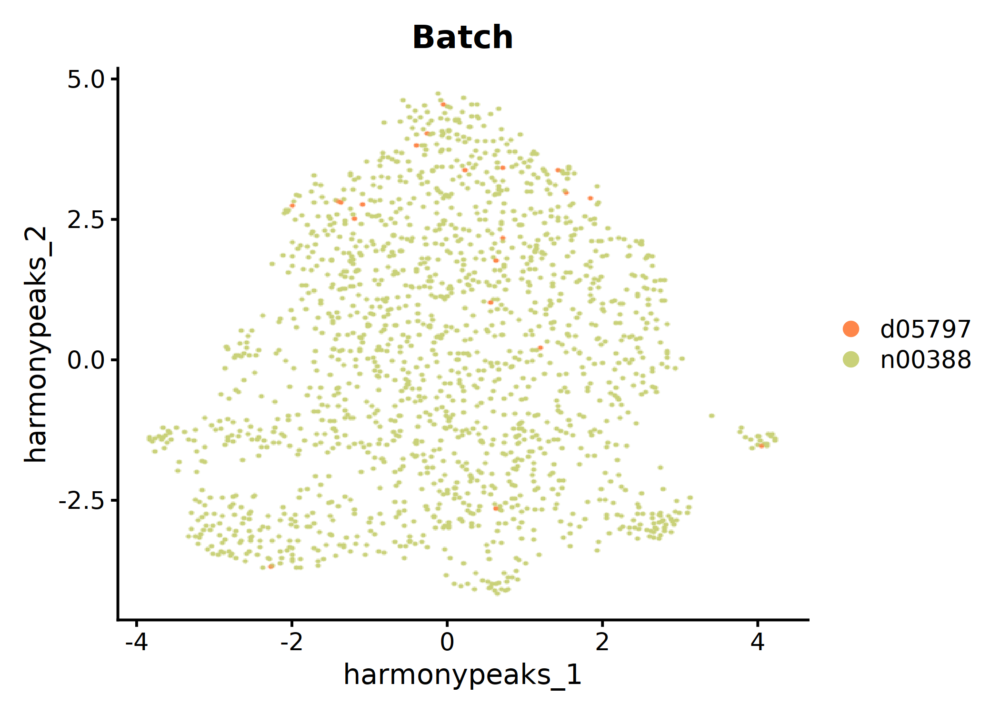

In [ ]:
options(repr.plot.width=7, repr.plot.height=5)
dpl <- DimPlot(integrated_noDBL, group.by="Batch", reduction="harmony_Peaks", pt.size = 2.5, raster = TRUE, cols = my_c, label=FALSE)

dpl

ggsave(file="Endothelial_integrated_noDBL_Peaks_noDBL_Batch_UMAP.svg", plot=dpl, width=7, height=5)

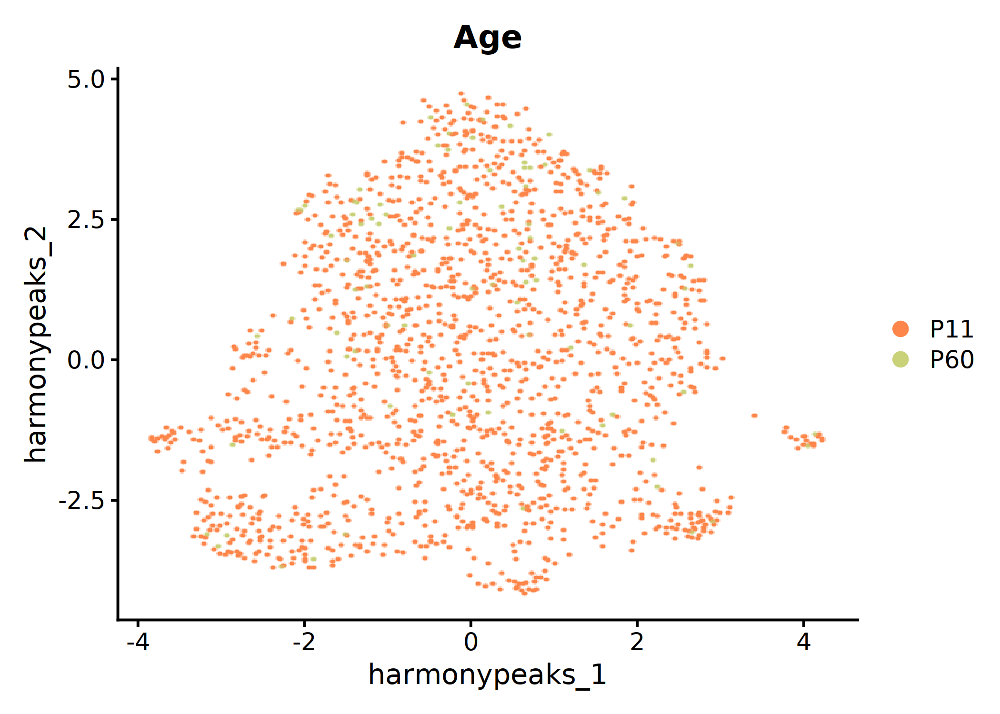

In [ ]:
options(repr.plot.width=7, repr.plot.height=5)
dpl <- DimPlot(integrated_noDBL, group.by="Age", reduction="harmony_Peaks", pt.size = 2.5, raster = TRUE, cols = my_c, label=FALSE)

dpl

ggsave(file="Endothelial_integrated_noDBL_Peaks_noDBL_Age_UMAP.svg", plot=dpl, width=7, height=5)

### Clustering

In [101]:
DefaultAssay(integrated_noDBL) <- 'peaks'

In [102]:
integrated_noDBL

An object of class Seurat 
215510 features across 1612 samples within 2 assays 
Active assay: peaks (183223 features, 29823 variable features)
 2 layers present: counts, data
 1 other assay present: RNA
 8 dimensional reductions calculated: pca, umap_RNA, harmonyRNA, harmony_RNA, lsi, umap_peaks, harmonyPeaks, harmony_Peaks

In [103]:
integrated_noDBL <- integrated_noDBL %>% FindNeighbors(reduction = 'harmonyPeaks', dims = 2:15) %>%
                                FindClusters(resolution = c(0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1))

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 1612
Number of edges: 65399

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9027
Number of communities: 2
Elapsed time: 0 seconds
Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 1612
Number of edges: 65399

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8269
Number of communities: 3
Elapsed time: 0 seconds
Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 1612
Number of edges: 65399

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7706
Number of communities: 4
Elapsed time: 0 seconds
Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 1612
Number of edges: 65399

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7367
Number of communities: 5
Elapsed time: 0 seconds
Modularity Optimizer ver

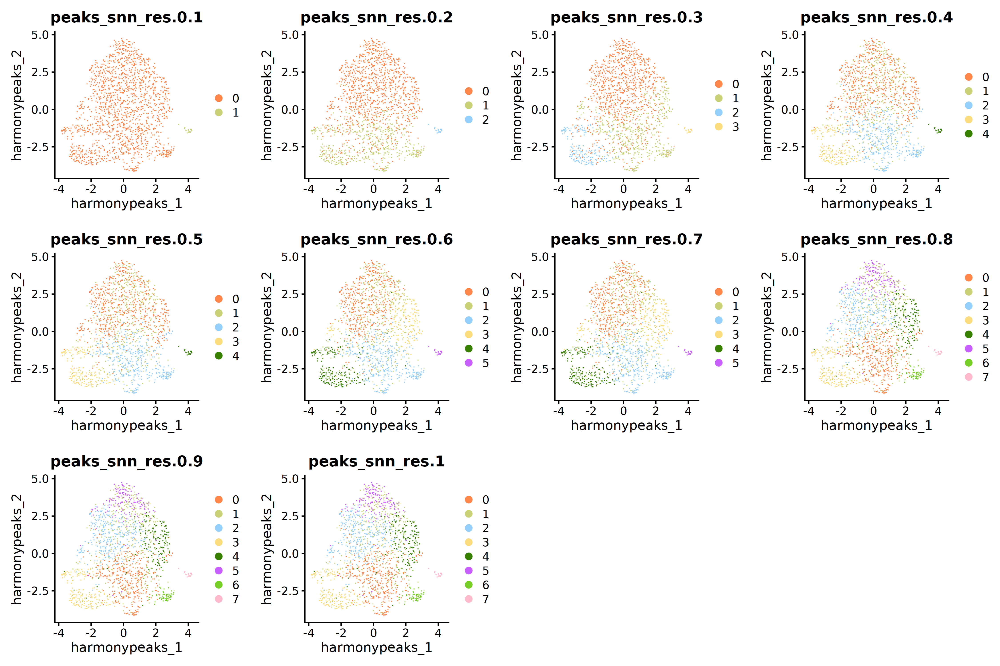

In [ ]:
options(repr.plot.width = 15, repr.plot.height = 10, repr.plot.res = 300)
grid <- plot_grid(DimPlot(integrated_noDBL, reduction = "harmony_Peaks", pt.size=2.5, group.by = 'peaks_snn_res.0.1', cols = my_c, raster = TRUE), 
                  DimPlot(integrated_noDBL, reduction = "harmony_Peaks", pt.size=2.5, group.by = 'peaks_snn_res.0.2', cols = my_c, raster = TRUE),
                  DimPlot(integrated_noDBL, reduction = "harmony_Peaks", pt.size=2.5, group.by = 'peaks_snn_res.0.3', cols = my_c, raster = TRUE),
                  DimPlot(integrated_noDBL, reduction = "harmony_Peaks", pt.size=2.5, group.by = 'peaks_snn_res.0.4', cols = my_c, raster = TRUE),
                  DimPlot(integrated_noDBL, reduction = "harmony_Peaks", pt.size=2.5, group.by = 'peaks_snn_res.0.5', cols = my_c, raster = TRUE),
                  DimPlot(integrated_noDBL, reduction = "harmony_Peaks", pt.size=2.5, group.by = 'peaks_snn_res.0.6', cols = my_c, raster = TRUE),
                  DimPlot(integrated_noDBL, reduction = "harmony_Peaks", pt.size=2.5, group.by = 'peaks_snn_res.0.7', cols = my_c, raster = TRUE),
                  DimPlot(integrated_noDBL, reduction = "harmony_Peaks", pt.size=2.5, group.by = 'peaks_snn_res.0.8', cols = my_c, raster = TRUE),
                  DimPlot(integrated_noDBL, reduction = "harmony_Peaks", pt.size=2.5, group.by = 'peaks_snn_res.0.9', cols = my_c, raster = TRUE),
                  DimPlot(integrated_noDBL, reduction = "harmony_Peaks", pt.size=2.5, group.by = 'peaks_snn_res.1', cols = my_c, raster = TRUE))
grid

ggsave(file="Endothelial_integrated_noDBL_Peaks_noDBL_clusters_all.svg", plot=grid, width=15, height=30)

In [ ]:
saveRDS(integrated_noDBL, 'Endothelial_integrated_noDBL_multiome_clusters.rds')

# Cell type annotation

In [ ]:
integrated_noDBL <- readRDS('Endothelial_integrated_noDBL_multiome_clusters.rds')

In [14]:
DefaultAssay(integrated_noDBL) <- 'RNA'

In [124]:
integrated_noDBL <- SetIdent(integrated_noDBL, value = 'RNA_snn_res.0.1')

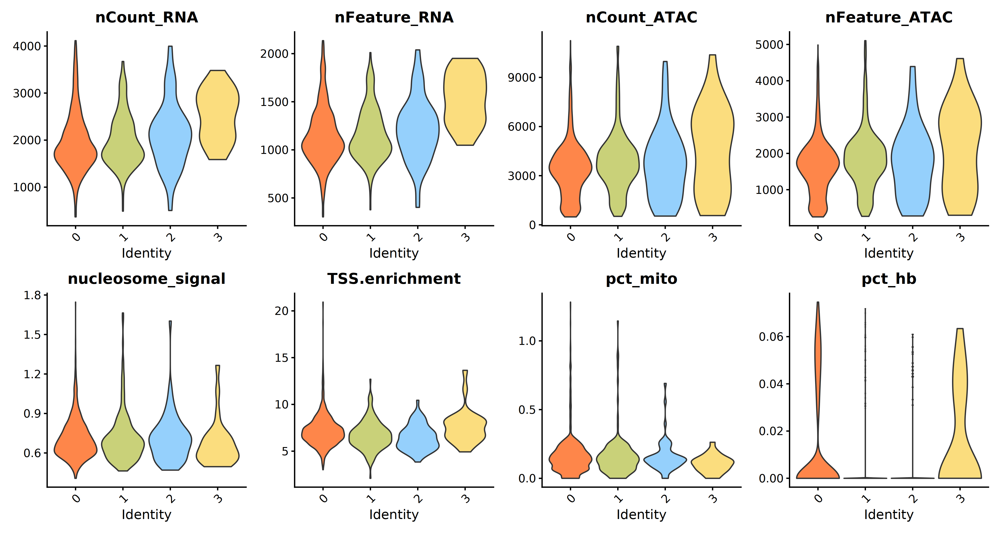

In [ ]:
options(repr.plot.width = 15, repr.plot.height = 8, repr.plot.res = 300)

vln <- VlnPlot(integrated_noDBL, features=c('nCount_RNA', 'nFeature_RNA', 'nCount_peaks', 'nFeature_peaks', 'nucleosome_signal', 'TSS.enrichment', 'pct_mito', 'pct_hb'), 
        ncol=4, pt.size=0, col = my_c) 

vln

In [126]:
marker_genes <- c('Folr1', 'Clic6', 'Krt18', 'Dcn', 'Itga8', 'Col3a1', 'Flt1', 'Plvap', 'Pecam1', 'Cd86', 'Tank', 
                  'Cd83', 'Dscam', 'Ptprz1', 'Gria2')

Warning message in SingleExIPlot(type = type, data = data[, x, drop = FALSE], idents = idents, :
“All cells have the same value of Dscam.”


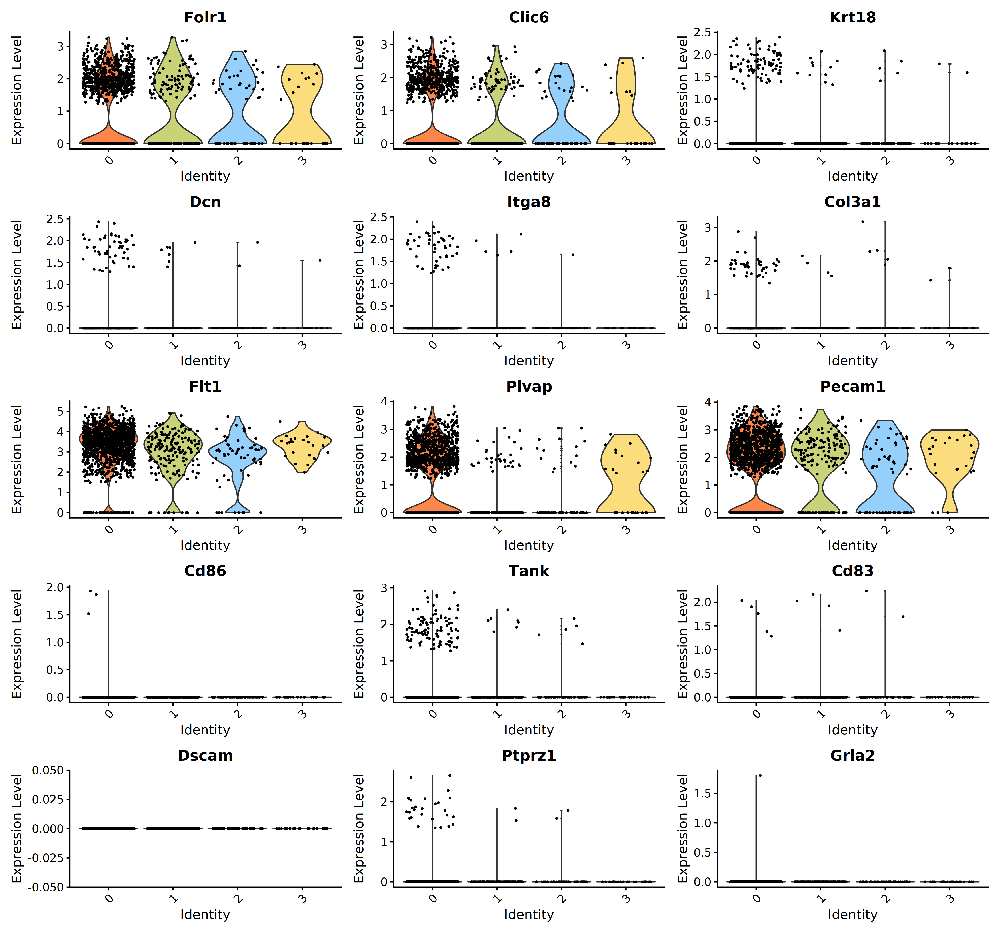

In [ ]:
options(repr.plot.width = 15, repr.plot.height = 14, repr.plot.res = 300)
vln <- VlnPlot(object = integrated_noDBL, features = marker_genes, pt.size=0.5, cols = my_c, ncol = 3)

vln

ggsave(file="Endothelial_integrated_noDBL_vln_Cell_type.svg", plot=vln, width=10, height=25)

In [128]:
endo_noDBL_markers <- c('Plvap', 'Cd300lg', 'Esm1', 'Jam3', 'Top2a', 'Mki67', 'Birc5', 'Pclaf', 'Pcsk5', 'Nebl', 'Gja4', 
                  'Fbln5', 'Vwf', 'Pcdh7', 'Lbp', 'Nr2f2')

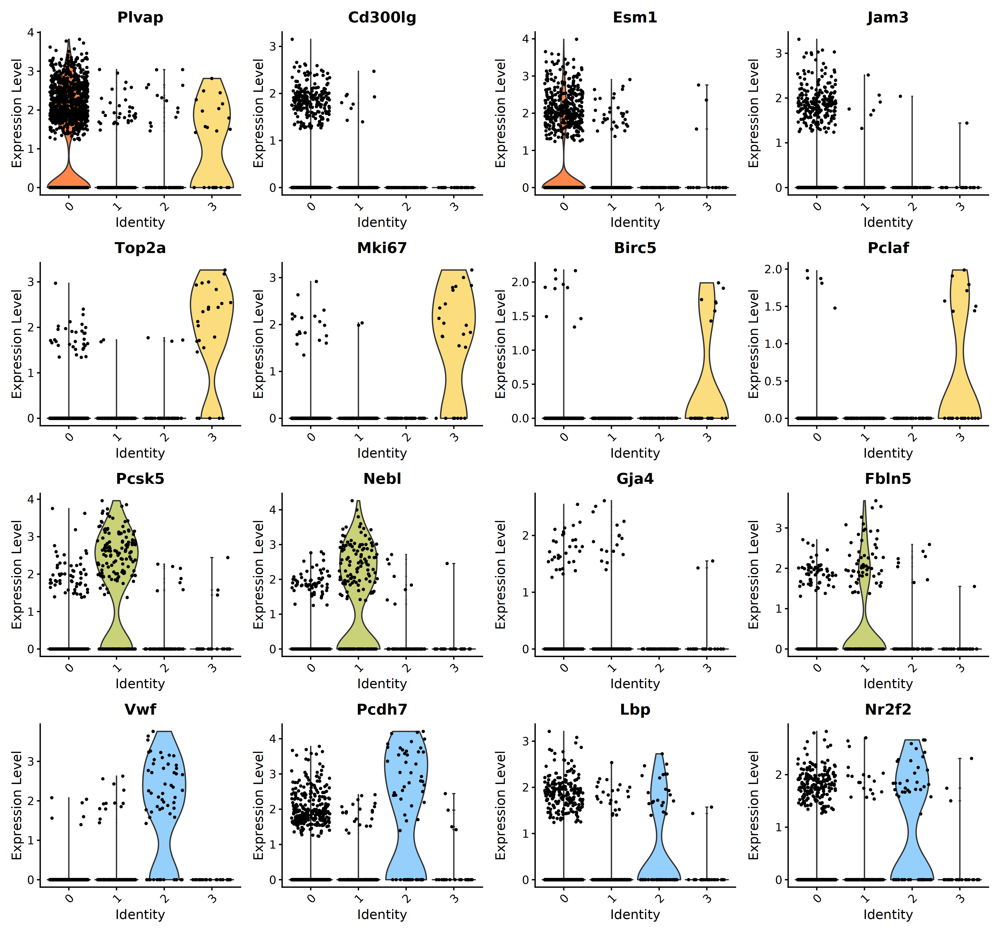

In [ ]:
options(repr.plot.width = 15, repr.plot.height = 14, repr.plot.res = 300)
vln <- VlnPlot(object = integrated_noDBL, features = endo_noDBL_markers, pt.size=0.8, cols = my_c, ncol = 4)

vln


In [ ]:
endo_noDBL_markers_1 <- c('Mgp', 'Cytl1', 'Fbln5', 'Clu', 'Eln', 'Bgn', 'Igfbp4', 'Cfh', 'Lmcd1', 'Bpgm','Cmip',
                            '8430408G22Rik', 'S100a6', 'Azin1', 'Pi16', 'Cd9', 'Gadd45g', 'Timp3', 'Stmn2', 'Nr4a1','Apold1', 'Hbegf',
                            'Gkn3', 'Egfl8', 'Vegfc', 'Hrct1', 'Cdkn1c', 'Eps8l2', 'Alpl', 'Hey1', 'Edn3', 'Mgst1', 'Eogt',
                            'Glul', 'Rad54b', 'Tuba1a', 'Tgfb2', 'Slc26a10', 'Stmn1', 'Akap12', 'Klf6', 'Dusp1', 'Zfp771', 'Actb',
                            'Cxcl12', 'Spock2', 'Gm9946', 'Lrrn3', 'Gstm7', 'Palm', 'Tbx3', 'Prdm16', 'Rasgrp2', 'Cd83', 'Pik3ip1',
                            'Car4', 'Gatm', 'Itm2a', 'Hmcn1', 'Slc7a1', 'Nkd1', 'Hspa1a', 'Smox', 'Slc31a1', 'Slc39a8', 'Ttyh2',
                            'Tmsb10', 'Vcam1', 'Slc38a5', 'Icam1', 'Tmem252', 'Lcn2', 'Vwf', 'Ctsc', 'Tgm2', 'Ackr1', 'Apod',
                            'Isg15', 'Ifit1', 'Pglyrp1', 'Slc7a5', 'Ifit3', 'Sparcl1', 'Slc3a2', 'Ifit3b', 'Slc38a3', 'Usp18', 'Nostrin',
                            'Plvap', 'Plpp3', 'Plpp1', 'Nrp1', 'Cd24a', 'Socs3', 'Rgcc', 'Igfbp3', 'Kdr', 'Ehd4', 'Esm1')

In [ ]:
options(repr.plot.width = 40, repr.plot.height = 40, repr.plot.res = 300)
vln <- VlnPlot(object = integrated_noDBL, features = endo_noDBL_markers_carmeliet, pt.size=0, cols = my_c, ncol = 11)

vln

#ggsave(file="Endothelial_integrated_noDBL_vln_Cell_type.svg", plot=vln, width=10, height=25)

Warning message:
“The following requested variables were not found: 8430408G22Rik”
Warning message in SingleExIPlot(type = type, data = data[, x, drop = FALSE], idents = idents, :
“All cells have the same value of Ifit3b.”


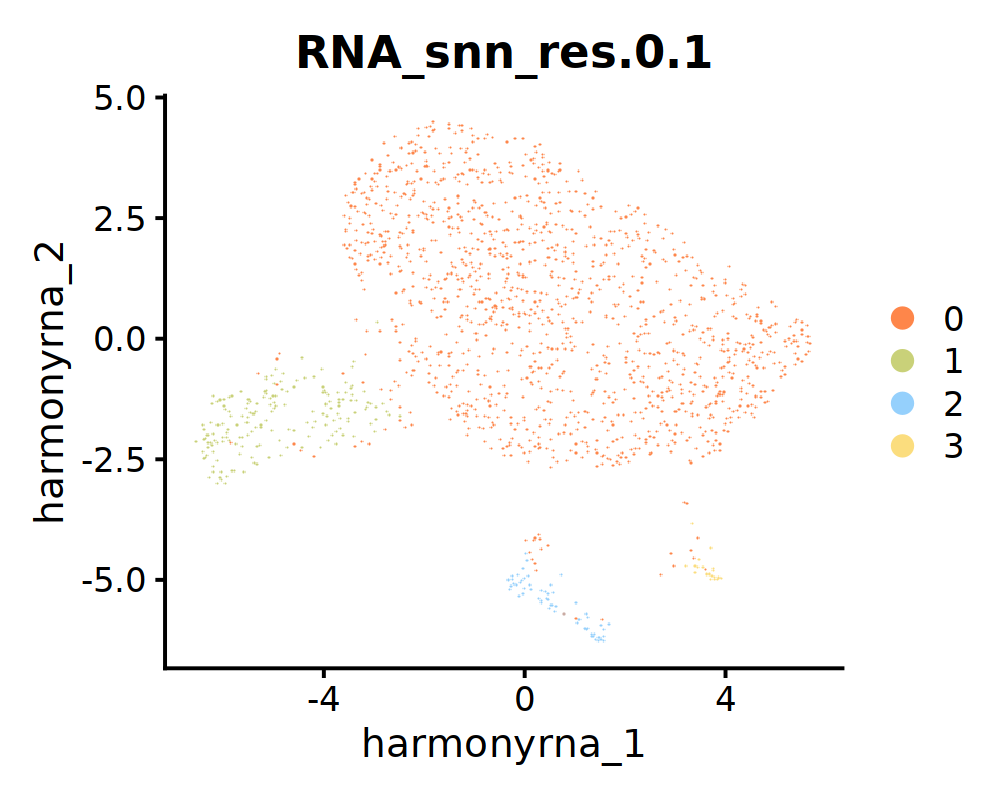

In [ ]:
options(repr.plot.width = 5, repr.plot.height = 4, repr.plot.res = 200)
dpt <- DimPlot(integrated_noDBL, group.by = "RNA_snn_res.0.1", pt.size=1.5, raster = TRUE, cols = my_c, label = FALSE, repel = TRUE, reduction = 'harmony_RNA')

dpt

ggsave(file="Endothelial_integrated_noDBL_clusters_RNA.svg", plot=dpt, width=7, height=5)

In [134]:
integrated_noDBL@meta.data$RNA_snn_res.0.1 <- as.factor(integrated_noDBL@meta.data$RNA_snn_res.0.1)

In [135]:
integrated_noDBL@meta.data$Cell_type[which(integrated_noDBL@meta.data$RNA_snn_res.0.1 == "0")] <- "Capilary" 
integrated_noDBL@meta.data$Cell_type[which(integrated_noDBL@meta.data$RNA_snn_res.0.1 == "1")] <- "Artery" 
integrated_noDBL@meta.data$Cell_type[which(integrated_noDBL@meta.data$RNA_snn_res.0.1 == "2")] <- "Vein" 
integrated_noDBL@meta.data$Cell_type[which(integrated_noDBL@meta.data$RNA_snn_res.0.1 == "3")] <- "Proliferating endothelial cells"

In [136]:
integrated_noDBL <- SetIdent(integrated_noDBL, value = 'Cell_type')

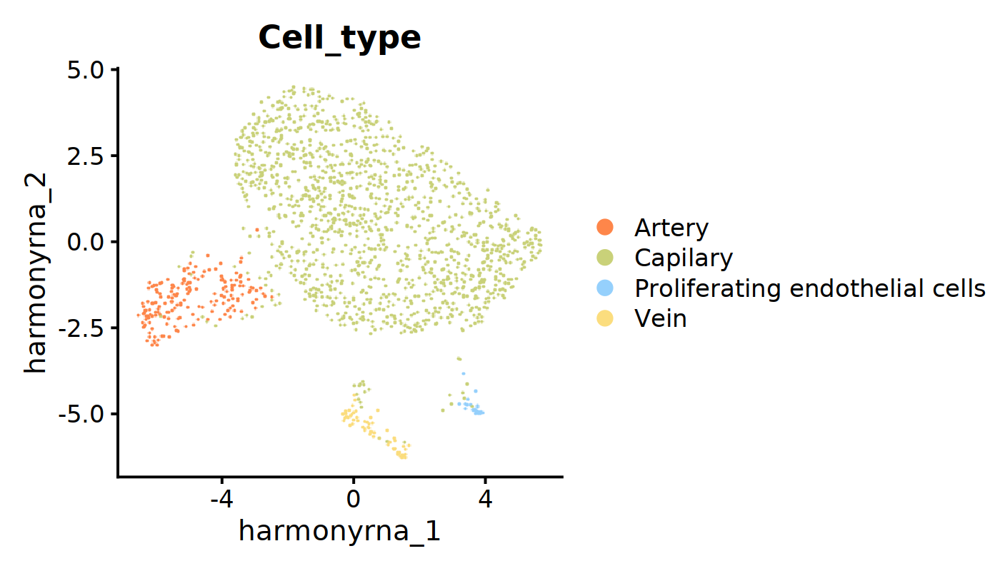

In [ ]:
options(repr.plot.width = 7, repr.plot.height = 4, repr.plot.res = 200)
dpt <- DimPlot(integrated_noDBL, group.by = "Cell_type", pt.size=2.5, raster = TRUE, cols = my_c, label = FALSE, repel = TRUE, reduction = 'harmony_RNA')

dpt

ggsave(file="Endothelial_integrated_noDBL_celltype_RNA.svg", plot=dpt, width=7, height=4)

In [139]:
integrated_noDBL_predicted.markers <- FindAllMarkers(integrated_noDBL, test.use="wilcox", only.pos=TRUE, max.cells.per.ident=15)

Calculating cluster Capilary

Calculating cluster Artery

Calculating cluster Vein

Calculating cluster Proliferating endothelial cells



In [140]:
write.csv(integrated_noDBL_predicted.markers, 'Markers_RNA_Endothelial.csv', row.names = TRUE)

In [141]:
integrated_noDBL_predicted.markers %>% group_by(cluster) %>%
                                slice_head(n = 10) %>%
                                ungroup() -> top10_predicted_noDBL

In [142]:
top10_predicted_noDBL <- top10_predicted_noDBL[!duplicated(top10_predicted_noDBL$gene), ]

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


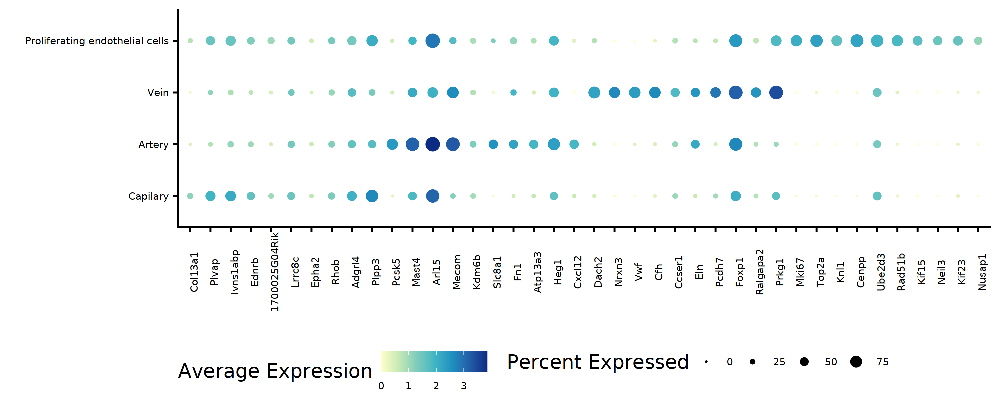

In [ ]:
aoptions(repr.plot.width = 10, repr.plot.height = 4, repr.plot.res = 300)
dtp <- DotPlot(integrated_noDBL, features = top10_predicted_noDBL$gene, col.min = 0, col.max = 4, dot.scale = 4, scale=FALSE) + theme(axis.text.x=element_text(size=7, angle = 90),axis.text.y=element_text(size=7), 
                                                                                                 legend.position = 'bottom', legend.direction = 'horizontal', 
                                                                                                  legend.text = element_text(size=7)) + xlab('') + ylab('') & scale_color_distiller(palette = "YlGnBu", direction = 1)

dtp

ggsave(file="Endothelial_integrated_noDBL_dotplot_Cell_type.svg", plot=dtp, width=10, height=6)

In [144]:
endo_noDBL_markers <- c('Plvap', 'Col13a1', 'Esm1', 'Dcbld1', 
                        'Top2a', 'Mki67', 'Birc5', 'Pclaf', 
                        'Pcsk5', 'Nebl', 'Fbln5','Slc8a1', 
                        'Vwf', 'Pcdh7', 'Lbp', 'Nr2f2')

Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_ydensity()`).”
Warning message:
“Removed 5 rows containing non-finite outside the scale range (`stat_ydensity()`).”
Warning message:
“Removed 3 rows containing non-finite outside the scale range (`stat_ydensity()`).”
Warning message:
“Removed 1 row containing non-finite outside the scale range (`stat_ydensity()`).”
Warning message:
“Removed 5 rows containing non-finite outside the scale range (`stat_ydensity()`).”
Warning message:
“Removed 3 rows containing non-finite outside the scale range (`stat_ydensity()`).”


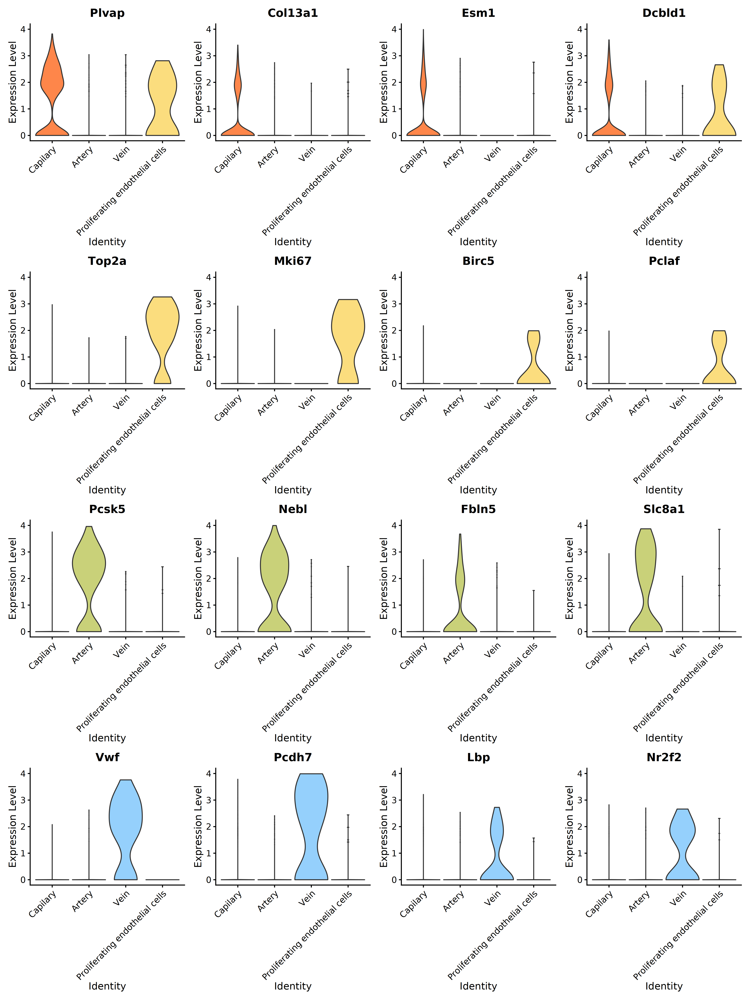

In [ ]:
options(repr.plot.width = 15, repr.plot.height = 20, repr.plot.res = 300)
vln <- VlnPlot(object = integrated_noDBL, features = endo_noDBL_markers, pt.size=0, cols = my_c, ncol = 4, y.max=4)

vln

ggsave(file="Endothelial_integrated_noDBL_vln_Cell_type.svg", plot=vln, width=15, height=20)

In [146]:
integrated_noDBL

An object of class Seurat 
215510 features across 1612 samples within 2 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: peaks
 8 dimensional reductions calculated: pca, umap_RNA, harmonyRNA, harmony_RNA, lsi, umap_peaks, harmonyPeaks, harmony_Peaks

In [ ]:
saveRDS(integrated_noDBL, 'Endothelial_integrated_multiome_celltype.rds')

In [40]:
markers <- c('Plvap', 'Col13a1', 'Esm1', 'Dcbld1', 
             'Pcsk5', 'Nebl', 'Fbln5','Slc8a1', 
             'Vwf', 'Pcdh7', 'Lbp', 'Nr2f2',
            'Top2a', 'Mki67', 'Birc5', 'Pclaf')

In [41]:
expression <- as.data.frame(t(integrated_noDBL[["RNA"]]@data[markers,]))


In [42]:
expression$Cell <- rownames(expression)
expression$Idents <- Idents(integrated_noDBL)

In [43]:
expression <- reshape2::melt(expression, id.vars = c("Cell","Idents"), measure.vars = markers,
                       variable.name = "Feat", value.name = "Expr")

In [44]:
expression$color_group <- as.factor((as.numeric(factor(expression$Feat)) - 1) %/% 4)


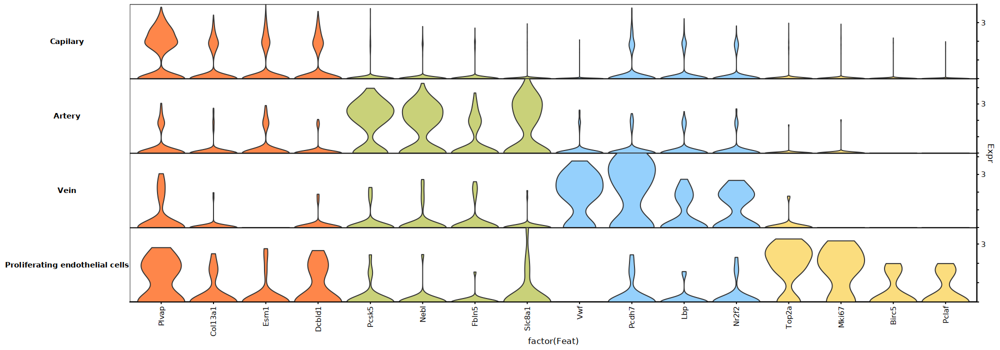

In [ ]:
options(repr.plot.width = 20, repr.plot.height = 7, repr.plot.res = 100)

# Create a grouping variable for coloring every 4 genes the same
expression$color_group <- as.factor((as.numeric(factor(expression$Feat)) - 1) %/% 4)

c <- ggplot(expression, aes(factor(Feat), Expr, fill = color_group)) +
        geom_violin(scale = "width", adjust = 1, trim = TRUE) +
        scale_y_continuous(expand = c(0, 0), position="right", labels = function(x)
                           c(rep(x = "", times = length(x)-2), x[length(x) - 1], "")) +
        facet_grid(rows = vars(Idents), scales = "free", switch = "y") +
        theme_cowplot(font_size = 12) +
        theme(legend.position = "none", panel.spacing = unit(0, "lines"),
          plot.title = element_text(hjust = 0.5),
              panel.background = element_rect(fill = NA, color = "black"),
              strip.background = element_blank(),
              strip.text = element_text(face = "bold"),
              strip.text.y.left = element_text(angle = 0),
              axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5)) + scale_fill_manual(values = my_c)

print(c)


ggsave(file="New_Last_Endothelial_noDBL_all_integrated_vln_Cell_type.svg", plot=c, width=20, height=7)

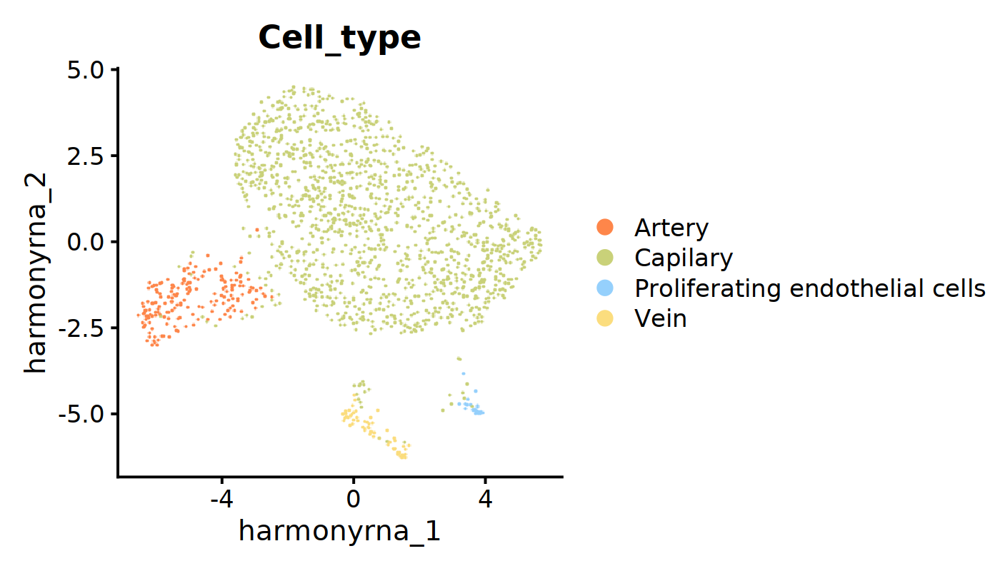

In [ ]:
options(repr.plot.width = 7, repr.plot.height = 4, repr.plot.res = 200)
dpt <- DimPlot(integrated_noDBL, group.by = "Cell_type", pt.size=2.5, raster = TRUE, cols = my_c, label = FALSE, repel = TRUE, reduction = 'harmony_RNA')

dpt

ggsave(file="Endothelial_integrated_noDBL_celltype_RNA.svg", plot=dpt, width=7, height=4)

In [167]:
DefaultAssay(integrated_noDBL) <- 'peaks'

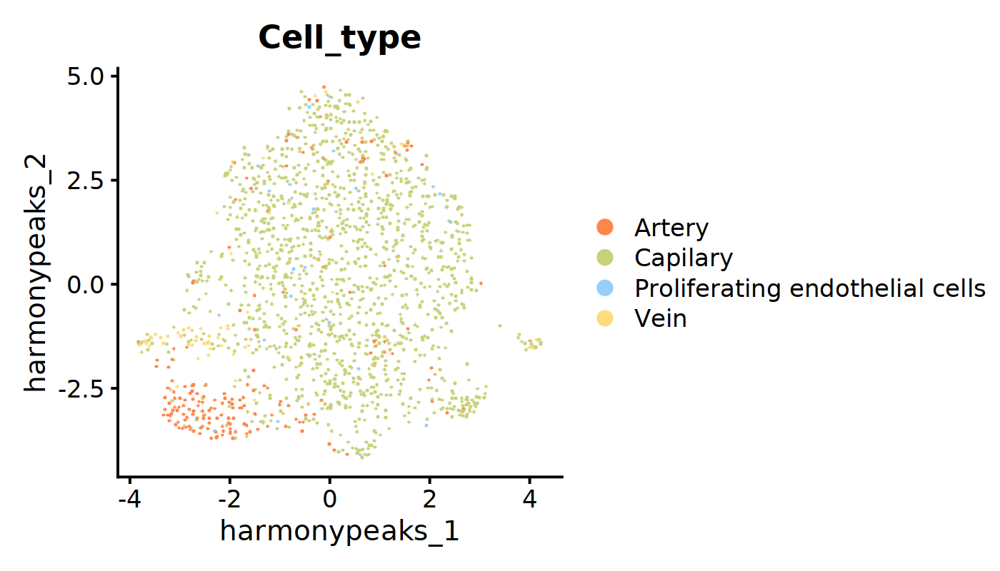

In [ ]:
options(repr.plot.width = 7, repr.plot.height = 4, repr.plot.res = 200)
dpt <- DimPlot(integrated_noDBL, group.by = "Cell_type", pt.size=2.5, raster = TRUE, cols = my_c, label = FALSE, repel = TRUE, reduction = 'harmony_Peaks')

dpt

ggsave(file="Endothelial_integrated_noDBL_celltype_peaks.svg", plot=dpt, width=7, height=4)

In [ ]:
saveRDS(integrated_noDBL, 'Endothelial_integrated_multiome_celltype.rds')

# Joint vizualization

In [ ]:
integrated_noDBL <- readRDS('Endothelial_integrated_noDBL_multiome_celltype_peaks.rds')

Warning message in gzfile(file, "rb"):
“cannot open compressed file '../../Last_multiome_data/Subclustering/Endothelial/Endothelial_integrated_noDBL_multiome_celltype.rds', probable reason 'No such file or directory'”


ERROR: Error in gzfile(file, "rb"): cannot open the connection


In [172]:
integrated_noDBL@reductions

$pca
A dimensional reduction object with key PC_ 
 Number of dimensions: 50 
 Number of cells: 1612 
 Projected dimensional reduction calculated:  FALSE 
 Jackstraw run: FALSE 
 Computed using assay: RNA 

$umap_RNA
A dimensional reduction object with key umapRNA_ 
 Number of dimensions: 2 
 Number of cells: 1612 
 Projected dimensional reduction calculated:  FALSE 
 Jackstraw run: FALSE 
 Computed using assay: RNA 

$harmonyRNA
A dimensional reduction object with key harmonyRNA_ 
 Number of dimensions: 50 
 Number of cells: 1612 
 Projected dimensional reduction calculated:  TRUE 
 Jackstraw run: FALSE 
 Computed using assay: RNA 

$harmony_RNA
A dimensional reduction object with key harmonyrna_ 
 Number of dimensions: 2 
 Number of cells: 1612 
 Projected dimensional reduction calculated:  FALSE 
 Jackstraw run: FALSE 
 Computed using assay: RNA 

$lsi
A dimensional reduction object with key LSI_ 
 Number of dimensions: 50 
 Number of cells: 1612 
 Projected dimensional reduction cal

In [171]:
integrated_noDBL <- FindMultiModalNeighbors(integrated_noDBL, reduction.list = c('harmonyRNA', 'harmonyPeaks'),
                                       dims.list = list(1:13,2:18), verbose=TRUE)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [173]:
integrated_noDBL <- RunUMAP(integrated_noDBL, nn.name = "weighted.nn", assay = "RNA", reduction.name = 'umap_multiome',  verbose = TRUE)

13:40:56 UMAP embedding parameters a = 0.9922 b = 1.112

13:40:58 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

13:41:00 Initializing from normalized Laplacian + noise (using RSpectra)

13:41:00 Commencing optimization for 500 epochs, with 43932 positive edges

13:41:03 Optimization finished



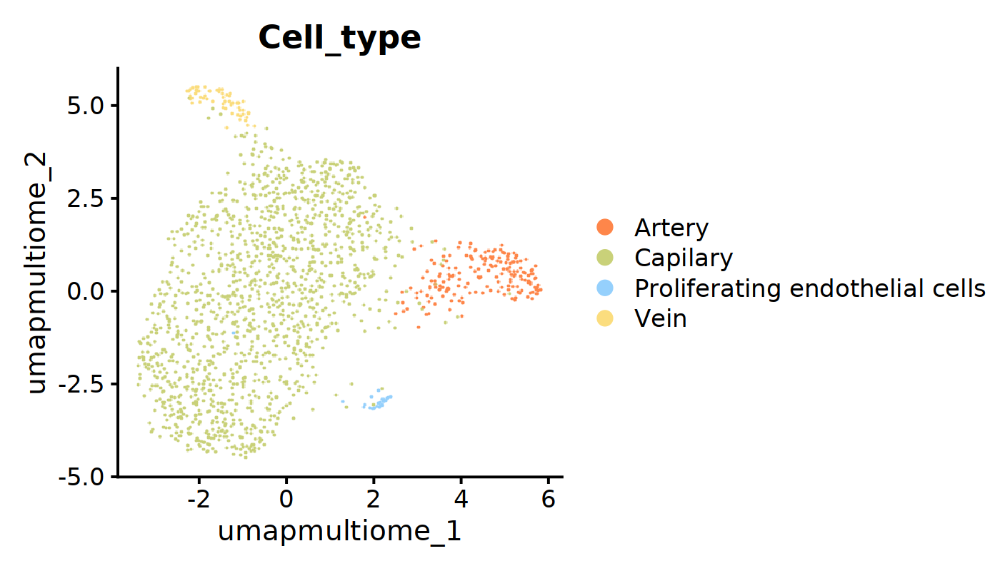

In [ ]:
options(repr.plot.width = 7, repr.plot.height = 4, repr.plot.res = 200)
dpt <- DimPlot(integrated_noDBL, group.by = "Cell_type", pt.size=2.5, raster = TRUE, cols = my_c, label = FALSE, repel = TRUE, reduction = 'umap_multiome')

dpt

ggsave(file="Endothelial_integrated_noDBL_clusters_predictedid_Multiome.svg", plot=dpt, width=7, height=5)

In [ ]:
saveRDS(integrated_noDBL, 'Endothelial_integrated_noDBL_multiome_celltype_joint.rds')

# Marker genes on different umaps assays

In [ ]:
integrated_noDBL <- readRDS('Endothelial_integrated_noDBL_multiome_celltype_joint.rds')

In [9]:
endo_noDBL_markers <- c('Plvap', 'Col13a1', 'Esm1', 'Dcbld1', 
                        'Top2a', 'Mki67', 'Birc5', 'Pclaf', 
                        'Pcsk5', 'Nebl', 'Fbln5','Slc8a1', 
                        'Vwf', 'Pcdh7', 'Lbp', 'Nr2f2')

## RNA

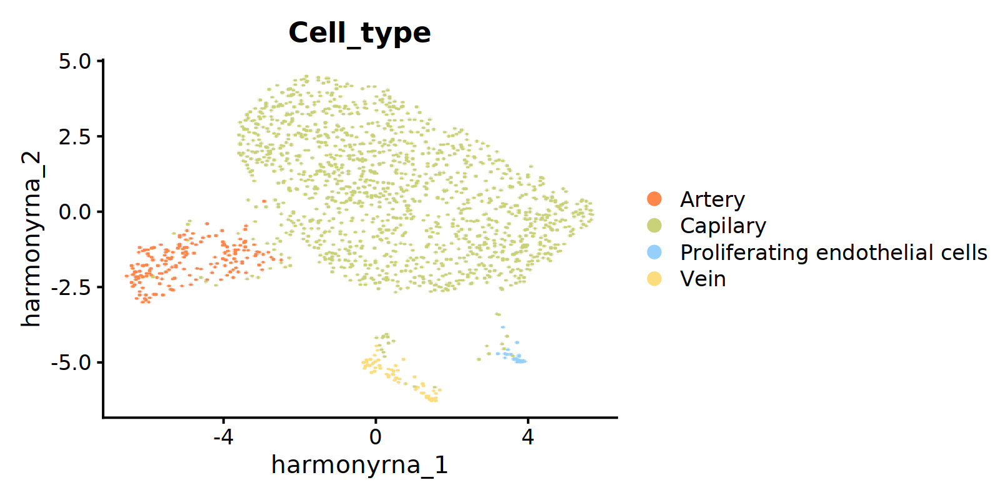

In [ ]:
options(repr.plot.width = 8, repr.plot.height = 4, repr.plot.res = 200)
dmp <- DimPlot(object = integrated_noDBL, label = FALSE,group.by='Cell_type', cols = my_c, 
               reduction = 'harmony_RNA', raster = TRUE, pt.size = 2.5)

dmp

ggsave(file="Harmony_noDBL_Cell_type_RNA_umap.svg", plot=dmp, width=8, height=4)

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is

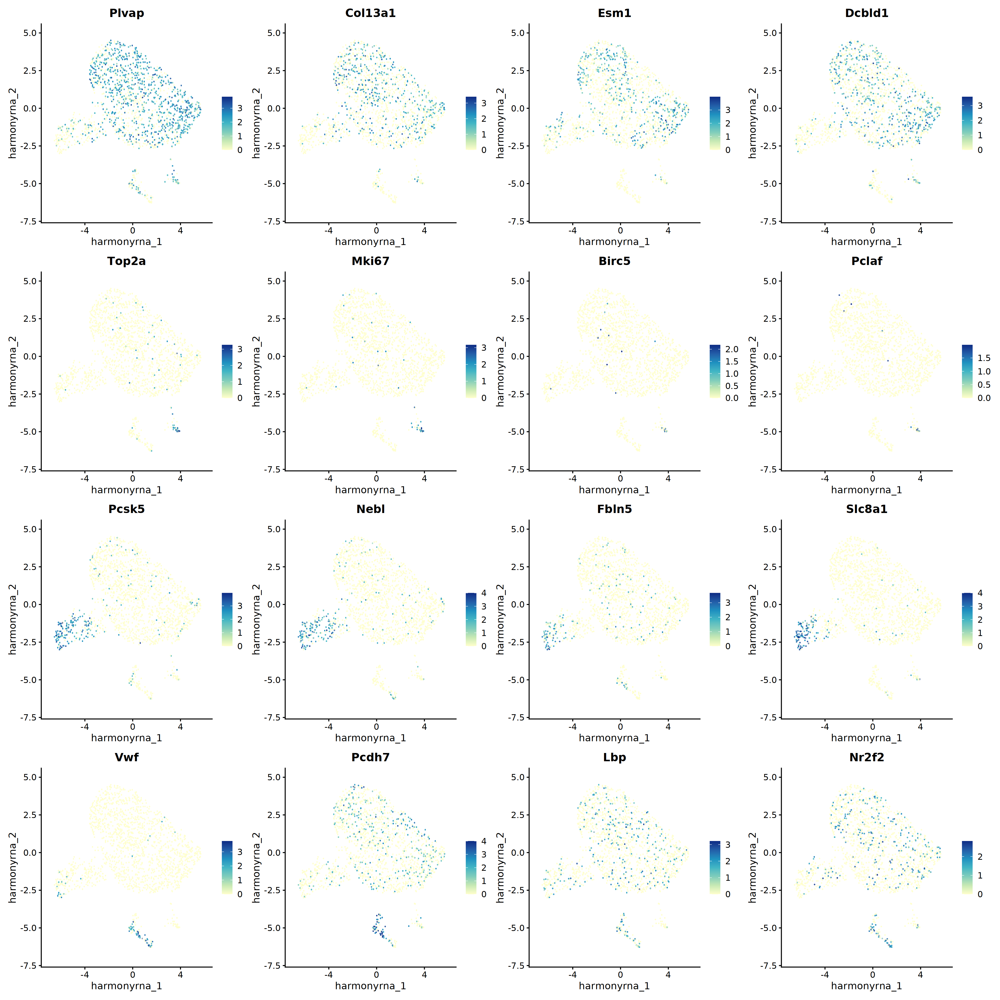

In [ ]:
options(repr.plot.width = 20, repr.plot.height = 20, repr.plot.res = 200)
ftp <- FeaturePlot(integrated_noDBL, reduction = 'harmony_RNA', features = endo_noDBL_markers, min.cutoff = 0, 
                   max.cutoff = 4, label.size = 2, ncol = 4, pt.size = 2.5, 
                   raster=TRUE) & scale_color_distiller(palette = "YlGnBu", direction = 1)
ftp 


ggsave(file="Harmony_noDBL_geneExpression_RNA_umap.svg", plot=ftp, width=20, height=20)

## Peaks

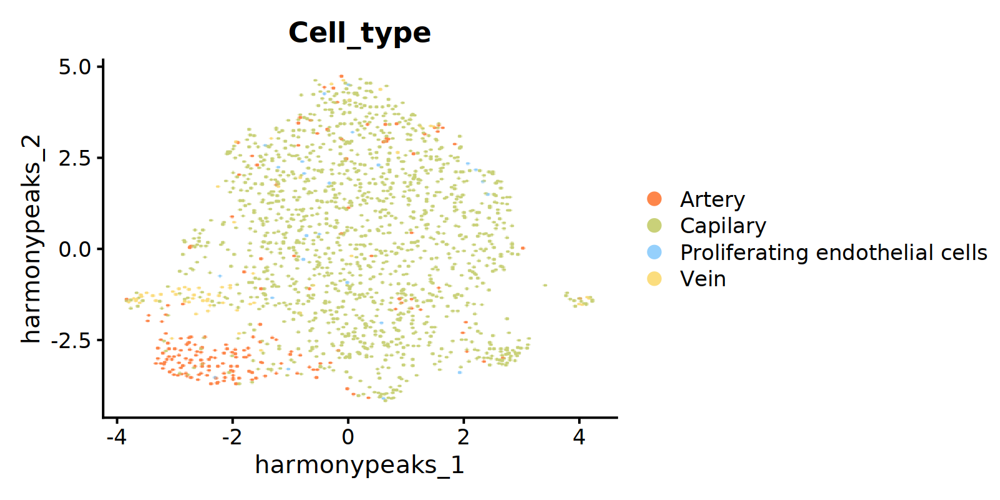

In [ ]:
options(repr.plot.width = 8, repr.plot.height = 4, repr.plot.res = 200)
dmp <- DimPlot(object = integrated_noDBL, label = FALSE,group.by='Cell_type', cols = my_c, reduction = 'harmony_Peaks', raster = TRUE, 
               pt.size = 2.5)

dmp

ggsave(file="Harmony_noDBL_Cell_type_Peaks_umap.svg", plot=dmp, width=8, height=4)

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is

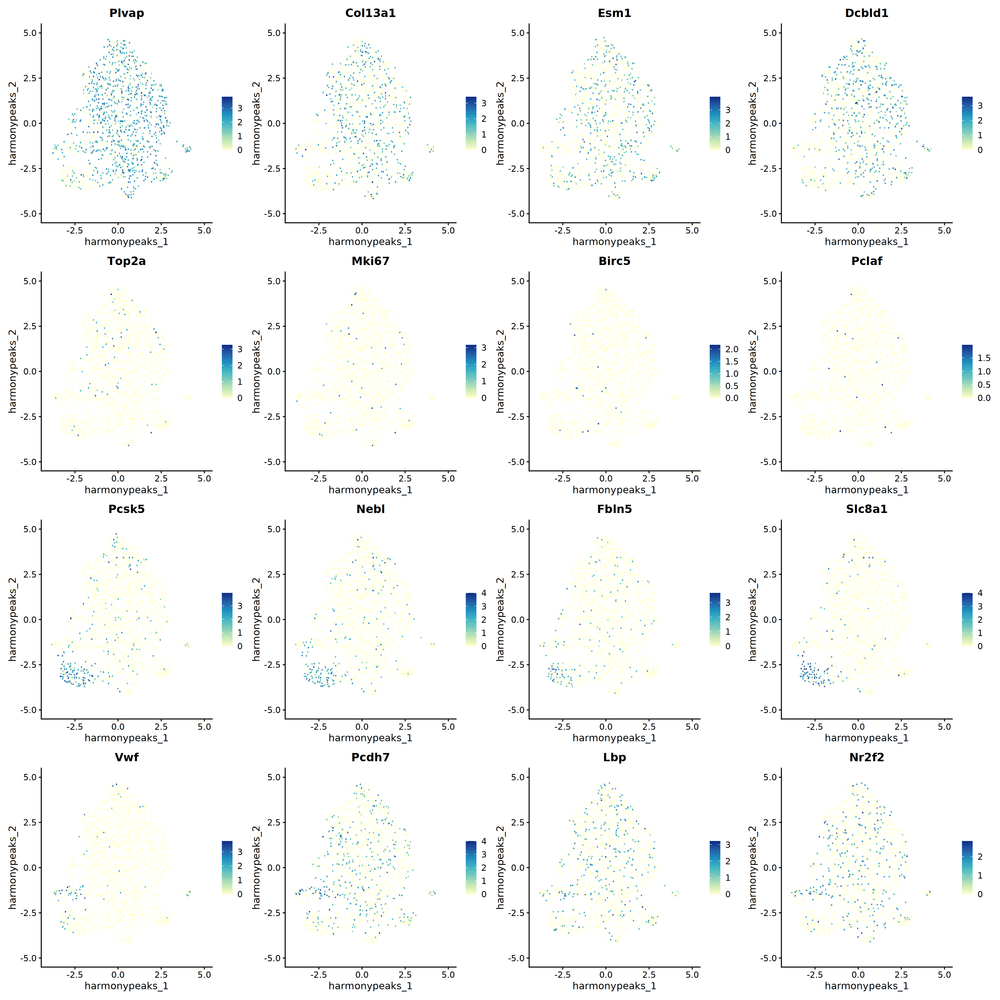

In [ ]:
options(repr.plot.width = 20, repr.plot.height = 20, repr.plot.res = 200)
ftp <- FeaturePlot(integrated_noDBL, reduction = 'harmony_Peaks', features = endo_noDBL_markers, min.cutoff = 0, 
                   max.cutoff = 4, label.size = 2, ncol = 4, pt.size = 2.5, 
                   raster=TRUE) & scale_color_distiller(palette = "YlGnBu", direction = 1)
ftp 


ggsave(file="Harmony_noDBL_geneExpression_Peaks_umap.svg", plot=ftp, width=20, height=20)

## Joint visualization

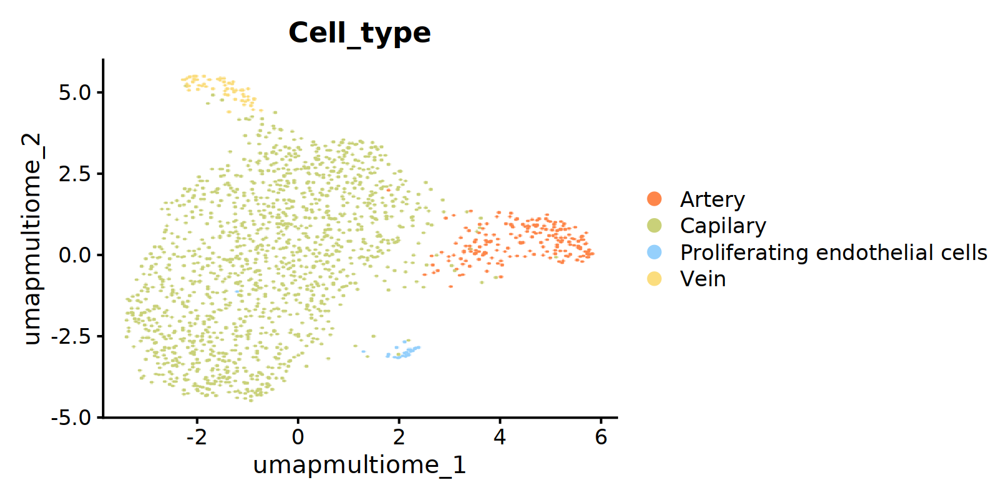

In [ ]:
options(repr.plot.width = 8, repr.plot.height = 4, repr.plot.res = 200)
dmp <- DimPlot(object = integrated_noDBL, label = FALSE,group.by='Cell_type', cols = my_c, reduction = 'umap_multiome', raster = TRUE,
               pt.size = 2.5)

dmp

ggsave(file="Harmony_noDBL_Cell_type_Joint_umap.svg", plot=dmp, width=8, height=4)

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for colour is

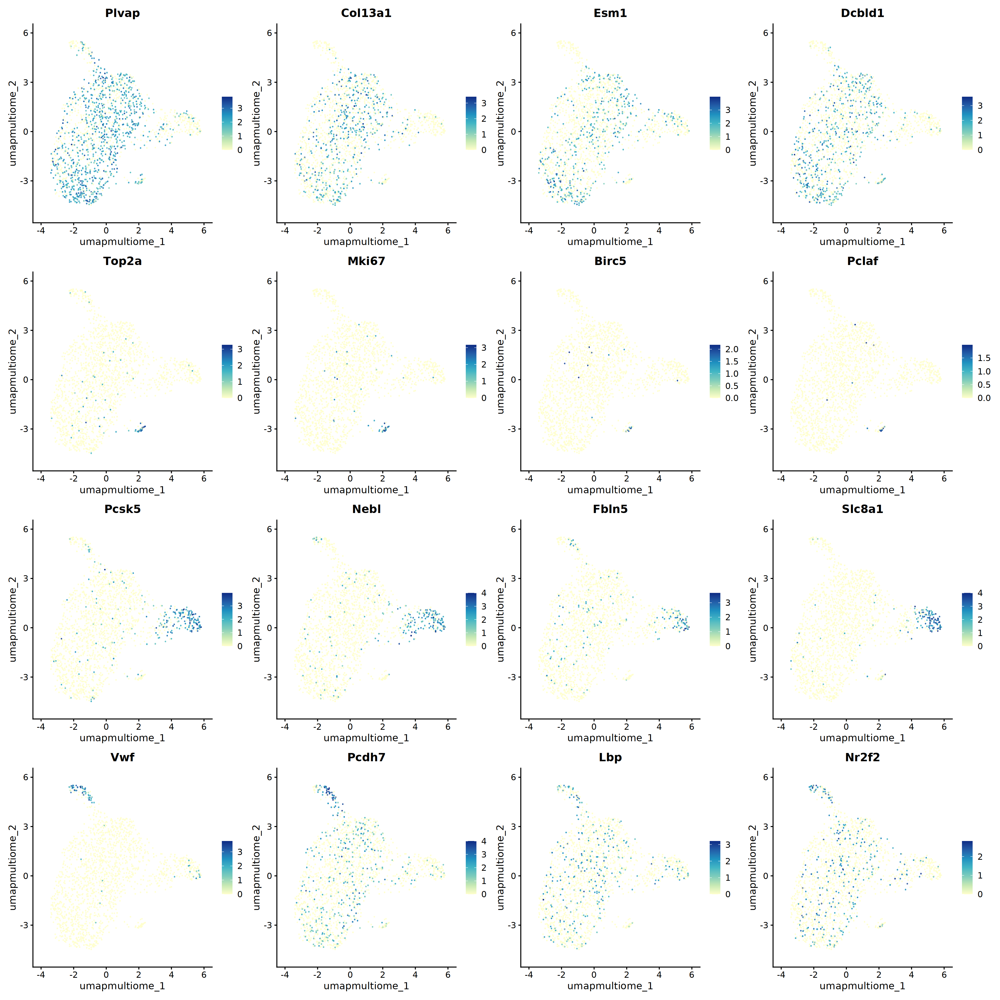

In [ ]:
options(repr.plot.width = 20, repr.plot.height = 20, repr.plot.res = 200)
ftp <- FeaturePlot(integrated_noDBL, reduction = 'umap_multiome', features = endo_noDBL_markers, min.cutoff = 0, 
                   max.cutoff = 4, label.size = 2, ncol = 4, pt.size = 2.5, 
                   raster=TRUE) & scale_color_distiller(palette = "YlGnBu", direction = 1)
ftp 


ggsave(file="Harmony_noDBL_geneExpression_Joint_umap.svg", plot=ftp, width=20, height=20)

# Linking peaks to genes

In [ ]:
Annotation(integrated_noDBL) <- annotation

In [ ]:
integrated_noDBL <- readRDS('Endothelial_integrated_noDBL_multiome_celltype_joint.rds')

In [9]:
library(BSgenome.Mmusculus.UCSC.mm10)

Loading required package: BSgenome

Warning message:
“package ‘BSgenome’ was built under R version 4.3.2”
Loading required package: Biostrings

Warning message:
“package ‘Biostrings’ was built under R version 4.3.3”
Loading required package: XVector

Warning message:
“package ‘XVector’ was built under R version 4.3.3”

Attaching package: ‘Biostrings’


The following object is masked from ‘package:base’:

    strsplit


Loading required package: BiocIO

Warning message:
“package ‘BiocIO’ was built under R version 4.3.2”

Attaching package: ‘BiocIO’


The following object is masked from ‘package:rtracklayer’:

    FileForFormat




In [10]:
DefaultAssay(integrated_noDBL) <- 'peaks'

In [11]:
# first compute the GC content for each peak
integrated_noDBL <- RegionStats(integrated_noDBL, genome = BSgenome.Mmusculus.UCSC.mm10)

In [13]:
integrated_noDBL

An object of class Seurat 
215510 features across 1612 samples within 2 assays 
Active assay: peaks (183223 features, 29823 variable features)
 2 layers present: counts, data
 1 other assay present: RNA
 9 dimensional reductions calculated: pca, umap_RNA, harmonyRNA, harmony_RNA, lsi, umap_peaks, harmonyPeaks, harmony_Peaks, umap_multiome

In [14]:
integrated_noDBL <- LinkPeaks(integrated_noDBL, peak.assay = "peaks", expression.assay = "RNA")

Testing 12067 genes and 29416 peaks



In [15]:
integrated_noDBL

An object of class Seurat 
215510 features across 1612 samples within 2 assays 
Active assay: peaks (183223 features, 29823 variable features)
 2 layers present: counts, data
 1 other assay present: RNA
 9 dimensional reductions calculated: pca, umap_RNA, harmonyRNA, harmony_RNA, lsi, umap_peaks, harmonyPeaks, harmony_Peaks, umap_multiome

In [ ]:
saveRDS(integrated_noDBL, 'Endothelial_integrated_noDBL_multiome_celltype_joint_linked.rds')

# Find DA peaks

In [ ]:
integrated_noDBL <- readRDS('Endothelial_integrated_noDBL_multiome_celltype_joint_linked.rds')

## Cell types

In [14]:
DefaultAssay(integrated_noDBL) <- 'peaks'
Idents(integrated_noDBL) <- "Cell_type"

In [16]:
da_peaks <- FindAllMarkers(
  object = integrated_noDBL,
  test.use = 'LR',
  min.pct = 0.1
)

Calculating cluster Capilary

Calculating cluster Artery

Calculating cluster Vein

Calculating cluster Proliferating endothelial cells

Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:

In [ ]:
da_peaks <- da_peaks[da_peaks$p_val_adj < 0.05, ]

In [ ]:
write.csv(da_peaks, 'DA_peaks_endo.csv')

## Condition

In [10]:
Idents(integrated_noDBL) <- "Age"

### Wilcox

In [11]:
da_peaks_age <- FindAllMarkers(
  object = integrated_noDBL,
  assay = 'peaks',
  test.use = 'wilcox',
  min.pct = 0.01
)

Calculating cluster P11

Calculating cluster P60



In [12]:
dim(da_peaks_age)

[1] 22456     7

In [13]:
head(da_peaks_age)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
chr13-21855025-21856251,8.049831e-20,-5.276236,0.002,0.081,1.474914e-14,P11,chr13-21855025-21856251
chr8-25029528-25029886,6.565668e-15,-5.348501,0.001,0.058,1.202981e-09,P11,chr8-25029528-25029886
chr14-103078109-103079637,1.009589e-13,-6.137294,0.001,0.047,1.849799e-08,P11,chr14-103078109-103079637
chr15-64421324-64422170,1.638868e-13,-2.658750,0.026,0.174,3.002784e-08,P11,chr15-64421324-64422170
chr1-106375798-106376265,2.899160e-13,-11.333715,0.000,0.035,5.311928e-08,P11,chr1-106375798-106376265
chr10-75118381-75118700,2.899160e-13,-11.286911,0.000,0.035,5.311928e-08,P11,chr10-75118381-75118700


In [14]:
da_peaks_age <- da_peaks_age[da_peaks_age$p_val_adj < 0.05, ]

In [ ]:
write.csv(da_peaks_age, 'DA_peaks_endo_age_V2.csv')

In [16]:
dim(da_peaks_age)

[1] 600   7

In [17]:
p11_peaks <- subset(da_peaks_age, cluster == 'P11')

In [18]:
dim(p11_peaks)

[1] 300   7

In [19]:
p60_peaks <- subset(da_peaks_age, cluster == 'P60')

In [20]:
dim(p60_peaks)

[1] 300   7

# General plots

## RNA

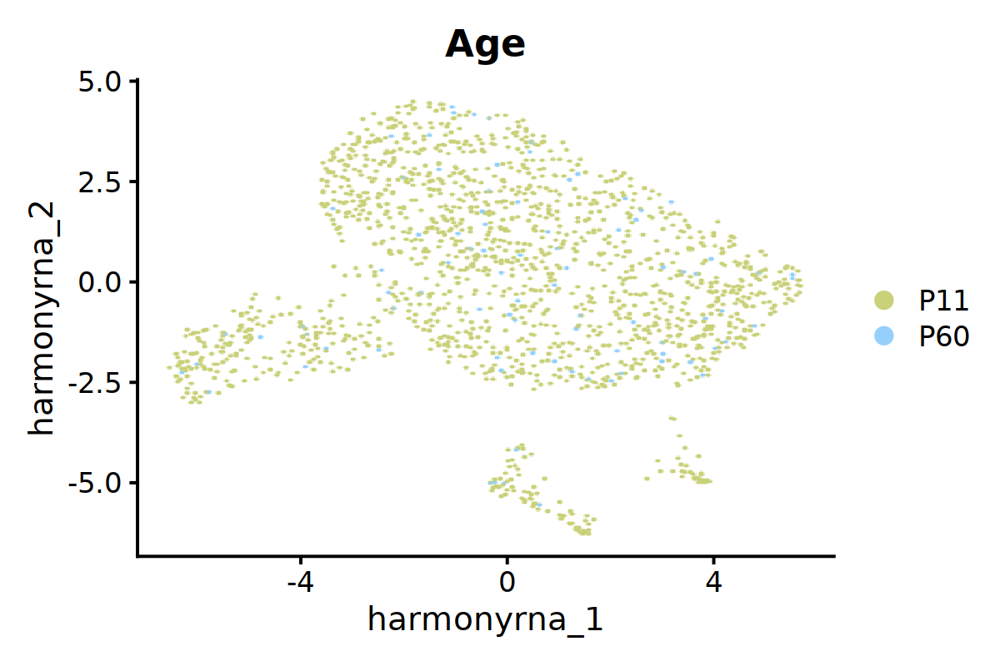

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
dmp <- DimPlot(object = integrated_noDBL, label = FALSE, cols=my_c[2:3], group.by='Age',
               reduction = 'harmony_RNA', raster = TRUE, pt.size = 2.5)

dmp

ggsave(file="Harmony_noDBL_Age_RNA_umap.svg", plot=dmp, width=6, height=4)

## Peaks

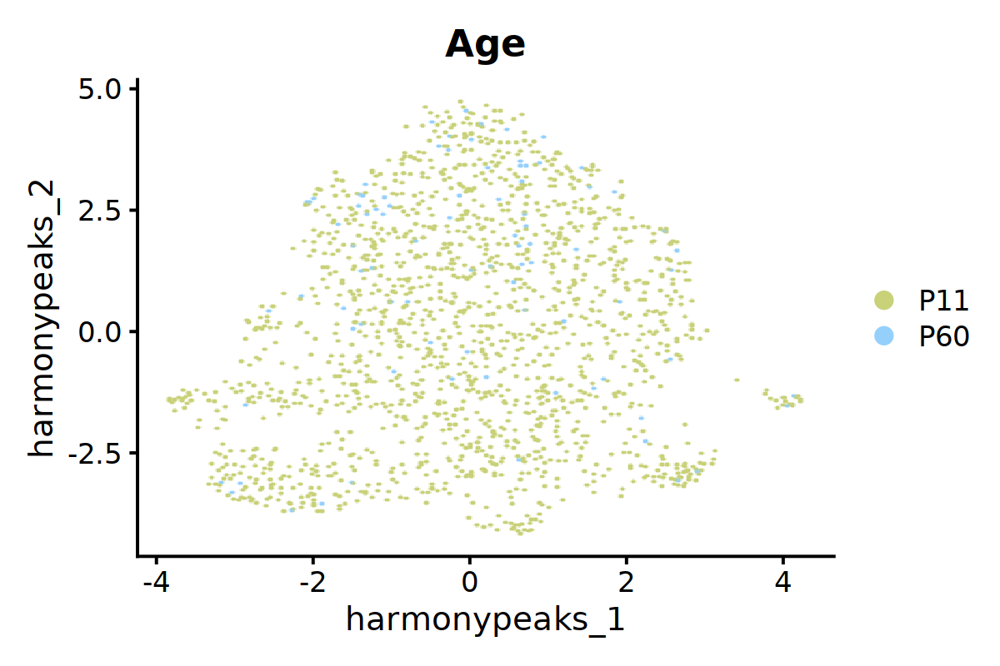

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
dmp <- DimPlot(object = integrated_noDBL, label = FALSE, cols=my_c[2:3], group.by='Age',
               reduction = 'harmony_Peaks', raster = TRUE, pt.size = 2.5)

dmp

ggsave(file="Harmony_noDBL_Age_Peaks_umap.svg", plot=dmp, width=6, height=4)

## Joint visualization

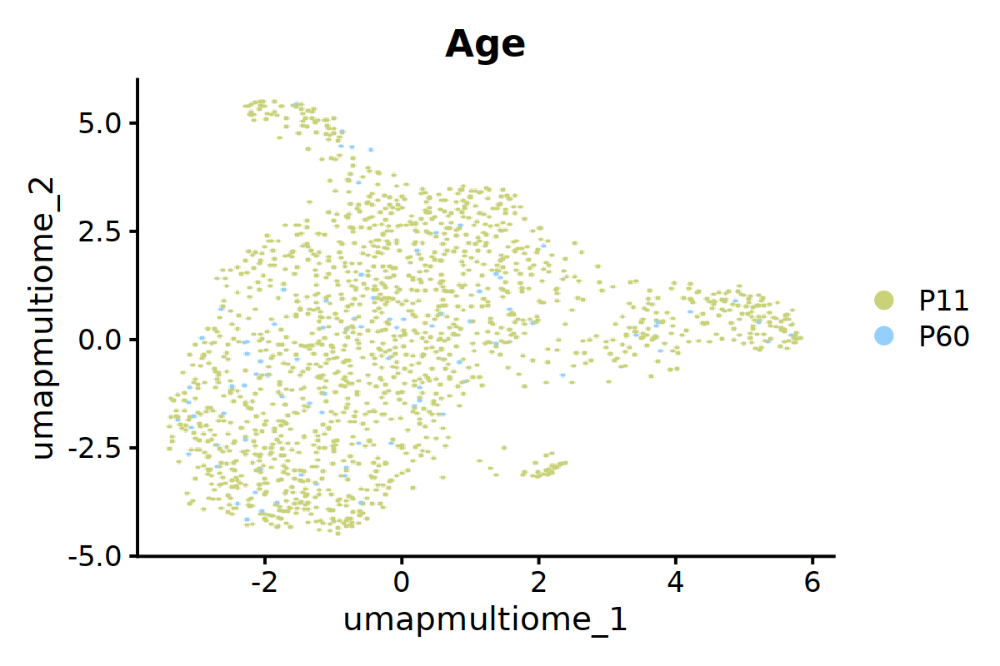

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
dmp <- DimPlot(object = integrated_noDBL, label = FALSE, cols=my_c[2:3], group.by='Age',
               reduction = 'umap_multiome', raster = TRUE, pt.size = 2.5)

dmp

ggsave(file="Harmony_noDBL_Age_Joint_umap.svg", plot=dmp, width=6, height=4)

# Plots for figures

In [ ]:
integrated_noDBL <- readRDS('Endothelial_integrated_noDBL_multiome_celltype_joint_linked.rds')

In [13]:
integrated_noDBL$log10_ngenes <- log10(integrated_noDBL$nFeature_RNA)

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


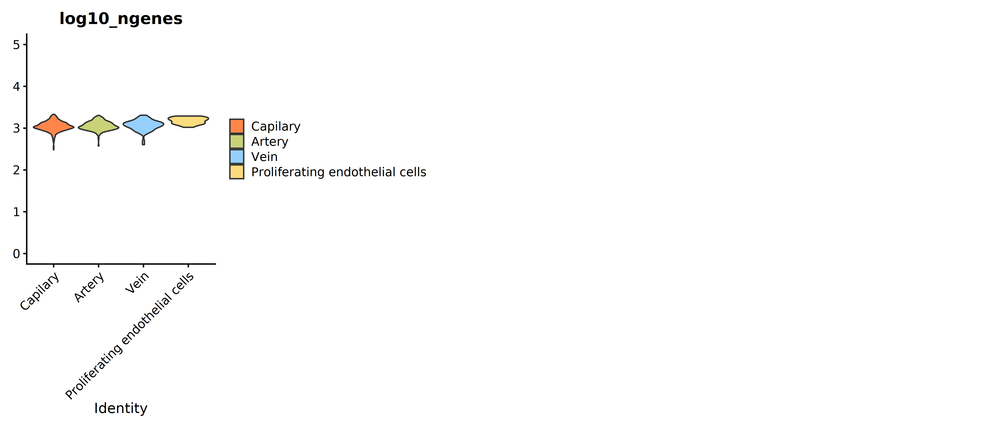

In [ ]:
options(repr.plot.width = 14, repr.plot.height = 6, repr.plot.res = 300)

vln <- VlnPlot(integrated_noDBL, features=c('log10_ngenes'),
        ncol=4, pt.size=0, col = my_c)   + scale_y_continuous(limits = c(0,5))

vln

ggsave(file="Last_noDBL_endo_integrated_all_vln_log10genes_Cell_type.svg", plot=vln, width=14, height=6)


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Warning message:
“Removed 74 rows containing non-finite outside the scale range (`stat_ydensity()`).”
Warning message:
“Removed 74 rows containing non-finite outside the scale range (`stat_ydensity()`).”


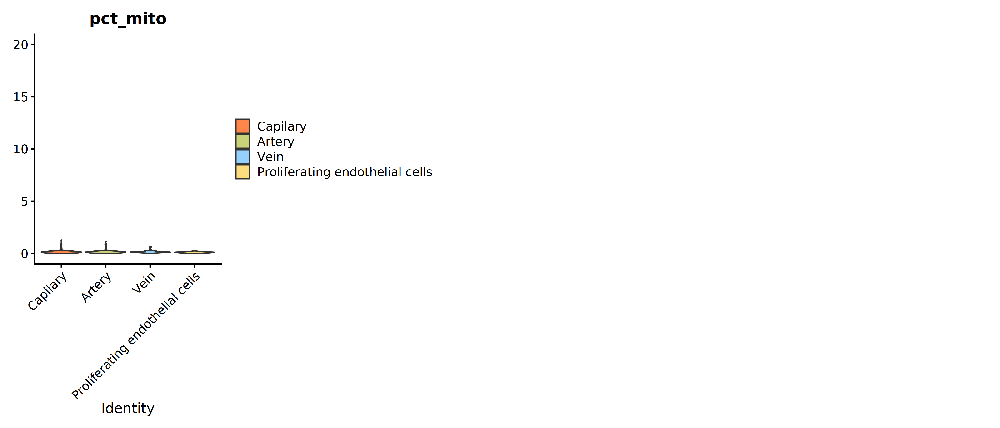

In [ ]:
options(repr.plot.width = 14, repr.plot.height = 6, repr.plot.res = 300)

vln <- VlnPlot(integrated_noDBL, features=c('pct_mito'),
        ncol=4, pt.size=0, col = my_c) + scale_y_continuous(limits = c(0,20))

vln

ggsave(file="Last_noDBL_endo_integrated_all_vln_pct_mito_Cell_type.svg", plot=vln, width=14, height=6)


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


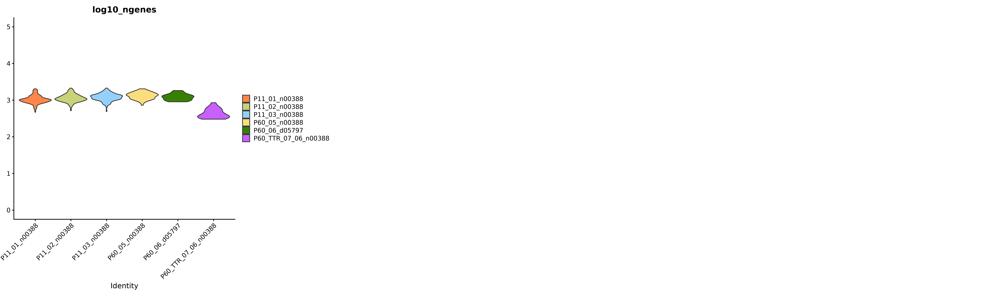

In [ ]:
options(repr.plot.width = 27, repr.plot.height = 8, repr.plot.res = 300)

vln <- VlnPlot(integrated_noDBL, features=c('log10_ngenes'), group.by = 'Sample',
        ncol=4, pt.size=0, col = my_c) + scale_y_continuous(limits = c(0,5))

vln

ggsave(file="Last_noDBL_endo_integrated_all_vln_log10genes_Sample.svg", plot=vln, width=27, height=8)


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Warning message:
“Removed 74 rows containing non-finite outside the scale range (`stat_ydensity()`).”
Warning message:
“Removed 74 rows containing non-finite outside the scale range (`stat_ydensity()`).”


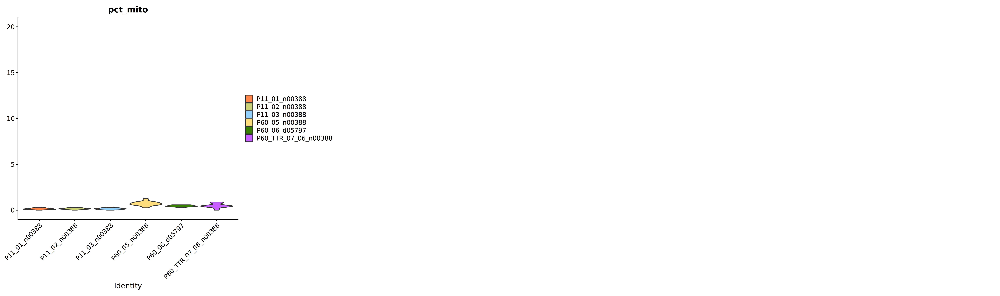

In [ ]:
options(repr.plot.width = 27, repr.plot.height = 8, repr.plot.res = 300)

vln <- VlnPlot(integrated_noDBL, features=c('pct_mito'), group.by = 'Sample',
        ncol=4, pt.size=0, col = my_c)  + scale_y_continuous(limits = c(0,20))

vln

ggsave(file="Last_noDBL_endo_integrated_all_vln_pct_mito_Sample.svg", plot=vln, width=27, height=8)


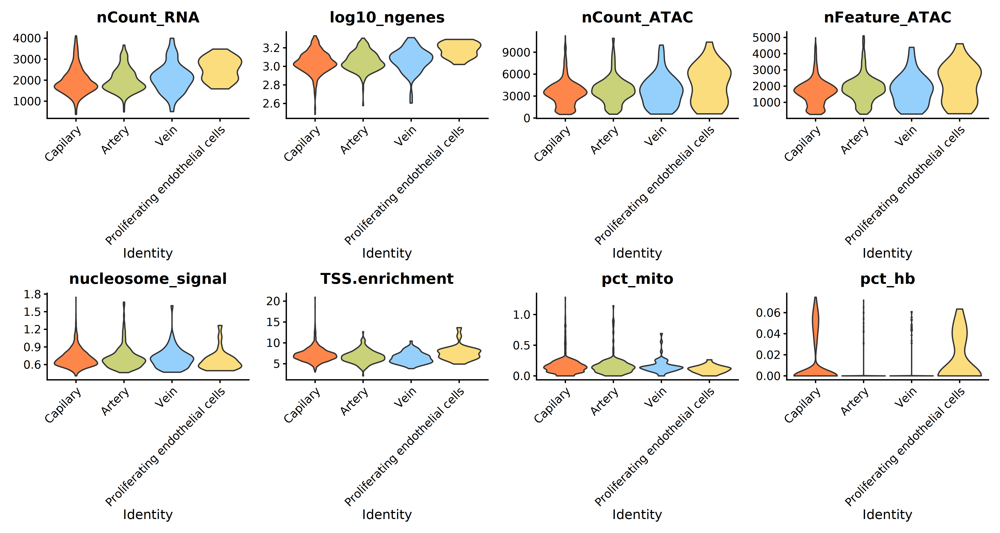

In [ ]:
options(repr.plot.width = 15, repr.plot.height = 8, repr.plot.res = 300)

vln <- VlnPlot(integrated_noDBL, features=c('nCount_RNA', 'log10_ngenes', 'nCount_ATAC', 'nFeature_ATAC', 'nucleosome_signal', 'TSS.enrichment', 'pct_mito', 'pct_hb'), 
        ncol=4, pt.size=0, col = my_c) 

vln

ggsave(file="noDBL_endo_integrated_all_vln_log10genes_pct_mito_all.svg", plot=vln, width=15, height=8)


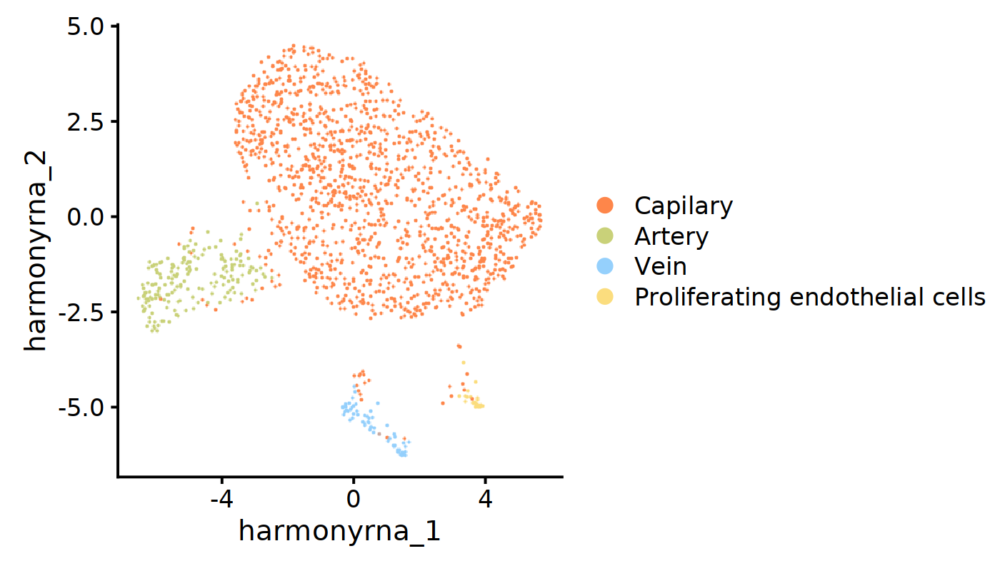

In [ ]:
options(repr.plot.width = 7, repr.plot.height = 4, repr.plot.res = 200)
dmp <- DimPlot(object = integrated_noDBL, label = FALSE, cols = my_c, 
               reduction = 'harmony_RNA', raster = TRUE, pt.size = 2.5)

dmp

ggsave(file="Last_Harmony_noDBL_Cell_type_RNA_umap.svg", plot=dmp, width=7, height=4)

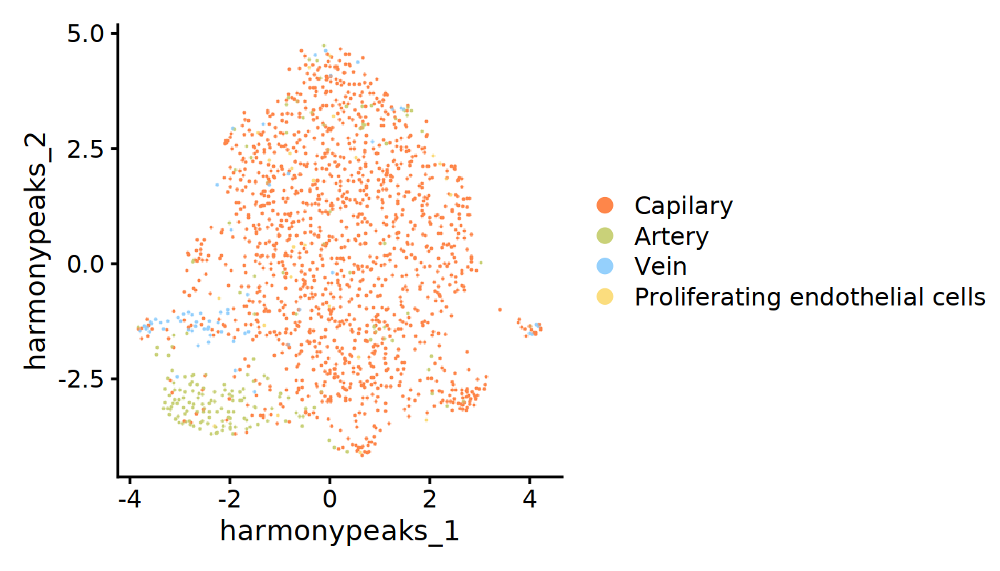

In [ ]:
options(repr.plot.width = 7, repr.plot.height = 4, repr.plot.res = 200)
dmp <- DimPlot(object = integrated_noDBL, label = FALSE, cols = my_c, 
               reduction = 'harmony_Peaks', raster = TRUE, pt.size = 2.5)

dmp

ggsave(file="Last_Harmony_noDBL_Cell_type_peaks_umap.svg", plot=dmp, width=7, height=4)

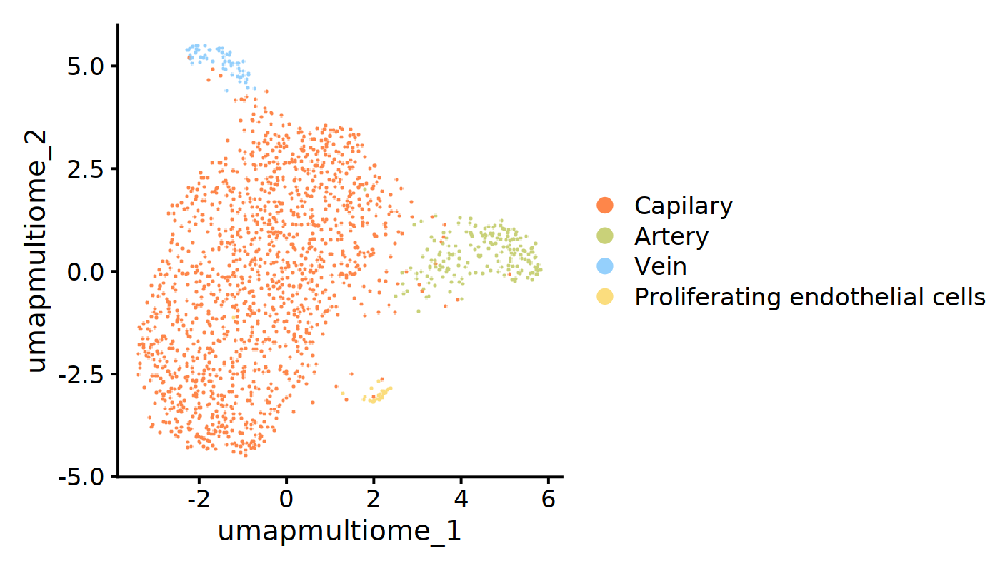

In [ ]:
options(repr.plot.width = 7, repr.plot.height = 4, repr.plot.res = 200)
dmp <- DimPlot(object = integrated_noDBL, label = FALSE, cols = my_c, 
               reduction = 'umap_multiome', raster = TRUE, pt.size = 2.5)

dmp

ggsave(file="Last_Harmony_noDBL_Cell_type_joint_umap.svg", plot=dmp, width=7, height=4)

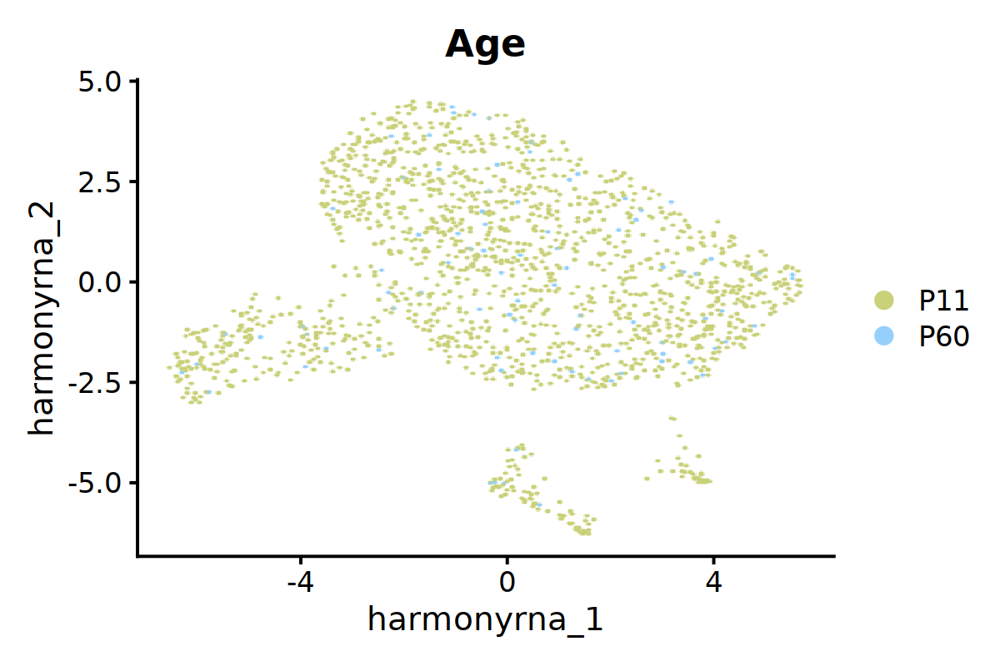

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
dmp <- DimPlot(object = integrated_noDBL, label = FALSE,group.by='Age', cols = my_c, 
               reduction = 'harmony_RNA', raster = TRUE, pt.size = 2.5)

dmp

ggsave(file="Harmony_noDBL_Age_RNA_umap.svg", plot=dmp, width=6, height=4)

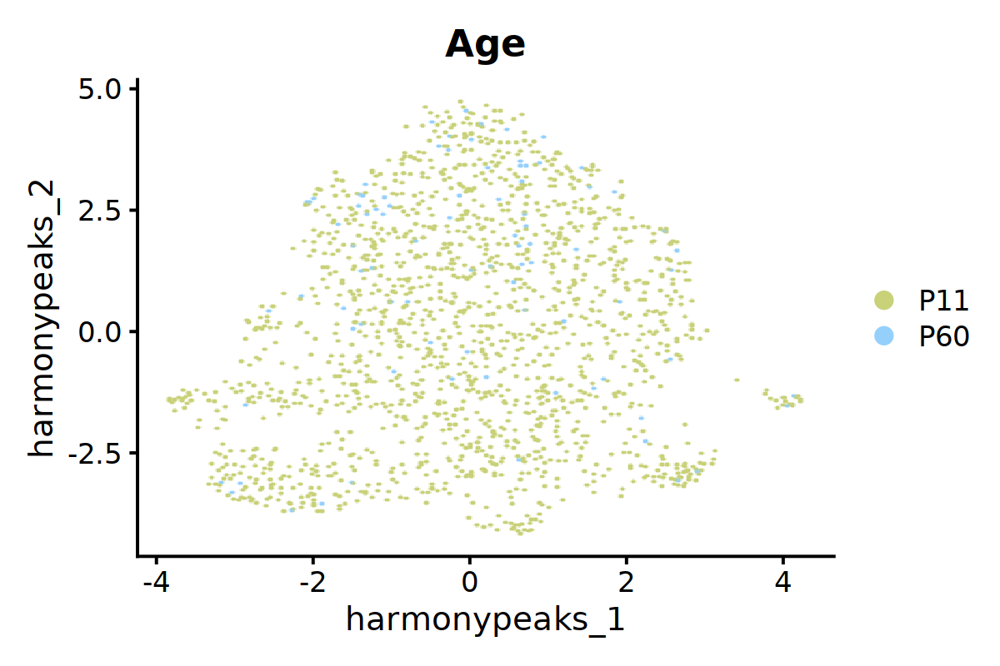

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
dmp <- DimPlot(object = integrated_noDBL, label = FALSE,group.by='Age', cols = my_c[2:3], 
               reduction = 'harmony_Peaks', raster = TRUE, pt.size = 2.5)

dmp

ggsave(file="Harmony_noDBL_Age_peaks_umap.svg", plot=dmp, width=6, height=4)

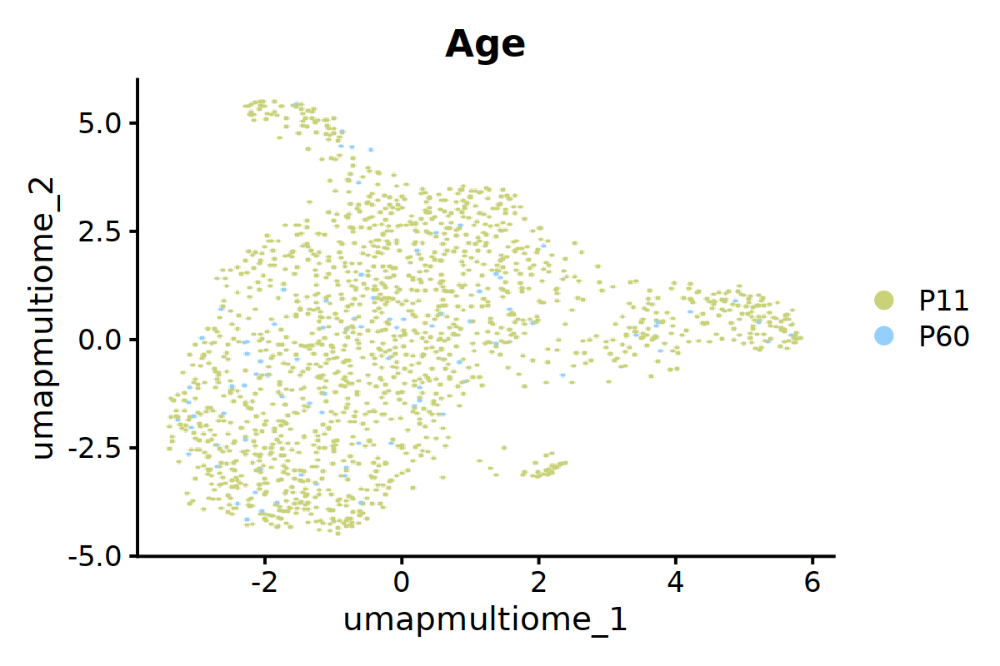

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
dmp <- DimPlot(object = integrated_noDBL, label = FALSE,group.by='Age', cols = my_c[2:3], 
               reduction = 'umap_multiome', raster = TRUE, pt.size = 2.5)

dmp

ggsave(file="Harmony_noDBL_Age_joint_umap.svg", plot=dmp, width=6, height=4)

## Highlight DA peaks

### Plvap

Warning message:
“Removed 54 rows containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 54 rows containing missing values or values outside the scale range (`geom_segment()`).”


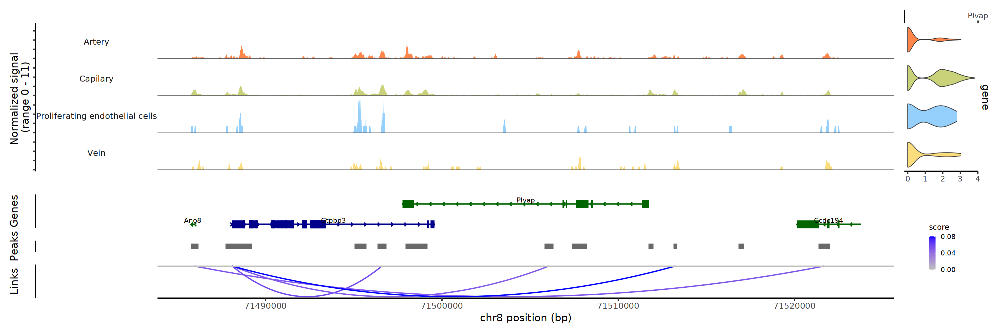

In [ ]:
cvp <- CoveragePlot(integrated_noDBL, region = 'Plvap', feature = 'Plvap', group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 12000, 
                        extend.downstream = 12000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("Resivion_no_highlight_Last_noDBL_", 'Vcam1', "_igv_tracks.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

### Nebl

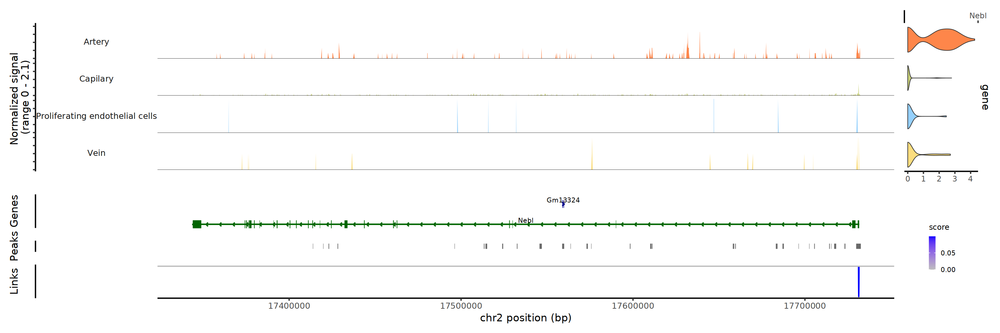

In [ ]:
cvp <- CoveragePlot(integrated_noDBL, region = 'Nebl', feature = 'Nebl', group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 1000, 
                        extend.downstream = 1000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("Resivion_no_highlight_Last_noDBL_", 'Nebl', "_igv_tracks.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

### Vwf

In [79]:
regions <- c('chr6-125596649-125597261')

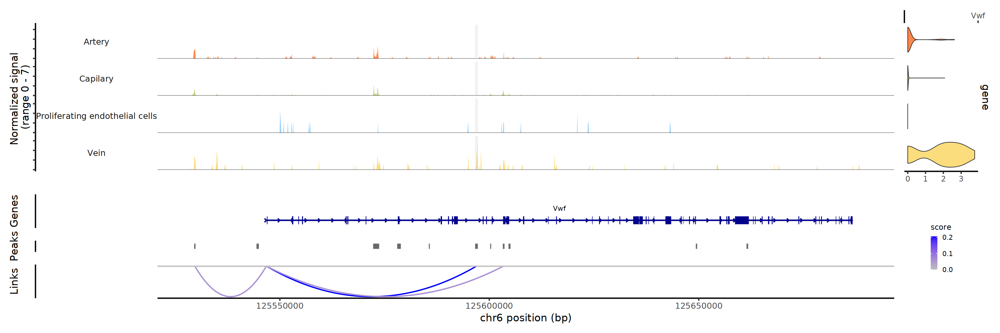

In [ ]:
ranges.show <- StringToGRanges(regions)

cvp <- CoveragePlot(integrated_noDBL, region = 'Vwf', feature = 'Vwf', region.highlight = ranges.show, group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 18000, 
                        extend.downstream = 2000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("Resivion_highlight_Last_noDBL_", 'Vwf', "_igv_tracks.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

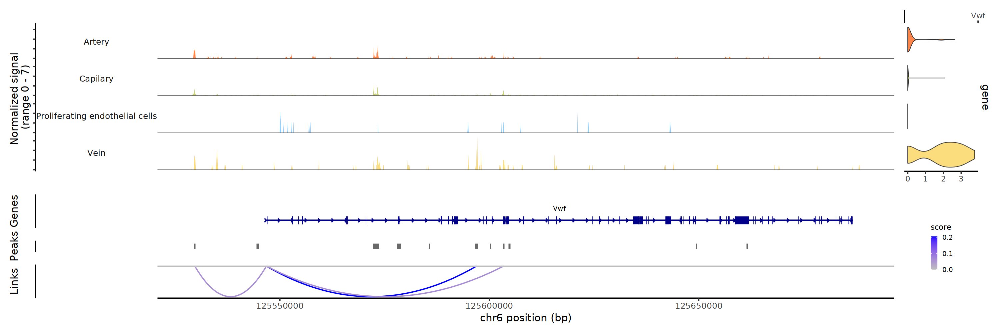

In [ ]:
cvp <- CoveragePlot(integrated_noDBL, region = 'Vwf', feature = 'Vwf', group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 18000, 
                        extend.downstream = 2000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("Resivion_no_highlight_Last_noDBL_", 'Vwf', "_igv_tracks.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

## Peaks by Age

### Aldh2

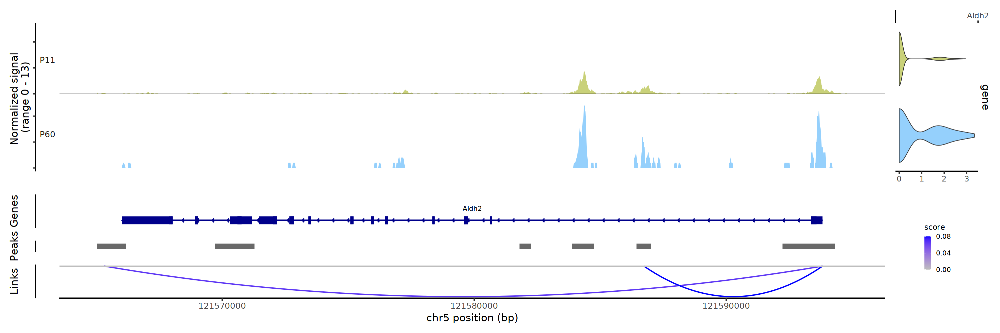

In [ ]:
cvp <- CoveragePlot(integrated_noDBL, region = 'Aldh2', feature = 'Aldh2', group.by = 'Age',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 1000, 
                        extend.downstream = 1000, ncol=1) & scale_fill_manual(values = c(my_c[2], my_c[3]))
    
    print(cvp)
    
    plot_name = paste0("Age_Resivion_no_highlight_Last_noDBL_", 'Aldh2', "_igv_tracks_endo.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

### Pde4d

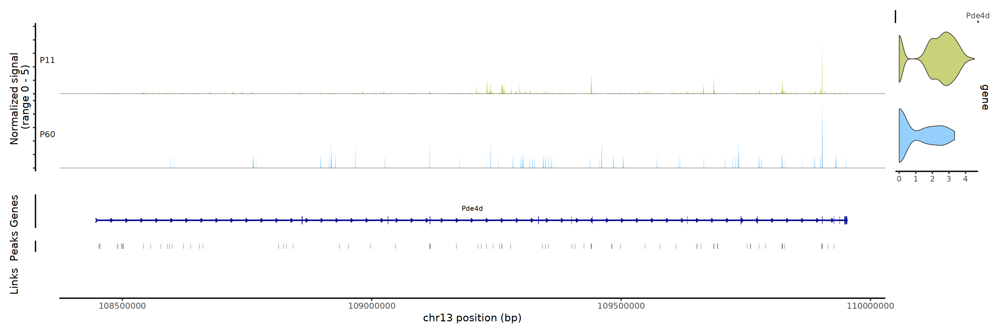

In [ ]:
cvp <- CoveragePlot(integrated_noDBL, region = 'Pde4d', feature = 'Pde4d', group.by = 'Age',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 1000, 
                        extend.downstream = 1000, ncol=1) & scale_fill_manual(values = c(my_c[2], my_c[3]))
    
    print(cvp)
    
    plot_name = paste0("Age_Resivion_no_highlight_Last_noDBL_", 'Pde4d', "_igv_tracks_endo.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

# Xist counts to try to separate male and female cells 

In [ ]:
integrated_noDBL <- readRDS('Endothelial_integrated_noDBL_multiome_celltype_joint_linked.rds')

In [10]:
DefaultAssay(integrated_noDBL) <- 'RNA'

In [11]:
integrated_noDBL

An object of class Seurat 
216256 features across 1612 samples within 3 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 2 other assays present: peaks, chromvar
 9 dimensional reductions calculated: pca, umap_RNA, harmonyRNA, harmony_RNA, lsi, umap_peaks, harmonyPeaks, harmony_Peaks, umap_multiome

In [13]:
xist_counts <- GetAssayData(integrated_noDBL, assay = "RNA", layer = "counts")[ "Xist",]

In [14]:
integrated_noDBL$'Xist-counts' <- xist_counts

In [16]:
integrated_noDBL$'Female' <- integrated_noDBL$`Xist-counts` > 0

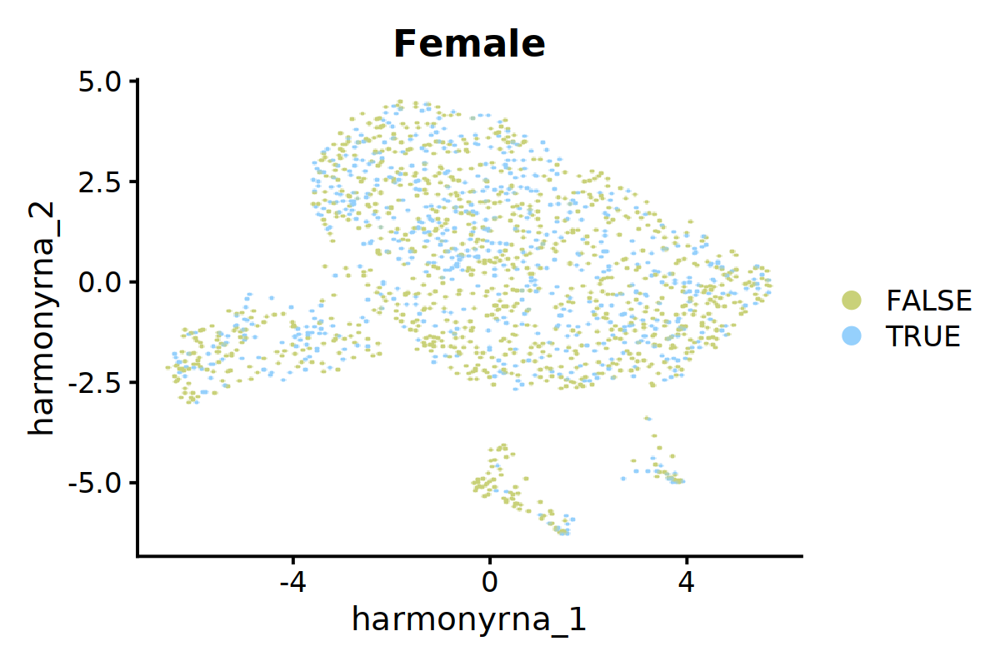

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
dmp <- DimPlot(object = integrated_noDBL, label = FALSE,group.by='Female', cols = my_c[2:3], 
               reduction = 'harmony_RNA', raster = TRUE, pt.size = 2.5)

dmp

ggsave(file="Gender_inference_Harmony_noDB_RNA_umap_endo.svg", plot=dmp, width=6, height=4)

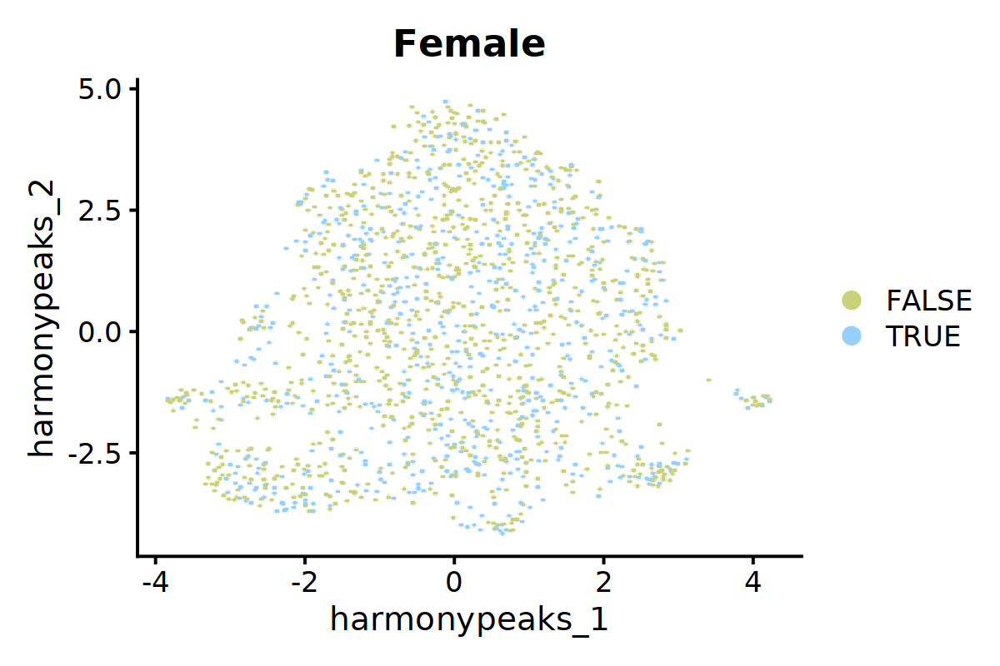

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
dmp <- DimPlot(object = integrated_noDBL, label = FALSE,group.by='Female', cols = my_c[2:3], 
               reduction = 'harmony_Peaks', raster = TRUE, pt.size = 2.5)

dmp

ggsave(file="Gender_inference_Harmony_noDBL_peaks_umap_endo.svg", plot=dmp, width=6, height=4)

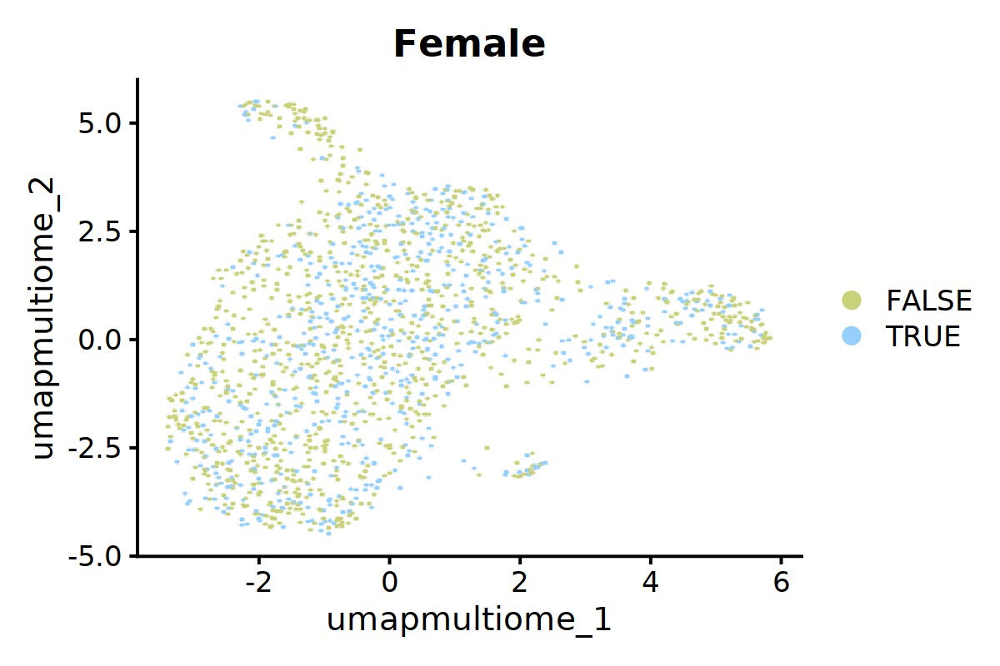

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
dmp <- DimPlot(object = integrated_noDBL, label = FALSE,group.by='Female', cols = my_c[2:3], 
               reduction = 'umap_multiome', raster = TRUE, pt.size = 2.5)

dmp

ggsave(file="Gender_inference_Harmony_noDBL_joint_umap_endo.svg", plot=dmp, width=6, height=4)

# Session info

In [33]:
sessionInfo()

R version 4.3.1 (2023-06-16)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: Debian GNU/Linux 12 (bookworm)

Matrix products: default
BLAS/LAPACK: /opt/conda/envs/multiome_env2/lib/libopenblasp-r0.3.27.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

time zone: Etc/UTC
tzcode source: system (glibc)

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] stringr_1.5.1        RColorBrewer_1.1-3   DoubletFinder_2.0.4 
 [4] biomaRt_2.58.0       cowplot_1.1.3        ggplot2_3.5.1       
 [7] Matrix_1.6-5         dplyr_1.1.4          rtracklayer_1.62.0  
[10] GenomicRanges_1.54.1 GenomeInfoDb_1.38.1  IRanges_2.36.0   